# Set UP

In [6]:
# =============================================================================
# SETUP
# =============================================================================


%pip install -q scikit-posthocs umap-learn

import os
import glob
import hashlib
import io
import json
import platform
from pathlib import Path
from datetime import datetime
from typing import List, Dict, Tuple

import numpy as np
import pandas as pd
import networkx as nx
import scipy
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

print("python     :", platform.python_version())
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("scipy      :", scipy.__version__)
print("networkx   :", nx.__version__)
print("matplotlib :", matplotlib.__version__)
print("seaborn    :", sns.__version__)

python     : 3.13.18
numpy      : 2.4.6
pandas     : 2.2.3
scipy      : 1.16.3
networkx   : 3.7
matplotlib : 3.10.0
seaborn    : 0.13.2


In [7]:
# =============================================================================
# DETERMINISM
# =============================================================================
# One global seed. The permutation tests set their own seeds internally
# (random_state=i / np.random.seed(i)), so this does not affect them.
# It does fix the strip-plot jitter, which was previously unseeded and made
# every figure render slightly differently.

GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)

matplotlib.rcParams["svg.hashsalt"] = "mea-tumor-2026"   # stable SVG element ids
matplotlib.rcParams["pdf.fonttype"] = 42                 # TrueType, editable in Affinity
matplotlib.rcParams["ps.fonttype"] = 42

def reset_seed(seed=GLOBAL_SEED):
    """Call before any plotting block that uses jitter, to keep figures stable."""
    np.random.seed(seed)

In [8]:
# =============================================================================
# REPRODUCIBILITY FINGERPRINTING
# =============================================================================
# Hash the CONTENT of results, not the saved files. Saved SVG/PDF/PNG embed a
# creation timestamp, so their bytes differ on every run even when the figure
# is pixel-identical.

FINGERPRINTS = {}

def _sha256(data_bytes):
    return hashlib.sha256(data_bytes).hexdigest()

def hash_dataframe(df):
    """Canonical hash of a DataFrame: fixed float precision, index included."""
    buf = io.StringIO()
    df.to_csv(buf, float_format="%.12g", index=True)
    return _sha256(buf.getvalue().encode("utf-8"))

def hash_array(arr):
    a = np.ascontiguousarray(np.asarray(arr, dtype=np.float64))
    return _sha256(a.tobytes())

def hash_scalar(x):
    return _sha256(f"{float(x):.12g}".encode("utf-8"))

def hash_figure(fig):
    """Hash rendered pixels. Timestamp-free, unlike hashing a saved file."""
    fig.canvas.draw()
    return _sha256(np.asarray(fig.canvas.buffer_rgba()).tobytes())

def hash_file(path):
    with open(path, "rb") as fh:
        return _sha256(fh.read())

def hash_dict(d):
    """Recursively hash a nested results dict (DataFrames, arrays, numbers)."""
    parts = []
    for key in sorted(d.keys(), key=str):
        val = d[key]
        if isinstance(val, pd.DataFrame):
            h = hash_dataframe(val)
        elif isinstance(val, pd.Series):
            h = hash_dataframe(val.to_frame())
        elif isinstance(val, dict):
            h = hash_dict(val)
        elif isinstance(val, (list, tuple, np.ndarray)):
            try:
                h = hash_array(val)
            except (TypeError, ValueError):
                h = _sha256(repr(val).encode("utf-8"))
        elif isinstance(val, (int, float, np.number)):
            h = hash_scalar(val)
        else:
            h = _sha256(repr(val).encode("utf-8"))
        parts.append(f"{key}:{h}")
    return _sha256("|".join(parts).encode("utf-8"))

def record(name, obj):
    """Fingerprint any result object under a label. Returns obj unchanged."""
    if isinstance(obj, pd.DataFrame):
        h = hash_dataframe(obj)
    elif isinstance(obj, pd.Series):
        h = hash_dataframe(obj.to_frame())
    elif isinstance(obj, dict):
        h = hash_dict(obj)
    elif isinstance(obj, plt.Figure):
        h = hash_figure(obj)
    elif isinstance(obj, (list, tuple, np.ndarray)):
        h = hash_array(obj)
    elif isinstance(obj, (int, float, np.number)):
        h = hash_scalar(obj)
    else:
        h = _sha256(repr(obj).encode("utf-8"))

    if name in FINGERPRINTS and FINGERPRINTS[name] != h:
        print(f"  [overwrite] {name} changed within this run")
    FINGERPRINTS[name] = h
    print(f"  [hash] {name:<45s} {h[:16]}")
    return obj

def save_fingerprints(path):
    payload = {
        "created": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "n_entries": len(FINGERPRINTS),
        "versions": {
            "python": platform.python_version(),
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "scipy": scipy.__version__,
            "networkx": nx.__version__,
            "matplotlib": matplotlib.__version__,
        },
        "fingerprints": FINGERPRINTS,
    }
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as fh:
        json.dump(payload, fh, indent=2, sort_keys=True)
    print(f"\nSaved {len(FINGERPRINTS)} fingerprints -> {path}")

def compare_fingerprints(reference_path):
    """Compare the current run against a saved reference. Returns True if identical."""
    with open(reference_path) as fh:
        ref = json.load(fh)["fingerprints"]

    all_keys = sorted(set(ref) | set(FINGERPRINTS))
    same, changed, missing, added = [], [], [], []
    for k in all_keys:
        if k not in FINGERPRINTS:
            missing.append(k)
        elif k not in ref:
            added.append(k)
        elif ref[k] == FINGERPRINTS[k]:
            same.append(k)
        else:
            changed.append(k)

    print("=" * 70)
    print(f"IDENTICAL : {len(same)}")
    print(f"CHANGED   : {len(changed)}")
    print(f"MISSING   : {len(missing)}  (in reference, not produced this run)")
    print(f"NEW       : {len(added)}")
    print("=" * 70)
    for k in changed:
        print(f"  CHANGED  {k}\n     was {ref[k][:16]}\n     now {FINGERPRINTS[k][:16]}")
    for k in missing:
        print(f"  MISSING  {k}")
    for k in added:
        print(f"  NEW      {k}")

    ok = not (changed or missing)
    print("\n" + ("PASS - outputs unchanged" if ok else "FAIL - review above"))
    return ok

# Configuration

In [9]:
# =============================================================================
# CONFIGURATION
# =============================================================================

# ADJUST INPUT AND OUTPUT DIRECTORY
DATA_DIR = '...'         # folder holding *cortex*.xlsx
OUT_DIR  = '...'


FILE_PATTERN     = "*cortex*.xlsx"
PREFER_RECORDING = "spont_2"      # when a slice has spont_1 and spont_2
EDGE_THRESHOLD   = 0.1            # on min-max normalised weight
WEIGHT_ATTR      = "weight_normalized"

# Slices recorded without tumour engraftment. Membership defines `experiment`.
CONTROL_SLICE_IDS = [
    'ID2303CE003', 'ID2303CE004', 'ID2303CE038',
    'ID2307CT005', 'ID2310CT001', 'ID2310CT002', 'ID2310CT003',
    'ID2310CT004', 'ID2310CT005', 'ID2401CT047', 'ID2401CT066',
    'ID2402CT079', 'ID2403CT079', 'ID2405CT005', 'ID2405CT006',
    'ID2406CT001', 'ID2406CT002', 'ID2411CT001', 'ID2411CT002',
    'ID2412CT049', 'ID2412CT050',
]

COLORS_EXPERIMENT = {'control_slice': '#6BAED6', 'BTSC': '#2CA02C'}
COLORS_REGION     = {'control_slice': '#6BAED6', 'control': '#DADAEB',
                     'border_zone': '#A1D99B', 'BTI': '#2CA02C'}

# Load and Prepare

In [10]:
# =============================================================================
# 1. LOAD AND PREPARE
# =============================================================================

def load_mea_excel_files(directory_path, pattern=FILE_PATTERN):
    """Load per-recording Excel files. Sheet 0 = nodes, sheet 1 = edges."""
    excel_files = sorted(glob.glob(os.path.join(directory_path, pattern)))
    if not excel_files:
        raise ValueError(f"No files matching {pattern} in {directory_path}")

    nodes_dfs, edges_dfs = [], []
    print(f"Found {len(excel_files)} files")
    for file_path in excel_files:
        file_name = Path(file_path).name
        n = pd.read_excel(file_path, sheet_name=0); n['source_file'] = file_name
        e = pd.read_excel(file_path, sheet_name=1); e['source_file'] = file_name
        nodes_dfs.append(n); edges_dfs.append(e)
        print(f"  {file_name}: {len(n)} nodes, {len(e)} edges")

    return (pd.concat(nodes_dfs, ignore_index=True),
            pd.concat(edges_dfs, ignore_index=True))


def deduplicate_recordings(nodes_df, edges_df, prefer=PREFER_RECORDING):
    """Keep one recording per slice/condition, preferring spont_2."""
    all_files = nodes_df['source_file'].unique()

    groups = {}
    for f in all_files:
        ident = f.replace('_spont_1', '').replace('_spont_2', '')
        groups.setdefault(ident, []).append(f)

    keep = []
    for ident, files in groups.items():
        preferred = [f for f in files if f'_{prefer}' in f]
        keep.append(preferred[0] if preferred else files[0])

    nodes_out = nodes_df[nodes_df['source_file'].isin(keep)].copy()
    edges_out = edges_df[edges_df['source_file'].isin(keep)].copy()

    print(f"\nDeduplication: {len(all_files)} recordings -> {len(keep)}")
    print(f"  nodes {len(nodes_df):,} -> {len(nodes_out):,}")
    print(f"  edges {len(edges_df):,} -> {len(edges_out):,}")
    return nodes_out, edges_out


def classify_slices(df, control_slice_ids=CONTROL_SLICE_IDS):
    """Add `experiment` and `region_experiment` columns."""
    out = df.copy()
    out['experiment'] = out['slice_id'].apply(
        lambda s: np.nan if pd.isna(s)
        else ('control_slice' if s in control_slice_ids else 'BTSC'))

    def _combine(row):
        if pd.isna(row['region']) or pd.isna(row['experiment']):
            return np.nan
        return 'control_slice' if row['experiment'] == 'control_slice' else row['region']

    out['region_experiment'] = out.apply(_combine, axis=1)

    print("\nexperiment:");        print(out['experiment'].value_counts(dropna=False))
    print("\nregion_experiment:"); print(out['region_experiment'].value_counts(dropna=False))
    return out


nodes_data, edges_data = load_mea_excel_files(DATA_DIR)
nodes_data, edges_data = deduplicate_recordings(nodes_data, edges_data)
nodes_data = classify_slices(nodes_data)

record("01_nodes_raw", nodes_data)
record("02_edges_raw", edges_data)

Found 91 files
  2023-02-07_humancortex_div7_biometra_ID2302CE012_nodrug_spont_1_mea_graph_analysis.xlsx: 175 nodes, 2614 edges
  2023-02-07_humancortex_div7_biometra_ID2302CE012_nodrug_spont_2_mea_graph_analysis.xlsx: 216 nodes, 9130 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT001_5uMgabazine_spont_1_mea_graph_analysis.xlsx: 222 nodes, 21527 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT001_5uMgabazine_spont_2_mea_graph_analysis.xlsx: 222 nodes, 21013 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT001_8mMK_spont_1_mea_graph_analysis.xlsx: 146 nodes, 1692 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT001_8mMK_spont_2_mea_graph_analysis.xlsx: 171 nodes, 4992 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT002_5uMgabazine_spont_1_mea_graph_analysis.xlsx: 221 nodes, 23784 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT002_5uMgabazine_spont_2_mea_graph_analysis.xlsx: 224 nodes, 23797 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT002_8mMK_spont

,filename,slice_id,drug,stimulation,firing_rate_whole_recording,medium,tissue,recording_date,source_node,target_node,source_region,target_region,region_connection,weight,physical_distance_um,normalized_distance,distance_category,is_adjacent,is_long_range,source_file
2614,2023-02-07_humancortex_div7_biometra_ID2302CE0...,ID2302CE012,nodrug,none,41.783,biometra,humancortex,2023-02-07,G13,F13,BTI,BTI,BTI-BTI,1,200.000000,0.047140,adjacent,True,False,2023-02-07_humancortex_div7_biometra_ID2302CE0...
2615,2023-02-07_humancortex_div7_biometra_ID2302CE0...,ID2302CE012,nodrug,none,41.783,biometra,humancortex,2023-02-07,G13,E16,BTI,BTI,BTI-BTI,1,721.110255,0.169967,medium_range,False,False,2023-02-07_humancortex_div7_biometra_ID2302CE0...
2616,2023-02-07_humancortex_div7_biometra_ID2302CE0...,ID2302CE012,nodrug,none,41.783,biometra,humancortex,2023-02-07,G13,E15,BTI,BTI,BTI-BTI,1,565.685425,0.133333,medium_range,False,False,2023-02-07_humancortex_div7_biometra_ID2302CE0...
2617,2023-02-07_humancortex_div7_biometra_ID2302CE0...,ID2302CE012,nodrug,none,41.783,biometra,humancortex,2023-02-07,G13,E13,BTI,BTI,BTI-BTI,1,400.000000,0.094281,short_range,False,False,2023-02-07_humancortex_div7_biometra_ID2302CE0...
2618,2023-02-07_humancortex_div7_biometra_ID2302CE0...,ID2302CE012,nodrug,none,41.783,biometra,humancortex,2023-02-07,G13,G11,BTI,BTI,BTI-BTI,1,400.000000,0.094281,medium_range,False,False,2023-02-07_humancortex_div7_biometra_ID2302CE0...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049549,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,ID2411CT004,nodrug,none,15.344,biometra,cortex,2024-08-26,L9,N10,control,control,control-control,1,447.213595,0.105409,medium_range,False,False,2024-08-26_cortex_div5_biometra_ID2411CT004_no...
1049550,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,ID2411CT004,nodrug,none,15.344,biometra,cortex,2024-08-26,O11,C7,control,border_zone,border_zone-control,1,2340.939982,0.551765,long_range,False,True,2024-08-26_cortex_div5_biometra_ID2411CT004_no...
1049551,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,ID2411CT004,nodrug,none,15.344,biometra,cortex,2024-08-26,O11,H11,control,border_zone,border_zone-control,1,1200.000000,0.282843,long_range,False,True,2024-08-26_cortex_div5_biometra_ID2411CT004_no...
1049552,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,ID2411CT004,nodrug,none,15.344,biometra,cortex,2024-08-26,O16,K2,control,control,control-control,1,2912.043956,0.686375,long_range,False,True,2024-08-26_cortex_div5_biometra_ID2411CT004_no...


# Graph Construction

In [11]:
# =============================================================================
# 2. GRAPH CONSTRUCTION
# =============================================================================

def build_graph(nodes_df, edges_df, filename):
    """One weighted graph per recording. Nodes = electrodes, edges = co-active bins."""
    n_sub = nodes_df[nodes_df['filename'] == filename]
    e_sub = edges_df[edges_df['filename'] == filename]
    if len(n_sub) == 0 or len(e_sub) == 0:
        print(f"  Warning: incomplete data for {filename}")
        return None

    G = nx.Graph()
    for _, row in n_sub.iterrows():
        G.add_node(row['node_id'], **row.drop(['filename', 'node_id']).to_dict())
    for _, row in e_sub.iterrows():
        G.add_edge(row['source_node'], row['target_node'],
                   **row.drop(['filename', 'source_node', 'target_node']).to_dict())
    return G


def normalize_edge_weights(G):
    """Min-max scale raw co-activity counts to [0, 1] within this recording."""
    w = [d['weight'] for _, _, d in G.edges(data=True)]
    if not w:
        return G
    lo, hi = min(w), max(w)
    for u, v in G.edges():
        G[u][v]['weight_normalized'] = 1.0 if hi == lo else (G[u][v]['weight'] - lo) / (hi - lo)
    return G


def threshold_graph(G, threshold=EDGE_THRESHOLD, weight_attr=WEIGHT_ATTR):
    """Drop weak edges, then drop electrodes left with no connections."""
    H = G.copy()
    H.remove_edges_from([(u, v) for u, v, d in H.edges(data=True)
                         if d.get(weight_attr, 0) < threshold])
    H.remove_nodes_from(list(nx.isolates(H)))
    return H


filenames = sorted(nodes_data['filename'].unique())
print(f"Building {len(filenames)} graphs...\n")

graphs, graphs_thresholded, retention = {}, {}, []
for fn in filenames:
    G = build_graph(nodes_data, edges_data, fn)
    if G is None:
        continue
    G = normalize_edge_weights(G)
    H = threshold_graph(G)
    graphs[fn], graphs_thresholded[fn] = G, H

    retention.append({
        'filename': fn,
        'n_nodes': G.number_of_nodes(),  'n_edges': G.number_of_edges(),
        'n_nodes_thresh': H.number_of_nodes(), 'n_edges_thresh': H.number_of_edges(),
        'pct_edges_retained': 100 * H.number_of_edges() / G.number_of_edges()
                              if G.number_of_edges() else np.nan,
    })
    print(f"  {fn[:60]:<60s} {G.number_of_edges():>6d} -> {H.number_of_edges():>6d} edges")

retention_df = pd.DataFrame(retention)
record("03_graph_retention", retention_df)

print(f"\nBuilt {len(graphs)} graphs")
print(f"Mean edge retention: {retention_df['pct_edges_retained'].mean():.1f}%")

Building 49 graphs...

  2023-02-07_humancortex_div7_biometra_ID2302CE012_nodrug_spon   9130 ->    101 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT001_5uMgabazine  21013 ->   1169 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT001_8mMK_spont_   4992 ->     34 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT002_5uMgabazine  23797 ->   7971 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT002_8mMK_spont_  11999 ->    278 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT007_5uMgabazine  18500 ->   1776 edges
  2023-09-08_humancortex_div3_biometra_ID2310CT007_8mMK_spont_   4594 ->    160 edges
  2023-09-12_humancortex_div7_biometra_ID2310CT003_5uMgabazine  26710 ->  13230 edges
  2023-09-12_humancortex_div7_biometra_ID2310CT003_8mMK_spont_  25865 ->  12827 edges
  2023-09-12_humancortex_div7_biometra_ID2310CT003_nodrug_spon  25680 ->  13061 edges
  2023-09-12_humancortex_div7_biometra_ID2310CT004_5uMgabazine  13656 ->   1293 edges
  2023-09-12_humancortex_div7_b

In [12]:
# =============================================================================
# 3. NODE / EDGE TABLES
# =============================================================================

META_COLS = ['drug', 'slice_id', 'stimulation', 'medium', 'tissue',
             'recording_date', 'source_file', 'experiment', 'region_experiment']


def extract_nodes(graphs_dict, nodes_df_original):
    """Node table with graph metrics recomputed on whichever graphs are passed in."""
    rows = []
    for fn, G in graphs_dict.items():
        meta = nodes_df_original[nodes_df_original['filename'] == fn].iloc[0][META_COLS].to_dict()
        dc  = nx.degree_centrality(G)
        cc  = nx.clustering(G)
        for node in G.nodes():
            r = {'filename': fn, 'node_id': node}
            r.update(meta)
            r.update(G.nodes[node])
            r['degree'] = G.degree[node]
            r['degree_centrality'] = dc[node]
            r['clustering_coefficient'] = cc[node]
            rows.append(r)
    return pd.DataFrame(rows)


def extract_edges(graphs_dict, edges_df_original):
    """Edge table reflecting the current (possibly thresholded) graph state."""
    meta_cols = ['drug', 'slice_id', 'stimulation', 'medium',
                 'tissue', 'recording_date', 'source_file']
    rows = []
    for fn, G in graphs_dict.items():
        sub = edges_df_original[edges_df_original['filename'] == fn]
        meta = sub.iloc[0][meta_cols].to_dict() if len(sub) else {}
        if len(sub) and 'firing_rate_whole_recording' in edges_df_original.columns:
            meta['firing_rate_whole_recording'] = sub.iloc[0]['firing_rate_whole_recording']
        for u, v, d in G.edges(data=True):
            r = {'filename': fn, 'source_node': u, 'target_node': v}
            r.update(meta); r.update(d)
            rows.append(r)
    return pd.DataFrame(rows)


nodes_thresh = extract_nodes(graphs_thresholded, nodes_data)
edges_thresh = extract_edges(graphs_thresholded, edges_data)

record("05_nodes_thresh", nodes_thresh)
record("05b_edges_thresh", edges_thresh)



  [hash] 05_nodes_thresh                               6123c7d30f299d1d
  [hash] 05b_edges_thresh                              bda57a70645957db


,filename,source_node,target_node,drug,slice_id,stimulation,medium,tissue,recording_date,source_file,...,source_region,target_region,region_connection,weight,physical_distance_um,normalized_distance,distance_category,is_adjacent,is_long_range,weight_normalized
0,2023-02-07_humancortex_div7_biometra_ID2302CE0...,E13,E12,nodrug,ID2302CE012,none,biometra,humancortex,2023-02-07,2023-02-07_humancortex_div7_biometra_ID2302CE0...,...,BTI,BTI,BTI-BTI,155,200.000000,0.047140,short_range,False,False,0.309237
1,2023-02-07_humancortex_div7_biometra_ID2302CE0...,E13,K3,nodrug,ID2302CE012,none,biometra,humancortex,2023-02-07,2023-02-07_humancortex_div7_biometra_ID2302CE0...,...,BTI,control,BTI-control,85,2236.067977,0.527046,long_range,False,True,0.168675
2,2023-02-07_humancortex_div7_biometra_ID2302CE0...,E13,K4,nodrug,ID2302CE012,none,biometra,humancortex,2023-02-07,2023-02-07_humancortex_div7_biometra_ID2302CE0...,...,BTI,control,BTI-control,73,2059.126028,0.485341,long_range,False,True,0.144578
3,2023-02-07_humancortex_div7_biometra_ID2302CE0...,E13,O10,nodrug,ID2302CE012,none,biometra,humancortex,2023-02-07,2023-02-07_humancortex_div7_biometra_ID2302CE0...,...,BTI,border_zone,BTI-border_zone,114,1897.366596,0.447214,long_range,False,True,0.226908
4,2023-02-07_humancortex_div7_biometra_ID2302CE0...,E13,N11,nodrug,ID2302CE012,none,biometra,humancortex,2023-02-07,2023-02-07_humancortex_div7_biometra_ID2302CE0...,...,BTI,border_zone,BTI-border_zone,65,1649.242250,0.388730,long_range,False,True,0.128514
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136782,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,P12,N11,nodrug,ID2411CT004,none,biometra,cortex,2024-08-26,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,...,control,control,control-control,350,447.213595,0.105409,medium_range,False,False,1.000000
136783,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,M9,N11,nodrug,ID2411CT004,none,biometra,cortex,2024-08-26,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,...,control,control,control-control,43,447.213595,0.105409,medium_range,False,False,0.120344
136784,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,B8,N11,nodrug,ID2411CT004,none,biometra,cortex,2024-08-26,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,...,BTI,control,BTI-control,37,2280.350850,0.537484,long_range,False,True,0.103152
136785,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,P11,N11,nodrug,ID2411CT004,none,biometra,cortex,2024-08-26,2024-08-26_cortex_div5_biometra_ID2411CT004_no...,...,control,control,control-control,48,400.000000,0.094281,short_range,False,False,0.134670


# # Additional ANALYSIS 1 + 2: STRATIFIED PERMUTATION NULLS

In [13]:
# =============================================================================
# REBUTTAL ANALYSIS 1 + 2: STRATIFIED PERMUTATION NULLS
# =============================================================================
# The published null permutes the binary top-node label across all pooled nodes.
# This tests "is hub status spatially non-random?" but not:
#   (a) whether one high-activity slice carries the result   -> strata = slice
#   (b) whether firing rate alone explains it                -> strata = rate decile
# Both are answered by restricting the shuffle to within strata.

def _observed_enrichment(is_top, region_mask):
    """Enrichment = (share of top nodes in region) / (share of all nodes in region)."""
    n_top = is_top.sum()
    if n_top == 0:
        return np.nan
    return ((region_mask & is_top).sum() / n_top) / (region_mask.sum() / len(is_top))


def _assign_top_per_slice(df, property_name, top_percentile, slice_col='filename'):
    """Top X% identified within each recording independently (as published)."""
    is_top = np.zeros(len(df), dtype=bool)
    for fn in df[slice_col].unique():
        m = (df[slice_col] == fn).values
        thr = np.percentile(df.loc[m, property_name], 100 - top_percentile)
        is_top |= m & (df[property_name].values >= thr)
    return is_top


def permutation_enrichment_stratified(nodes_df, property_name, top_percentile,
                                      drug_condition, region_col='region_experiment',
                                      strata='global', n_permutations=10000,
                                      n_rate_bins=10, rate_col='firing_rate',
                                      drop_nonpositive=True, seed=0):
    """
    Enrichment permutation test with an optional restricted null.

    strata : 'global'  -> shuffle across all nodes (reproduces the published test)
             'slice'   -> shuffle within recording
             'rate'    -> shuffle within firing-rate decile
             'both'    -> shuffle within recording x rate-tercile

    drop_nonpositive : keep True to match the published behaviour (the original
        function applies `df[property] > 0` internally). Set False to include
        electrodes with zero network participation.
    """
    df = nodes_df[nodes_df['drug'].str.contains(drug_condition, na=False, case=False)].copy()
    df = df[df[property_name].notna()]
    n_before = len(df)
    if drop_nonpositive:
        df = df[df[property_name] > 0]
    n_dropped = n_before - len(df)
    df = df.reset_index(drop=True)
    if len(df) == 0:
        return None

    is_top = _assign_top_per_slice(df, property_name, top_percentile)

    # --- define strata ------------------------------------------------------
    if strata == 'global':
        strata_key = np.zeros(len(df), dtype=object)
    elif strata == 'slice':
        strata_key = df['filename'].values.astype(object)
    elif strata == 'rate':
        strata_key = pd.qcut(df[rate_col], q=n_rate_bins,
                             labels=False, duplicates='drop').astype(object)
    elif strata == 'both':
        rate_t = pd.qcut(df[rate_col], q=3, labels=False, duplicates='drop')
        strata_key = np.array([f"{f}|{r}" for f, r in zip(df['filename'], rate_t)], dtype=object)
    else:
        raise ValueError(f"unknown strata: {strata}")

    strata_idx = [np.where(strata_key == s)[0] for s in pd.unique(strata_key)]

    regions = sorted(df[region_col].dropna().unique())
    region_masks = {r: (df[region_col] == r).values for r in regions}
    observed = {r: _observed_enrichment(is_top, region_masks[r]) for r in regions}

    # --- build null ---------------------------------------------------------
    rng = np.random.default_rng(seed)
    null = {r: np.empty(n_permutations) for r in regions}
    for i in range(n_permutations):
        shuffled = is_top.copy()
        for idx in strata_idx:
            shuffled[idx] = rng.permutation(is_top[idx])
        n_top = shuffled.sum()
        for r in regions:
            null[r][i] = (((region_masks[r] & shuffled).sum() / n_top)
                          / (region_masks[r].sum() / len(df)))

    rows = []
    for r in regions:
        dev = abs(observed[r] - 1.0)
        p = float((np.abs(null[r] - 1.0) >= dev).mean())
        rows.append({
            'property': property_name, 'drug': drug_condition,
            'top_percentile': top_percentile, 'strata': strata, 'region': r,
            'observed_enrichment': observed[r],
            'null_mean': null[r].mean(), 'null_sd': null[r].std(ddof=1),
            'null_ci_lo': np.percentile(null[r], 2.5),
            'null_ci_hi': np.percentile(null[r], 97.5),
            'p_permutation': p,
            'n_top_in_region': int((region_masks[r] & is_top).sum()),
            'n_total_in_region': int(region_masks[r].sum()),
            'n_nodes_analysed': len(df), 'n_top_total': int(is_top.sum()),
            'n_dropped_nonpositive': n_dropped,
            'n_strata': len(strata_idx), 'n_permutations': n_permutations,
        })
    return pd.DataFrame(rows), null

In [14]:
CLAIMS = [
    ('percentage_nonrandom_spikes', '8mMK',        50),   # Fig 4F  (LTD baseline)
    ('percentage_nonrandom_spikes', '5uMgabazine', 50),   # Fig 4F  (HTD gabazine)
    ('degree_centrality',           '8mMK',        25),   # Fig 4H
    ('degree_centrality',           '5uMgabazine', 25),   # Fig 4H  (HTD 1.41x)
    ('firing_rate',                 '8mMK',        50),   # Suppl 2g
    ('firing_rate',                 '5uMgabazine', 50),   # Suppl 2g
]

nodes_btsc = nodes_thresh[nodes_thresh['experiment'] == 'BTSC'].copy()

strat_tables, strat_nulls = [], {}
for prop, drug, pct in CLAIMS:
    for strata in ['global', 'slice', 'rate', 'both']:
        if strata in ('rate', 'both') and prop == 'firing_rate':
            continue                      # stratifying rate by rate is circular
        out = permutation_enrichment_stratified(
            nodes_btsc, property_name=prop, top_percentile=pct,
            drug_condition=drug, strata=strata, n_permutations=10000)
        if out is None:
            continue
        tbl, null = out
        strat_tables.append(tbl)
        strat_nulls[f"{prop}_{drug}_{pct}_{strata}"] = null
        print(f"  done: {prop} | {drug} | {pct}% | strata={strata}")

stratified_master = pd.concat(strat_tables, ignore_index=True)
record("20_stratified_permutation", stratified_master)
stratified_master.to_csv(f"{OUT_DIR}/stratified_permutation.csv", index=False)

# side-by-side view
pivot = stratified_master.pivot_table(
    index=['property', 'drug', 'top_percentile', 'region'],
    columns='strata', values=['observed_enrichment', 'p_permutation'])
print(pivot.round(4).to_string())

  done: percentage_nonrandom_spikes | 8mMK | 50% | strata=global
  done: percentage_nonrandom_spikes | 8mMK | 50% | strata=slice
  done: percentage_nonrandom_spikes | 8mMK | 50% | strata=rate
  done: percentage_nonrandom_spikes | 8mMK | 50% | strata=both
  done: percentage_nonrandom_spikes | 5uMgabazine | 50% | strata=global
  done: percentage_nonrandom_spikes | 5uMgabazine | 50% | strata=slice
  done: percentage_nonrandom_spikes | 5uMgabazine | 50% | strata=rate
  done: percentage_nonrandom_spikes | 5uMgabazine | 50% | strata=both
  done: degree_centrality | 8mMK | 25% | strata=global
  done: degree_centrality | 8mMK | 25% | strata=slice
  done: degree_centrality | 8mMK | 25% | strata=rate
  done: degree_centrality | 8mMK | 25% | strata=both
  done: degree_centrality | 5uMgabazine | 25% | strata=global
  done: degree_centrality | 5uMgabazine | 25% | strata=slice
  done: degree_centrality | 5uMgabazine | 25% | strata=rate
  done: degree_centrality | 5uMgabazine | 25% | strata=both
  do

In [15]:
# =============================================================================
# MULTIPLE-COMPARISON CORRECTION FOR THE ENRICHMENT SWEEP
# =============================================================================
from statsmodels.stats.multitest import multipletests



MIN_P = 1.0 / 10000          # a permutation p of 0 means < 1/n_permutations

def add_corrections(df, p_col='p_permutation', family_cols=None, label=''):
    """
    Add BH (fdr_bh) and Bonferroni columns.

    family_cols=None  -> one global family (all rows corrected together)
    family_cols=[...] -> correct within each group defined by these columns
    """
    out = df.copy()
    p = out[p_col].clip(lower=MIN_P).values

    if family_cols is None:
        _, q_bh, _, _   = multipletests(p, method='fdr_bh')
        _, q_bon, _, _  = multipletests(p, method='bonferroni')
        out[f'q_bh{label}']  = q_bh
        out[f'q_bon{label}'] = q_bon
        out[f'n_family{label}'] = len(p)
    else:
        out[f'q_bh{label}']  = np.nan
        out[f'q_bon{label}'] = np.nan
        out[f'n_family{label}'] = np.nan
        for _, idx in out.groupby(family_cols).groups.items():
            rows = list(idx)
            pv = out.loc[rows, p_col].clip(lower=MIN_P).values
            out.loc[rows, f'q_bh{label}']  = multipletests(pv, method='fdr_bh')[1]
            out.loc[rows, f'q_bon{label}'] = multipletests(pv, method='bonferroni')[1]
            out.loc[rows, f'n_family{label}'] = len(pv)
    return out


# Work on the primary (global) null; keep rate p alongside for the same rows.
glob = stratified_master[stratified_master['strata'] == 'global'].copy()

# attach the rate-stratified p for each (property, drug, percentile, region)
rate = (stratified_master[stratified_master['strata'] == 'rate']
        [['property', 'drug', 'top_percentile', 'region', 'p_permutation']]
        .rename(columns={'p_permutation': 'p_rate_stratified'}))
glob = glob.merge(rate, on=['property', 'drug', 'top_percentile', 'region'], how='left')

# Family A: all tests together (what a reviewer will apply)
glob = add_corrections(glob, 'p_permutation', family_cols=None, label='_all')

# Family B: within metric x drug, across the 3 regions
glob = add_corrections(glob, 'p_permutation',
                       family_cols=['property', 'drug', 'top_percentile'],
                       label='_byfig')

enrichment_corrected = glob[[
    'property', 'drug', 'top_percentile', 'region',
    'observed_enrichment', 'p_permutation', 'p_rate_stratified',
    'q_bh_all', 'q_bon_all', 'q_bh_byfig', 'q_bon_byfig',
    'n_top_in_region', 'n_total_in_region',
]].sort_values('p_permutation').reset_index(drop=True)

record("21_enrichment_corrected", enrichment_corrected)
enrichment_corrected.to_csv(f"{OUT_DIR}/enrichment_corrected.csv", index=False)

with pd.option_context('display.max_rows', None, 'display.width', 200):
    print(enrichment_corrected.round(4).to_string(index=False))

  [hash] 21_enrichment_corrected                       a7f8983b46542ba4
                   property        drug  top_percentile      region  observed_enrichment  p_permutation  p_rate_stratified  q_bh_all  q_bon_all  q_bh_byfig  q_bon_byfig  n_top_in_region  n_total_in_region
          degree_centrality 5uMgabazine              25         BTI               1.4085         0.0000             0.1422    0.0018     0.0018      0.0003       0.0003               66                160
          degree_centrality 5uMgabazine              25     control               0.7967         0.0011             0.2966    0.0099     0.0198      0.0017       0.0033               70                300
                firing_rate 5uMgabazine              50         BTI               1.2082         0.0021                NaN    0.0126     0.0378      0.0063       0.0063               97                160
percentage_nonrandom_spikes 5uMgabazine              50         BTI               0.7606         0.0056     

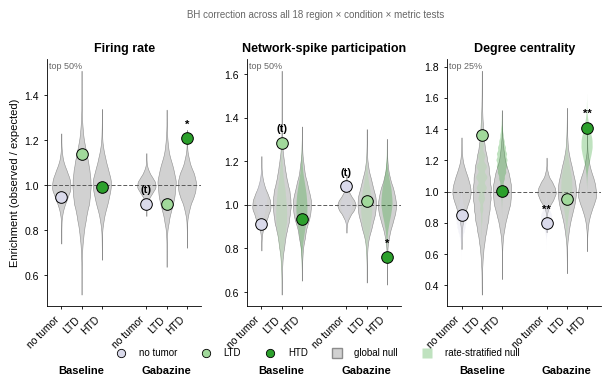

  [hash] 22_enrichment_violins_BHall                   48ae0dece79e489e


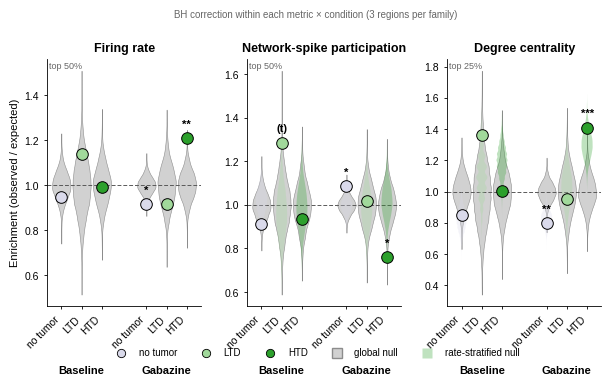

  [hash] 22_enrichment_violins_BHbyfig                 d4ade237253d6b2d


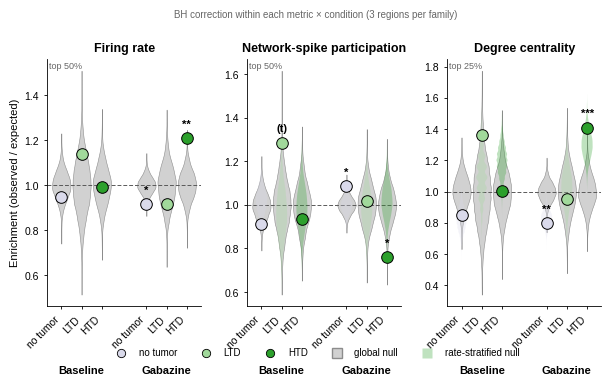

In [16]:
# =============================================================================
# ENRICHMENT SWEEP — PUBLICATION FIGURE v3
# dual violin (global + rate-stratified null) + selectable correction family
# =============================================================================
import matplotlib.font_manager as fm
from matplotlib.lines import Line2D

_AVAIL = {f.name for f in fm.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']
             if f in _AVAIL), 'sans-serif')

CELL_STYLE = {
    'font.family': FONT, 'font.size': 8,
    'axes.labelsize': 8, 'axes.titlesize': 9,
    'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
}

REGION_ORDER  = ['control', 'border_zone', 'BTI']
REGION_LABELS = {'control': 'no tumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
METRIC_TITLES = {
    'firing_rate': 'Firing rate',
    'percentage_nonrandom_spikes': 'Network-spike participation',
    'degree_centrality': 'Degree centrality',
}
DRUG_LABELS = {'8mMK': 'Baseline', '5uMgabazine': 'Gabazine'}


def _stars(q):
    if q < 0.001: return '***'
    if q < 0.01:  return '**'
    if q < 0.05:  return '*'
    if q < 0.10:  return '(t)'
    return ''


def _style_violin(vp, facecolor, edgecolor, alpha, zorder, lw=0.4):
    for body in vp['bodies']:
        body.set_facecolor(facecolor)
        body.set_edgecolor(edgecolor)
        body.set_linewidth(lw)
        body.set_alpha(alpha)
        body.set_zorder(zorder)


def plot_enrichment_violins_v3(corrected, nulls, metrics, drugs,
                               q_col='q_bh_all', show_rate_null=True,
                               correction_label='', save_path=None):
    """
    q_col            : which correction column drives the stars
    show_rate_null   : overlay the rate-stratified null (front violin)
    correction_label : short text shown under the figure title (for the reader)
    """
    with plt.rc_context(CELL_STYLE):
        fig, axes = plt.subplots(
            1, len(metrics),
            figsize=(2.25 * len(metrics) + 0.4, 3.2),
            squeeze=False, gridspec_kw={'wspace': 0.30})
        axes = axes[0]

        block_gap = 1.2
        xpos, cursor = {}, 0.0
        for drug in drugs:
            for region in REGION_ORDER:
                xpos[(drug, region)] = cursor
                cursor += 1.0
            cursor += block_gap

        for m_i, prop in enumerate(metrics):
            ax = axes[m_i]
            pct = int(corrected[corrected.property == prop].top_percentile.iloc[0])
            ax.axhline(1.0, color='0.35', lw=0.7, ls=(0, (4, 2)), zorder=1)

            for drug in drugs:
                for region in REGION_ORDER:
                    x = xpos[(drug, region)]

                    # --- global null (wide, grey, behind) ---
                    gkey = f"{prop}_{drug}_{pct}_global"
                    if gkey in nulls and region in nulls[gkey]:
                        vp = ax.violinplot(np.asarray(nulls[gkey][region]),
                                           positions=[x], widths=0.90,
                                           showextrema=False)
                        _style_violin(vp, '0.82', '0.55', 1.0, 0)

                    # --- rate-stratified null (narrow, coloured, front) ---
                    rkey = f"{prop}_{drug}_{pct}_rate"
                    if show_rate_null and rkey in nulls and region in nulls[rkey]:
                        vp = ax.violinplot(np.asarray(nulls[rkey][region]),
                                           positions=[x], widths=0.55,
                                           showextrema=False)
                        _style_violin(vp, COLORS_REGION[region], 'none', 0.30, 2)

                    row = corrected[(corrected.property == prop) &
                                    (corrected.drug == drug) &
                                    (corrected.region == region)]
                    if row.empty:
                        continue
                    e = row.observed_enrichment.iloc[0]
                    q = row[q_col].iloc[0]
                    ax.scatter([x], [e], s=70, color=COLORS_REGION[region],
                               edgecolor='black', lw=0.7, zorder=4)
                    s = _stars(q)
                    if s:
                        ax.annotate(s, (x, e), textcoords='offset points',
                                    xytext=(0, 8), ha='center',
                                    fontsize=8, fontweight='bold')

            ticks  = [xpos[(d, r)] for d in drugs for r in REGION_ORDER]
            labels = [REGION_LABELS[r] for d in drugs for r in REGION_ORDER]
            ax.set_xticks(ticks); ax.set_xticklabels(labels, rotation=45, ha='right')

            for drug in drugs:
                xs = [xpos[(drug, r)] for r in REGION_ORDER]
                ax.text(np.mean(xs), -0.24, DRUG_LABELS[drug],
                        transform=ax.get_xaxis_transform(),
                        ha='center', va='top', fontsize=8, fontweight='bold')

            ax.set_title(METRIC_TITLES.get(prop, prop), pad=6, fontweight='bold')
            ax.set_xlim(-0.7, max(ticks) + 0.7)
            ax.spines[['top', 'right']].set_visible(False)
            ax.tick_params(length=2.5)
            if m_i == 0:
                ax.set_ylabel('Enrichment (observed / expected)', labelpad=3)
            ax.text(0.01, 0.99, f'top {pct}%', transform=ax.transAxes,
                    ha='left', va='top', fontsize=6.5, color='0.4')

        handles = [Line2D([0], [0], marker='o', ls='', mfc=COLORS_REGION[r],
                          mec='black', mew=0.6, ms=6, label=REGION_LABELS[r])
                   for r in REGION_ORDER]
        handles.append(Line2D([0], [0], marker='s', ls='', mfc='0.82',
                              mec='0.55', ms=7, label='global null'))
        if show_rate_null:
            handles.append(Line2D([0], [0], marker='s', ls='', mfc=COLORS_REGION['BTI'],
                                  mec='none', ms=7, alpha=0.3,
                                  label='rate-stratified null'))
        fig.legend(handles=handles, loc='lower center', ncol=5,
                   frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.08))

        if correction_label:
            fig.text(0.5, 1.005, correction_label, ha='center', va='bottom',
                     fontsize=7, color='0.4')

        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'),
                            dpi=600, bbox_inches='tight', transparent=True)
        plt.show()
    return fig


# --- version A: BH across all 18 tests -------------------------------------
fig_all = plot_enrichment_violins_v3(
    enrichment_corrected, strat_nulls,
    metrics=['firing_rate', 'percentage_nonrandom_spikes', 'degree_centrality'],
    drugs=['8mMK', '5uMgabazine'],
    q_col='q_bh_all', show_rate_null=True,
    correction_label='BH correction across all 18 region × condition × metric tests',
    save_path=f"{OUT_DIR}/enrichment_violins_BHall.svg")
record("22_enrichment_violins_BHall", fig_all)

# --- version B: BH within metric × drug, across 3 regions -------------------
fig_byfig = plot_enrichment_violins_v3(
    enrichment_corrected, strat_nulls,
    metrics=['firing_rate', 'percentage_nonrandom_spikes', 'degree_centrality'],
    drugs=['8mMK', '5uMgabazine'],
    q_col='q_bh_byfig', show_rate_null=True,
    correction_label='BH correction within each metric × condition (3 regions per family)',
    save_path=f"{OUT_DIR}/enrichment_violins_BHbyfig.svg")
record("22_enrichment_violins_BHbyfig", fig_byfig)

In [17]:
# =============================================================================
# ENRICHMENT SWEEP — AUDIT TABLE (raw + corrected, one row per point/violin)
# =============================================================================
# Everything the figure draws, as numbers. Nothing here re-runs the analysis;
# it reads the tables/nulls already in memory so the table and figure cannot
# disagree. Saved as CSV so it is frozen alongside the fingerprints.

def null_summary(nulls, prop, drug, pct, region, strata):
    """Descriptive stats of one null distribution, or NaNs if absent."""
    key = f"{prop}_{drug}_{pct}_{strata}"
    if key not in nulls or region not in nulls[key]:
        return {f'{strata}_null_mean': np.nan, f'{strata}_null_sd': np.nan,
                f'{strata}_null_p2.5': np.nan, f'{strata}_null_p50': np.nan,
                f'{strata}_null_p97.5': np.nan, f'{strata}_null_n': np.nan}
    d = np.asarray(nulls[key][region])
    return {f'{strata}_null_mean': d.mean(), f'{strata}_null_sd': d.std(ddof=1),
            f'{strata}_null_p2.5': np.percentile(d, 2.5),
            f'{strata}_null_p50': np.percentile(d, 50),
            f'{strata}_null_p97.5': np.percentile(d, 97.5),
            f'{strata}_null_n': len(d)}


def _stars(q):
    if q < 0.001: return '***'
    if q < 0.01:  return '**'
    if q < 0.05:  return '*'
    if q < 0.10:  return '(t)'
    return 'ns'


rows = []
for _, r in enrichment_corrected.iterrows():
    prop, drug = r['property'], r['drug']
    pct, region = int(r['top_percentile']), r['region']

    row = {
        # --- identity ---
        'metric': prop, 'drug': drug, 'top_percentile': pct, 'region': region,
        # --- the observed value (the coloured dot) ---
        'observed_enrichment': r['observed_enrichment'],
        'n_top_in_region': int(r['n_top_in_region']),
        'n_total_in_region': int(r['n_total_in_region']),
        # --- RAW p-values, before any correction ---
        'p_global_RAW': r['p_permutation'],
        'p_rate_RAW': r['p_rate_stratified'],
        # --- BH-corrected q (both families) ---
        'q_BH_all18': r['q_bh_all'],
        'q_BH_byfig': r['q_bh_byfig'],
        'q_Bonf_all18': r['q_bon_all'],
        # --- verdicts ---
        'sig_raw_global': _stars(r['p_permutation']),
        'sig_BH_all18': _stars(r['q_bh_all']),
        'sig_BH_byfig': _stars(r['q_bh_byfig']),
        # --- does rate-stratification kill it? ---
        'rate_kills_effect': (r['p_permutation'] < 0.05) and
                             (not (r['p_rate_stratified'] < 0.05)
                              if pd.notna(r['p_rate_stratified']) else False),
    }
    # --- the violins, as numbers ---
    row.update(null_summary(strat_nulls, prop, drug, pct, region, 'global'))
    row.update(null_summary(strat_nulls, prop, drug, pct, region, 'rate'))
    row.update(null_summary(strat_nulls, prop, drug, pct, region, 'slice'))
    rows.append(row)

audit = pd.DataFrame(rows)

# stable, readable order
metric_order = {'firing_rate': 0, 'percentage_nonrandom_spikes': 1, 'degree_centrality': 2}
region_order = {'control': 0, 'border_zone': 1, 'BTI': 2}
audit = audit.sort_values(
    by=['metric', 'drug', 'region'],
    key=lambda c: c.map({**metric_order, **region_order}).fillna(c)
).reset_index(drop=True)

record("23_enrichment_audit_table", audit)
audit.to_csv(f"{OUT_DIR}/enrichment_audit_table.csv", index=False)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 240)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# --- view 1: the decision table (what you cite) ---
print("=" * 100)
print("DECISION TABLE — observed value, raw p, corrected q, verdicts")
print("=" * 100)
print(audit[['metric', 'drug', 'region', 'observed_enrichment',
             'p_global_RAW', 'p_rate_RAW',
             'q_BH_all18', 'q_BH_byfig',
             'sig_raw_global', 'sig_BH_all18', 'sig_BH_byfig',
             'rate_kills_effect']].to_string(index=False))

# --- view 2: the violins, as numbers ---
print("\n" + "=" * 100)
print("NULL DISTRIBUTIONS — the numbers behind each violin")
print("=" * 100)
print(audit[['metric', 'drug', 'region', 'observed_enrichment',
             'global_null_p2.5', 'global_null_p50', 'global_null_p97.5',
             'rate_null_p2.5', 'rate_null_p50', 'rate_null_p97.5']].to_string(index=False))

  [hash] 23_enrichment_audit_table                     c7823124f83b50f3
DECISION TABLE — observed value, raw p, corrected q, verdicts
                     metric        drug      region  observed_enrichment  p_global_RAW  p_rate_RAW  q_BH_all18  q_BH_byfig sig_raw_global sig_BH_all18 sig_BH_byfig  rate_kills_effect
                firing_rate 5uMgabazine     control               0.9167        0.0318         NaN      0.0818      0.0477              *          (t)            *              False
                firing_rate 5uMgabazine border_zone               0.9167        0.3863         NaN      0.5795      0.3863             ns           ns           ns              False
                firing_rate 5uMgabazine         BTI               1.2082        0.0021         NaN      0.0126      0.0063             **            *           **              False
                firing_rate        8mMK     control               0.9484        0.4720         NaN      0.6535      0.7080            

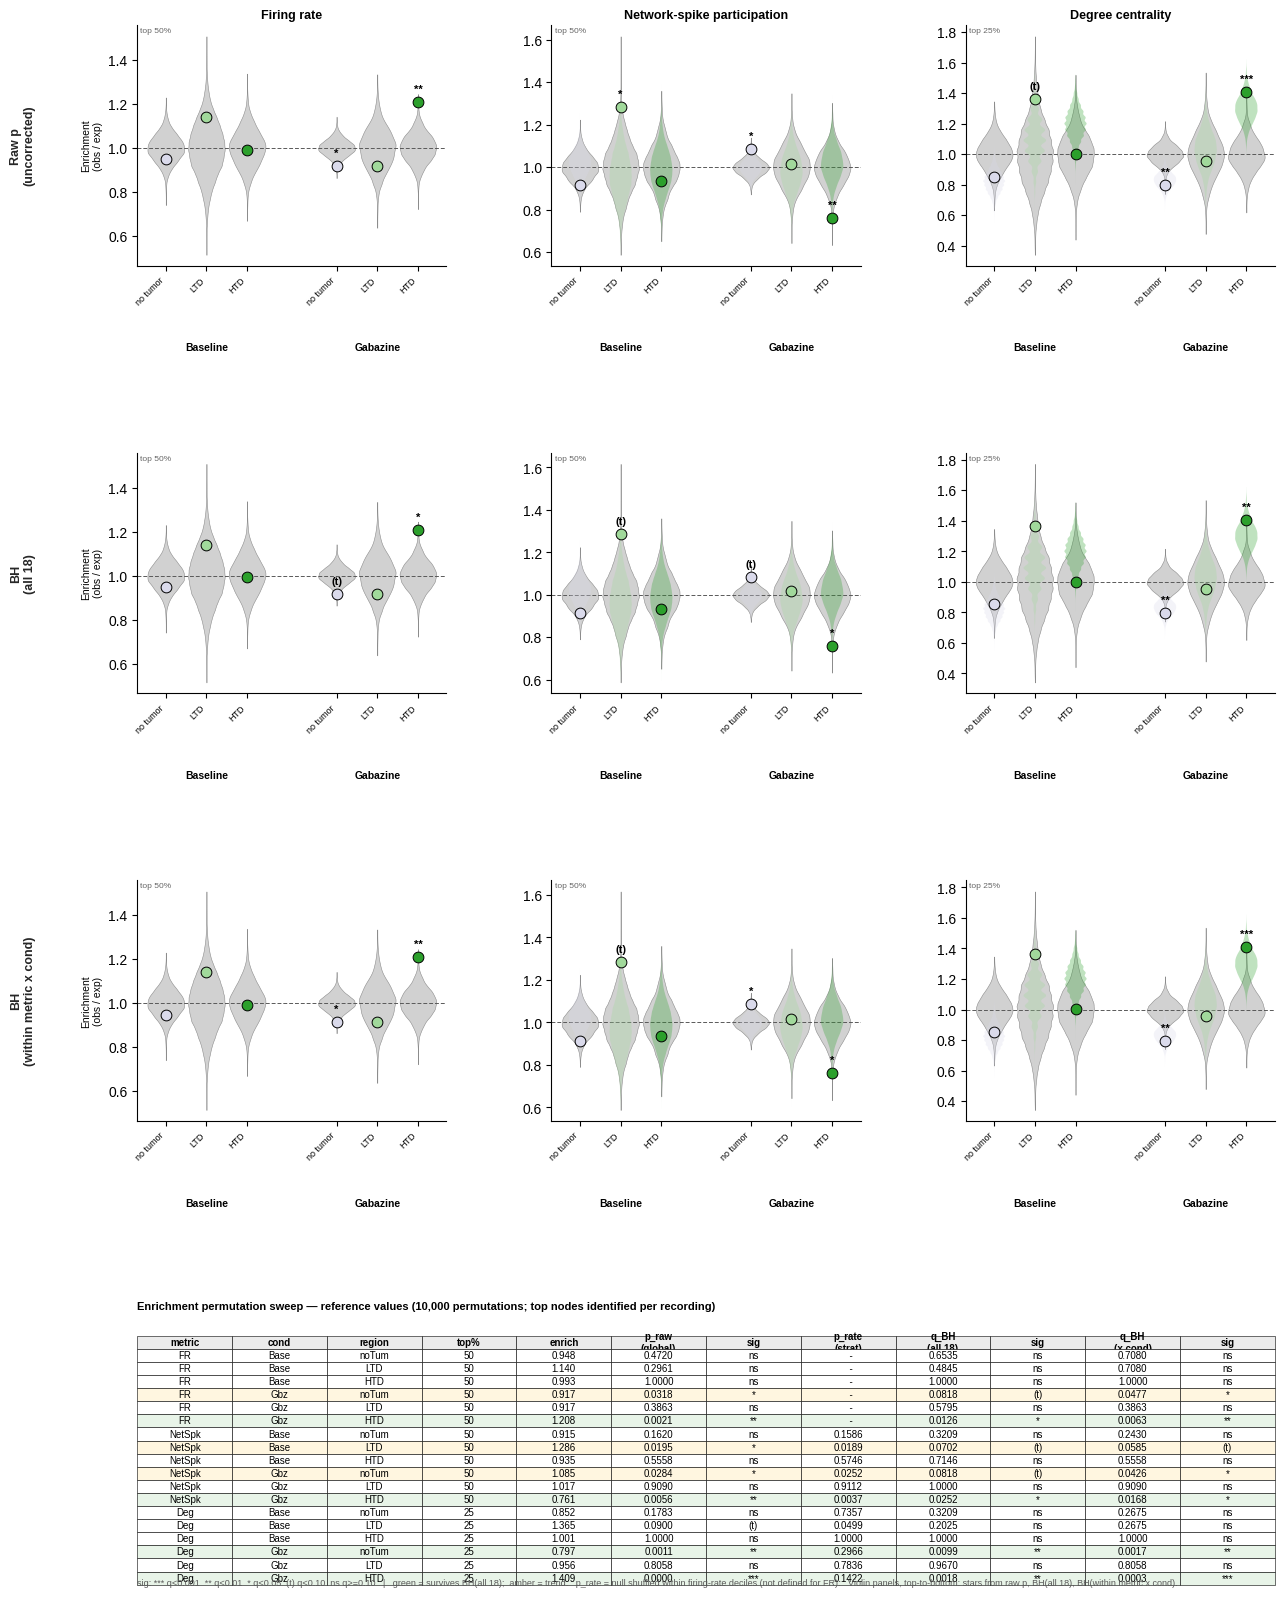

  [hash] 24_enrichment_full_reference                  292beda36d2c7398


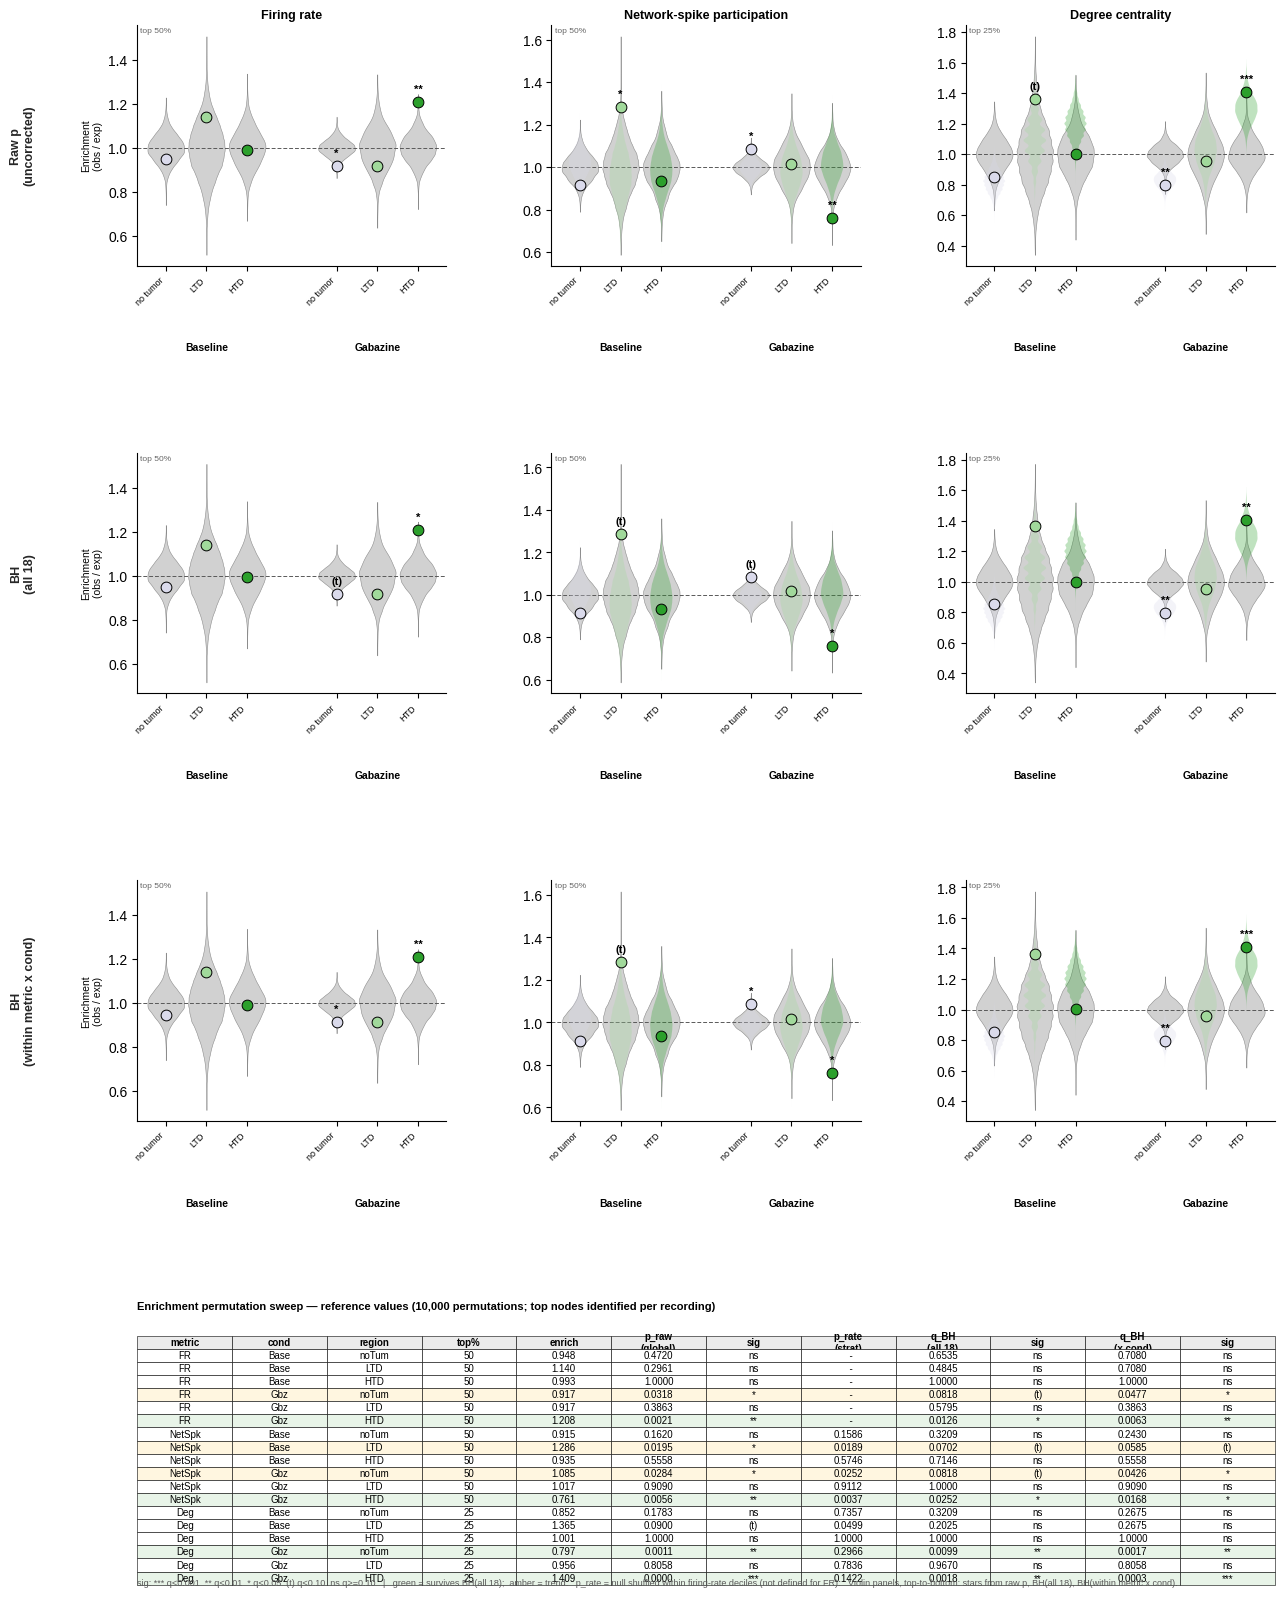

In [18]:
# =============================================================================
# ENRICHMENT SWEEP — FULL REFERENCE FIGURE (uncrowded)
# Three star-schemes (raw p / BH all-18 / BH within metric x cond) + value table.
# All stars and numbers drawn from enrichment_corrected in one call.
# =============================================================================

import matplotlib.font_manager as fm

_AVAIL = {f.name for f in fm.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']
             if f in _AVAIL), 'sans-serif')

REGION_ORDER  = ['control', 'border_zone', 'BTI']
REGION_LABELS = {'control': 'no tumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
REGION_SHORT  = {'control': 'noTum', 'border_zone': 'LTD', 'BTI': 'HTD'}
METRIC_TITLES = {'firing_rate': 'Firing rate',
                 'percentage_nonrandom_spikes': 'Network-spike participation',
                 'degree_centrality': 'Degree centrality'}
METRIC_SHORT  = {'firing_rate': 'FR', 'percentage_nonrandom_spikes': 'NetSpk',
                 'degree_centrality': 'Deg'}
DRUG_LABELS   = {'8mMK': 'Baseline', '5uMgabazine': 'Gabazine'}
DRUG_SHORT    = {'8mMK': 'Base', '5uMgabazine': 'Gbz'}

STAR_ROWS = [
    ('Raw p\n(uncorrected)',      'p_permutation'),
    ('BH\n(all 18)',              'q_bh_all'),
    ('BH\n(within metric x cond)', 'q_bh_byfig'),
]


def _stars(v):
    if v < 0.001: return '***'
    if v < 0.01:  return '**'
    if v < 0.05:  return '*'
    if v < 0.10:  return '(t)'
    return 'ns'


def _style_violin(vp, fc, ec, alpha, z, lw=0.4):
    for b in vp['bodies']:
        b.set_facecolor(fc); b.set_edgecolor(ec)
        b.set_linewidth(lw); b.set_alpha(alpha); b.set_zorder(z)


def _draw_violin_row(fig, subgs, corrected, nulls, metrics, drugs,
                     xpos, sig_col, is_top_row, show_rate_null=True):
    first_ax = None
    for m_i, prop in enumerate(metrics):
        ax = fig.add_subplot(subgs[m_i])
        if m_i == 0:
            first_ax = ax
        pct = int(corrected[corrected.property == prop].top_percentile.iloc[0])
        ax.axhline(1.0, color='0.35', lw=0.7, ls=(0, (4, 2)), zorder=1)

        for drug in drugs:
            for region in REGION_ORDER:
                x = xpos[(drug, region)]
                gkey = f"{prop}_{drug}_{pct}_global"
                if gkey in nulls and region in nulls[gkey]:
                    _style_violin(ax.violinplot(np.asarray(nulls[gkey][region]),
                                  positions=[x], widths=0.90, showextrema=False),
                                  '0.82', '0.55', 1.0, 0)
                rkey = f"{prop}_{drug}_{pct}_rate"
                if show_rate_null and rkey in nulls and region in nulls[rkey]:
                    _style_violin(ax.violinplot(np.asarray(nulls[rkey][region]),
                                  positions=[x], widths=0.55, showextrema=False),
                                  COLORS_REGION[region], 'none', 0.30, 2)
                row = corrected[(corrected.property == prop) &
                                (corrected.drug == drug) &
                                (corrected.region == region)]
                if row.empty:
                    continue
                e = row['observed_enrichment'].iloc[0]
                v = row[sig_col].iloc[0]
                ax.scatter([x], [e], s=60, color=COLORS_REGION[region],
                           edgecolor='black', lw=0.7, zorder=4)
                s = _stars(v)
                if s != 'ns':
                    ax.annotate(s, (x, e), textcoords='offset points',
                                xytext=(0, 7), ha='center',
                                fontsize=8, fontweight='bold')

        ticks = [xpos[(d, r)] for d in drugs for r in REGION_ORDER]
        ax.set_xticks(ticks)
        ax.set_xticklabels([REGION_LABELS[r] for d in drugs for r in REGION_ORDER],
                           rotation=45, ha='right', fontsize=6.5)
        for drug in drugs:
            xs = [xpos[(drug, r)] for r in REGION_ORDER]
            ax.text(np.mean(xs), -0.32, DRUG_LABELS[drug],
                    transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=7.5, fontweight='bold')
        ax.set_xlim(-0.7, max(ticks) + 0.7)
        ax.spines[['top', 'right']].set_visible(False)
        ax.text(0.01, 0.99, f'top {pct}%', transform=ax.transAxes,
                ha='left', va='top', fontsize=6, color='0.4')
        if m_i == 0:
            ax.set_ylabel('Enrichment\n(obs / exp)', fontsize=7.5)
        if is_top_row:
            ax.set_title(METRIC_TITLES[prop], fontsize=9, fontweight='bold', pad=5)
    return first_ax


def plot_enrichment_full_reference(corrected, nulls, metrics, drugs,
                                   show_rate_null=True, save_path=None):
    with plt.rc_context({'font.family': FONT, 'pdf.fonttype': 42,
                         'ps.fonttype': 42, 'svg.fonttype': 'none'}):

        fig = plt.figure(figsize=(13, 16.5))
        gs = fig.add_gridspec(4, 1, height_ratios=[1, 1, 1, 1.15], hspace=0.75,
                              left=0.11, right=0.985, top=0.965, bottom=0.02)

        block_gap = 1.2
        xpos, cursor = {}, 0.0
        for drug in drugs:
            for region in REGION_ORDER:
                xpos[(drug, region)] = cursor; cursor += 1.0
            cursor += block_gap

        row_first_axes = []
        for row_i, (label, col) in enumerate(STAR_ROWS):
            subgs = gs[row_i].subgridspec(1, len(metrics), wspace=0.34)
            ax0 = _draw_violin_row(fig, subgs, corrected, nulls, metrics, drugs,
                                   xpos, col, is_top_row=(row_i == 0),
                                   show_rate_null=show_rate_null)
            row_first_axes.append((ax0, label))

        # row labels as figure text at far left, centred on each row band
        fig.canvas.draw()
        for ax0, label in row_first_axes:
            p = ax0.get_position()
            fig.text(0.022, (p.y0 + p.y1) / 2, label, rotation=90,
                     va='center', ha='center', fontsize=9, fontweight='bold',
                     color='0.15')

        # --- table ----------------------------------------------------------
        axt = fig.add_subplot(gs[3]); axt.axis('off')
        order = {p: i for i, p in enumerate(metrics)}
        tbl = corrected.copy()
        tbl['_m'] = tbl['property'].map(order)
        tbl['_d'] = tbl['drug'].map({d: i for i, d in enumerate(drugs)})
        tbl['_r'] = tbl['region'].map({r: i for i, r in enumerate(REGION_ORDER)})
        tbl = tbl.sort_values(['_m', '_d', '_r'])

        col_labels = ['metric', 'cond', 'region', 'top%', 'enrich',
                      'p_raw\n(global)', 'sig', 'p_rate\n(strat)',
                      'q_BH\n(all 18)', 'sig', 'q_BH\n(x cond)', 'sig']
        cells, colours = [], []
        for _, r in tbl.iterrows():
            s_raw = _stars(r['p_permutation'])
            s_all = _stars(r['q_bh_all'])
            s_fig = _stars(r['q_bh_byfig'])
            cells.append([
                METRIC_SHORT[r['property']], DRUG_SHORT[r['drug']],
                REGION_SHORT[r['region']], f"{int(r['top_percentile'])}",
                f"{r['observed_enrichment']:.3f}",
                f"{r['p_permutation']:.4f}", s_raw,
                ("  -" if pd.isna(r['p_rate_stratified']) else f"{r['p_rate_stratified']:.4f}"),
                f"{r['q_bh_all']:.4f}", s_all,
                f"{r['q_bh_byfig']:.4f}", s_fig,
            ])
            colours.append('#E8F4E8' if s_all not in ('ns', '(t)') else
                           ('#FFF6E0' if s_all == '(t)' else 'white'))

        table = axt.table(cellText=cells, colLabels=col_labels,
                          cellLoc='center', bbox=[0, 0, 1, 0.90])
        table.auto_set_font_size(False); table.set_fontsize(7)
        for (rr, cc), cell in table.get_celld().items():
            cell.set_linewidth(0.4)
            if rr == 0:
                cell.set_text_props(fontweight='bold'); cell.set_facecolor('0.92')
            else:
                cell.set_facecolor(colours[rr - 1])

        pos = axt.get_position()
        fig.text(0.11, pos.y1 - 0.002,
                 'Enrichment permutation sweep — reference values '
                 '(10,000 permutations; top nodes identified per recording)',
                 fontsize=8, fontweight='bold', va='bottom')
        fig.text(0.11, pos.y0 + 0.004,
                 'sig: *** q<0.001  ** q<0.01  * q<0.05  (t) q<0.10  ns q>=0.10   |   '
                 'green = survives BH(all 18);  amber = trend.   '
                 'p_rate = null shuffled within firing-rate deciles (not defined for FR).   '
                 'Violin panels, top-to-bottom: stars from raw p, BH(all 18), BH(within metric x cond).',
                 fontsize=6.5, color='0.35', va='top')

        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'), dpi=300)
        plt.show()
    return fig


fig_full = plot_enrichment_full_reference(
    enrichment_corrected, strat_nulls,
    metrics=['firing_rate', 'percentage_nonrandom_spikes', 'degree_centrality'],
    drugs=['8mMK', '5uMgabazine'],
    show_rate_null=True,
    save_path=f"{OUT_DIR}/enrichment_full_reference.svg")
record("24_enrichment_full_reference", fig_full)

# node level group statistics


In [19]:
# =============================================================================
# NODE-LEVEL GROUP STATISTICS
# =============================================================================
# Kruskal-Wallis omnibus + Dunn post-hoc with Bonferroni (applied ONCE, inside
# posthoc_dunn). Effect sizes: Cohen's d and Cliff's delta for every pair.
# This replaces the tangle of analyze_groups / _enhanced / _cell_style: one
# stats function, one correction, used by every comparison panel.

from scikit_posthocs import posthoc_dunn
from scipy import stats as sps
from itertools import combinations


def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    n = len(a) * len(b)
    if n == 0:
        return np.nan
    gt = sum((x > b).sum() for x in a)
    lt = sum((x < b).sum() for x in a)
    return (gt - lt) / n


def cohens_d(a, b):
    a, b = np.asarray(a), np.asarray(b)
    na, nb = len(a), len(b)
    if na < 2 or nb < 2:
        return np.nan
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp if sp > 0 else np.nan


def compare_groups(df, parameter, group_col, group_order,
                   filter_drug=None, filter_experiment=None):
    """
    One parameter across groups. Returns a tidy dict:
      omnibus (Kruskal-Wallis), pairwise (Dunn Bonferroni + effect sizes), summary.
    Correction is applied once, by posthoc_dunn(p_adjust='bonferroni').
    """
    d = df.copy()
    if filter_drug is not None:
        d = d[d['drug'].str.contains(filter_drug, na=False, case=False)]
    if filter_experiment is not None:
        d = d[d['experiment'] == filter_experiment]
    d = d[d[group_col].isin(group_order) & d[parameter].notna()]

    groups_present = [g for g in group_order if g in d[group_col].unique()]
    samples = [d[d[group_col] == g][parameter].values for g in groups_present]

    h, p_omni = sps.kruskal(*samples)
    dunn = posthoc_dunn(d, val_col=parameter, group_col=group_col,
                        p_adjust='bonferroni')

    pair_rows = []
    for g1, g2 in combinations(groups_present, 2):
        a = d[d[group_col] == g1][parameter].values
        b = d[d[group_col] == g2][parameter].values
        pair_rows.append({
            'parameter': parameter, 'group_1': g1, 'group_2': g2,
            'p_dunn_bonferroni': float(dunn.loc[g1, g2]),
            'cohens_d': cohens_d(a, b), 'cliffs_delta': cliffs_delta(a, b),
            'n_1': len(a), 'n_2': len(b),
            'median_1': np.median(a), 'median_2': np.median(b),
        })

    summary = (d.groupby(group_col)[parameter]
               .agg(['count', 'median',
                     ('q25', lambda x: x.quantile(0.25)),
                     ('q75', lambda x: x.quantile(0.75))])
               .reindex(groups_present))

    return {'parameter': parameter, 'group_col': group_col,
            'kruskal_h': float(h), 'kruskal_p': float(p_omni),
            'pairwise': pd.DataFrame(pair_rows), 'summary': summary,
            'data': d[[group_col, parameter]].copy()}

In [20]:
# =============================================================================
# NETWORK TOPOLOGY FIGURES
# =============================================================================
# Fig 4I: force-directed (Fruchterman-Reingold) spring layout, node size = degree
# bin, node colour = firing rate or % network spikes.
# Suppl 1b: same graph drawn on the physical 16x16 MEA grid.

DEGREE_BINS   = [0, 10, 50, 100, np.inf]      # 1-10, 11-50, 51-100, >100
DEGREE_SIZES  = [20, 60, 140, 300]


def _node_sizes_by_degree(G):
    sizes = []
    for n in G.nodes():
        deg = G.degree[n]
        for (lo, hi), s in zip(zip(DEGREE_BINS[:-1], DEGREE_BINS[1:]), DEGREE_SIZES):
            if lo < deg <= hi:
                sizes.append(s); break
        else:
            sizes.append(DEGREE_SIZES[0])
    return sizes


def plot_spring_layout(G, color_by='firing_rate', k=2, seed=GLOBAL_SEED,
                       title=None, save_path=None):
    """Fig 4I. color_by: node attribute name for colour (firing rate or %spikes)."""
    reset_seed(seed)
    pos = nx.spring_layout(G, k=k, seed=seed)          # Fruchterman-Reingold
    node_colors = [G.nodes[n].get(color_by, 0) for n in G.nodes()]

    with plt.rc_context({'font.family': FONT, 'pdf.fonttype': 42,
                         'svg.fonttype': 'none'}):
        fig, ax = plt.subplots(figsize=(6, 6))
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='0.75',
                               width=0.3, alpha=0.5)
        nodes = nx.draw_networkx_nodes(
            G, pos, ax=ax, node_size=_node_sizes_by_degree(G),
            node_color=node_colors, cmap='viridis',
            edgecolors='black', linewidths=0.3)
        plt.colorbar(nodes, ax=ax, shrink=0.6, label=color_by)
        ax.set_title(title or '', fontsize=9); ax.axis('off')
        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'),
                            dpi=300, bbox_inches='tight')
        plt.show()
    return fig


def plot_on_mea_grid(G, color_by='firing_rate', title=None, save_path=None):
    """Suppl 1b. Nodes at physical electrode coordinates on the 16x16 grid."""
    def coord(node):
        # electrode ids like 'R7C12' or a stored (row,col) — adapt to your scheme
        if 'grid_row' in G.nodes[node] and 'grid_col' in G.nodes[node]:
            return (G.nodes[node]['grid_col'], -G.nodes[node]['grid_row'])
        return None
    pos = {n: coord(n) for n in G.nodes() if coord(n) is not None}
    if len(pos) < G.number_of_nodes():
        print(f"  warning: {G.number_of_nodes()-len(pos)} nodes lack grid coords")

    with plt.rc_context({'font.family': FONT, 'pdf.fonttype': 42,
                         'svg.fonttype': 'none'}):
        fig, ax = plt.subplots(figsize=(6, 6))
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='0.7',
                               width=0.25, alpha=0.4)
        nodes = nx.draw_networkx_nodes(
            G, pos, ax=ax, node_size=_node_sizes_by_degree(G),
            node_color=[G.nodes[n].get(color_by, 0) for n in pos],
            nodelist=list(pos.keys()), cmap='viridis',
            edgecolors='black', linewidths=0.3)
        plt.colorbar(nodes, ax=ax, shrink=0.6, label=color_by)
        ax.set_title(title or '', fontsize=9); ax.set_aspect('equal'); ax.axis('off')
        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'),
                            dpi=300, bbox_inches='tight')
        plt.show()
    return fig


# ---- render the representative slices used in Fig 4I ------------------------
# Replace these with the filenames of the representative slices from the paper.
FIG4I_SLICES = {
    'control_8mMK':   None,   # e.g. 'ID2310CT003_..._8mMK'
    'control_gabazine': None,
    'tumor_8mMK':     None,
    'tumor_gabazine': None,
}
for label, fn in FIG4I_SLICES.items():
    if fn is None or fn not in graphs_thresholded:
        continue
    G = graphs_thresholded[fn]
    plot_spring_layout(G, color_by='firing_rate', title=f"{label} (firing rate)",
                       save_path=f"{OUT_DIR}/fig4I_{label}_fr.svg")
    plot_spring_layout(G, color_by='percentage_nonrandom_spikes',
                       title=f"{label} (% network spikes)",
                       save_path=f"{OUT_DIR}/fig4I_{label}_spikes.svg")

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from scipy import stats as scipy_stats
from datetime import datetime
import os


def cohens_d(group1, group2):
    """
    Calculate Cohen's d effect size.

    Parameters:
    -----------
    group1, group2 : array-like
        Data from two groups

    Returns:
    --------
    d : float
        Cohen's d effect size
    interpretation : str
        Interpretation of effect size magnitude
    """
    n1, n2 = len(group1), len(group2)
    var1, var2 = np.var(group1, ddof=1), np.var(group2, ddof=1)

    # Pooled standard deviation
    pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))

    # Cohen's d
    d = (np.mean(group1) - np.mean(group2)) / pooled_std

    # Interpretation (Cohen's conventions)
    abs_d = abs(d)
    if abs_d < 0.2:
        interpretation = "Negligible"
    elif abs_d < 0.5:
        interpretation = "Small"
    elif abs_d < 0.8:
        interpretation = "Medium"
    else:
        interpretation = "Large"

    return d, interpretation


def cliffs_delta(group1, group2):
    """
    Calculate Cliff's Delta effect size (non-parametric).

    Cliff's Delta measures the degree of overlap between two distributions.
    It represents the probability that a randomly selected value from one group
    is greater than a randomly selected value from another group, minus the
    reverse probability.

    Parameters:
    -----------
    group1, group2 : array-like
        Data from two groups

    Returns:
    --------
    delta : float
        Cliff's Delta effect size (-1 to 1)
    interpretation : str
        Interpretation of effect size magnitude
    """
    n1, n2 = len(group1), len(group2)

    # Count dominance pairs
    greater = 0
    less = 0

    for x in group1:
        for y in group2:
            if x > y:
                greater += 1
            elif x < y:
                less += 1

    # Cliff's Delta
    delta = (greater - less) / (n1 * n2)

    # Interpretation (Romano et al., 2006 thresholds)
    abs_delta = abs(delta)
    if abs_delta < 0.147:
        interpretation = "Negligible"
    elif abs_delta < 0.33:
        interpretation = "Small"
    elif abs_delta < 0.474:
        interpretation = "Medium"
    else:
        interpretation = "Large"

    return delta, interpretation


def plot_metric_distributions(nodes_data, metric='degree', filter_drug=None,
                              comparison_type='experiment', figsize=(12, 6),
                              log_x=False, log_y=False,
                              save_path=None):
    """
    Compare distributions with better layout, significance markers, and effect sizes.

    Parameters:
    -----------
    nodes_data : DataFrame
        Input data containing node-level metrics
    metric : str
        Column name to plot (e.g., 'degree', 'firing_rate', etc.)
    filter_drug : str, optional
        Filter data by specific drug condition
    comparison_type : str
        'experiment' or 'region' comparison
    figsize : tuple
        Figure size (width, height)
    log_x : bool, optional (default=False)
        If True, use logarithmic scale for x-axis in histogram and KDE
    log_y : bool, optional (default=False)
        If True, use logarithmic scale for y-axis in all distribution plots
    save_path : str, optional
        Path to save the figure and statistics (saves PNG, SVG, and PDF)

    Returns:
    --------
    data : DataFrame
        Filtered data used for plotting
    """

    # Set up PDF-compatible font settings
    rcParams["font.family"] = "Arial"
    rcParams["pdf.fonttype"] = 42  # TrueType fonts for editability

    COLORS_EXPERIMENT = {
        'control_slice': '#6BAED6',
        'BTSC': '#2CA02C'
    }

    COLORS_REGION = {
        'control': '#DADAEB',
        'border_zone': '#A1D99B',
        'BTI': '#2CA02C'
    }

    BORDER_COLORS_REGION = {
        'control': '#9E9AC8',
        'border_zone': '#41AB5D',
        'BTI': '#006D2C'
    }

    # Filter data
    if filter_drug:
        data = nodes_data[nodes_data['drug'] == filter_drug].copy()
    else:
        data = nodes_data.copy()

    data = data[data[metric].notna()].copy()

    # Determine groups
    if comparison_type == 'experiment':
        group_col = 'experiment'
        colors = COLORS_EXPERIMENT
        border_colors = COLORS_EXPERIMENT
        groups = ['control_slice', 'BTSC']
    else:  # 'region'
        group_col = 'region_experiment'
        colors = COLORS_REGION
        border_colors = BORDER_COLORS_REGION
        data = data[data['experiment'] == 'BTSC']
        groups = ['control', 'border_zone', 'BTI']

    groups = [g for g in groups if g in data[group_col].unique()]

    # Create figure: 2 rows, 3 columns with MORE SPACE for statistics panel
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.35,
                         height_ratios=[1, 1], width_ratios=[1.2, 1.2, 1.1])

    ax1 = fig.add_subplot(gs[0, 0])  # Violin
    ax2 = fig.add_subplot(gs[0, 1])  # Histogram
    ax3 = fig.add_subplot(gs[1, 0])  # KDE
    ax4 = fig.add_subplot(gs[1, 1])  # Summary statistics table
    ax_stats = fig.add_subplot(gs[:, 2])  # Statistics table (spans both rows)

    # ===== PANEL 1: Violin Plot with Significance =====
    positions = range(1, len(groups) + 1)
    violin_data = [data[data[group_col] == g][metric].values for g in groups]

    parts = ax1.violinplot(violin_data, positions=positions, widths=0.6,
                           showmeans=False, showmedians=False, showextrema=False)

    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(colors[groups[i]])
        pc.set_alpha(0.3)
        pc.set_edgecolor(border_colors[groups[i]])
        pc.set_linewidth(0.8)

    bp = ax1.boxplot(violin_data, positions=positions, widths=0.15,
                     patch_artist=True, showfliers=False,
                     boxprops=dict(facecolor='white', edgecolor='black', linewidth=0.8),
                     medianprops=dict(color='black', linewidth=2),
                     whiskerprops=dict(color='black', linewidth=0.6),
                     capprops=dict(color='black', linewidth=0.6))

    # Apply log scale to violin plot if requested
    if log_y:
        ax1.set_yscale('log')

    # Add significance markers on violin plot
    if len(groups) >= 3:
        kw_stat, kw_p = scipy_stats.kruskal(*violin_data)

        if kw_p < 0.05:
            # Post-hoc pairwise comparisons
            n_comparisons = len(groups) * (len(groups) - 1) // 2
            y_max = max([d.max() for d in violin_data])
            y_range = y_max - min([d.min() for d in violin_data])

            comparison_pairs = [
                (0, 2, 'control vs BTI'),      # Most important
                (1, 2, 'border vs BTI'),        # Second most important
                (0, 1, 'control vs border')     # Third
            ]

            for idx, (i, j, label) in enumerate(comparison_pairs):
                if i < len(groups) and j < len(groups):
                    g1_data = data[data[group_col] == groups[i]][metric].values
                    g2_data = data[data[group_col] == groups[j]][metric].values

                    _, p_pairwise = scipy_stats.mannwhitneyu(g1_data, g2_data)
                    p_corrected = min(p_pairwise * n_comparisons, 1.0)

                    if p_corrected < 0.05:
                        # Draw significance bar
                        if log_y:
                            # For log scale, use multiplicative spacing
                            y_pos = y_max * (1.2 ** (idx + 1))
                        else:
                            y_pos = y_max + y_range * (0.05 + 0.10 * idx)

                        ax1.plot([i+1, j+1], [y_pos, y_pos], 'k-', linewidth=0.8)

                        # Add stars
                        if p_corrected < 0.001:
                            sig = '***'
                        elif p_corrected < 0.01:
                            sig = '**'
                        else:
                            sig = '*'

                        ax1.text((i+j)/2+1, y_pos, sig, ha='center', va='bottom',
                               fontsize=8, weight='bold')

    elif len(groups) == 2:
        _, p = scipy_stats.mannwhitneyu(violin_data[0], violin_data[1])
        if p < 0.05:
            y_max = max([d.max() for d in violin_data])
            y_range = y_max - min([d.min() for d in violin_data])

            if log_y:
                y_pos = y_max * 1.2
            else:
                y_pos = y_max + y_range * 0.05

            ax1.plot([1, 2], [y_pos, y_pos], 'k-', linewidth=0.8)
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*'
            ax1.text(1.5, y_pos, sig, ha='center', va='bottom',
                   fontsize=8, weight='bold')

    ax1.set_xticks(positions)
    ax1.set_xticklabels([f'{g}\n(n={len(data[data[group_col]==g])})' for g in groups],
                        fontsize=6)
    ax1.set_ylabel(metric.replace('_', ' ').title(), fontsize=7)
    ax1.set_title('Distribution Shape', fontsize=8, weight='bold')
    ax1.grid(True, alpha=0.15, axis='y', linewidth=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # ===== PANEL 2: Histogram =====
    all_values = data[metric].values

    # Use appropriate binning for log scale
    if log_x:
        # For log scale, use log-spaced bins
        min_val = all_values[all_values > 0].min() if np.any(all_values > 0) else 1e-10
        max_val = all_values.max()
        bins = np.logspace(np.log10(min_val), np.log10(max_val), 30)
    else:
        bins = np.histogram_bin_edges(all_values, bins=30)

    for group in groups:
        group_data = data[data[group_col] == group][metric].values
        ax2.hist(group_data, bins=bins, alpha=0.3,
                color=colors[group], label=group,
                edgecolor=border_colors[group], linewidth=0.5, density=True)

    # Apply log scales if requested
    if log_x:
        ax2.set_xscale('log')
    if log_y:
        ax2.set_yscale('log')

    ax2.set_xlabel(metric.replace('_', ' ').title(), fontsize=7)
    ax2.set_ylabel('Density', fontsize=7)
    ax2.set_title('Overlaid Distributions', fontsize=8, weight='bold')
    ax2.legend(fontsize=6, frameon=False, loc='best')
    ax2.grid(True, alpha=0.15, axis='y', linewidth=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    # ===== PANEL 3: KDE =====
    if log_x:
        # For log scale, use log-spaced x values
        x_min = data[metric][data[metric] > 0].min() if np.any(data[metric] > 0) else 1e-10
        x_max = data[metric].max()
        x_range = np.logspace(np.log10(x_min), np.log10(x_max), 200)
    else:
        x_min, x_max = data[metric].min(), data[metric].max()
        x_range = np.linspace(x_min, x_max, 200)

    for group in groups:
        group_data = data[data[group_col] == group][metric].values

        # Remove zeros for log scale KDE
        if log_x:
            group_data = group_data[group_data > 0]

        if len(group_data) > 1:  # Need at least 2 points for KDE
            kde = scipy_stats.gaussian_kde(group_data)
            density = kde(x_range)

            ax3.plot(x_range, density, linewidth=2,
                    label=group, color=colors[group])
            ax3.fill_between(x_range, density, alpha=0.2, color=colors[group])

    # Apply log scales if requested
    if log_x:
        ax3.set_xscale('log')
    if log_y:
        ax3.set_yscale('log')

    ax3.set_xlabel(metric.replace('_', ' ').title(), fontsize=7)
    ax3.set_ylabel('Density', fontsize=7)
    ax3.set_title('Kernel Density Estimation', fontsize=8, weight='bold')
    ax3.legend(fontsize=6, frameon=False, loc='best')
    ax3.grid(True, alpha=0.15, axis='y', linewidth=0.3)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)

    # ===== PANEL 4: Summary Statistics Table (WITH COHEN'S D AND CLIFF'S DELTA) =====
    ax4.axis('off')

    # Create summary stats table
    if len(groups) == 2:
        # For 2 groups, show both effect sizes prominently
        summary_data = [['Group', 'Median', 'IQR', 'Mean ± SD']]

        for group in groups:
            group_data = data[data[group_col] == group][metric].values
            median = np.median(group_data)
            q25, q75 = np.percentile(group_data, [25, 75])
            iqr = q75 - q25
            mean = np.mean(group_data)
            sd = np.std(group_data, ddof=1)

            # Format based on scale
            if log_x or log_y:
                summary_data.append([
                    group,
                    f'{median:.2e}',
                    f'{iqr:.2e}',
                    f'{mean:.2e} ± {sd:.2e}'
                ])
            else:
                summary_data.append([
                    group,
                    f'{median:.1f}',
                    f'{iqr:.1f}',
                    f'{mean:.1f} ± {sd:.1f}'
                ])

        # Add effect sizes
        g1_data = data[data[group_col] == groups[0]][metric].values
        g2_data = data[data[group_col] == groups[1]][metric].values

        d, d_interp = cohens_d(g1_data, g2_data)
        delta, delta_interp = cliffs_delta(g1_data, g2_data)

        summary_data.append(['', '', '', ''])
        summary_data.append(["Cohen's d", f'{d:.3f}', f'({d_interp})', ''])
        summary_data.append(["Cliff's δ", f'{delta:.3f}', f'({delta_interp})', ''])

        col_widths = [0.30, 0.23, 0.23, 0.24]

    else:
        # For 3+ groups, keep original format
        summary_data = [['Group', 'Median', 'IQR', 'Variance']]

        for group in groups:
            group_data = data[data[group_col] == group][metric].values
            median = np.median(group_data)
            q25, q75 = np.percentile(group_data, [25, 75])
            iqr = q75 - q25
            variance = np.var(group_data)

            # Format based on scale
            if log_x or log_y:
                summary_data.append([
                    group,
                    f'{median:.2e}',
                    f'{iqr:.2e}',
                    f'{variance:.2e}'
                ])
            else:
                summary_data.append([
                    group,
                    f'{median:.1f}',
                    f'{iqr:.1f}',
                    f'{variance:.1f}'
                ])

        col_widths = [0.4, 0.2, 0.2, 0.2]

    summary_table = ax4.table(cellText=summary_data,
                             cellLoc='center',
                             loc='center',
                             colWidths=col_widths)

    summary_table.auto_set_font_size(False)
    summary_table.set_fontsize(7)
    summary_table.scale(1, 2.0)

    # Style summary table
    for i in range(len(summary_data)):
        for j in range(4):
            cell = summary_table[(i, j)]
            if i == 0:  # Header
                cell.set_facecolor('#E8E8E8')
                cell.set_text_props(weight='bold')
            # Highlight effect size rows
            elif len(groups) == 2 and i >= len(summary_data) - 2 and summary_data[i][0]:
                cell.set_facecolor('#FFF4E6')
                if j == 0:  # Effect size label
                    cell.set_text_props(weight='bold')
                elif j == 1:  # value
                    cell.set_text_props(weight='bold', fontsize=8)
                elif j == 2:  # interpretation
                    # Color code by magnitude
                    if 'Large' in summary_data[i][j]:
                        cell.set_text_props(color='#D62728', weight='bold')
                    elif 'Medium' in summary_data[i][j]:
                        cell.set_text_props(color='#FF7F0E', weight='bold')
                    elif 'Small' in summary_data[i][j]:
                        cell.set_text_props(color='#2CA02C')
                    else:  # Negligible
                        cell.set_text_props(color='#7F7F7F')

            cell.set_edgecolor('gray')
            cell.set_linewidth(0.5)

    ax4.set_title('Summary Statistics', fontsize=8, weight='bold', pad=20)

    # ===== STATISTICS PANEL (Right side, spans both rows) =====
    ax_stats.axis('off')

    # Calculate statistics and prepare for both display and text file
    stats_data = []
    stats_text_log = []

    # Add header to text log
    METRIC_LABELS = {
        'degree': 'Degree',
        'avg_shortest_path': 'Avg Shortest Path',
        'clustering_coefficient': 'Clustering Coefficient',
        'betweenness_centrality': 'Betweenness Centrality',
        'firing_rate': 'Firing Rate'
    }

    metric_label = METRIC_LABELS.get(metric, metric.replace('_', ' ').title())

    stats_text_log.append("=" * 80)
    stats_text_log.append("DISTRIBUTION ANALYSIS STATISTICAL REPORT")
    stats_text_log.append(f"{metric_label} Analysis")
    stats_text_log.append("=" * 80)
    stats_text_log.append(f"\nAnalysis Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    stats_text_log.append(f"Metric: {metric}")
    stats_text_log.append(f"Drug Filter: {filter_drug if filter_drug else 'All'}")
    stats_text_log.append(f"Comparison Type: {comparison_type}")
    stats_text_log.append(f"Log X-axis: {log_x}")
    stats_text_log.append(f"Log Y-axis: {log_y}")
    stats_text_log.append(f"Groups: {', '.join(groups)}\n")

    stats_text_log.append("-" * 80)
    stats_text_log.append("DESCRIPTIVE STATISTICS BY GROUP")
    stats_text_log.append("-" * 80)

    for group in groups:
        group_data = data[data[group_col] == group][metric].values
        stats_text_log.append(f"\nGroup: {group}")
        stats_text_log.append(f"  Sample size (n): {len(group_data)}")
        stats_text_log.append(f"  Mean: {np.mean(group_data):.6f}")
        stats_text_log.append(f"  Std Dev: {np.std(group_data, ddof=1):.6f}")
        stats_text_log.append(f"  Median: {np.median(group_data):.6f}")
        stats_text_log.append(f"  Q1: {np.percentile(group_data, 25):.6f}")
        stats_text_log.append(f"  Q3: {np.percentile(group_data, 75):.6f}")
        stats_text_log.append(f"  Min: {np.min(group_data):.6f}")
        stats_text_log.append(f"  Max: {np.max(group_data):.6f}")
        stats_text_log.append(f"  Variance: {np.var(group_data):.6f}")

    stats_text_log.append("\n" + "-" * 80)
    stats_text_log.append("STATISTICAL TESTS")
    stats_text_log.append("-" * 80 + "\n")

    if len(groups) == 2:
        g1_data = data[data[group_col] == groups[0]][metric].values
        g2_data = data[data[group_col] == groups[1]][metric].values

        # Cohen's d
        d, d_interp = cohens_d(g1_data, g2_data)
        stats_data.append(["Cohen's d", '', ''])
        stats_data.append(['  Effect Size', f'{d:.3f}', d_interp])
        stats_data.append(['', '', ''])

        stats_text_log.append("Cohen's d Effect Size (Parametric)")
        stats_text_log.append(f"  d = {d:.6f}")
        stats_text_log.append(f"  Interpretation: {d_interp}")
        stats_text_log.append(f"  Reference: |d| < 0.2 (Negligible), 0.2-0.5 (Small), 0.5-0.8 (Medium), > 0.8 (Large)\n")

        # Cliff's Delta
        delta, delta_interp = cliffs_delta(g1_data, g2_data)
        stats_data.append(["Cliff's δ", '', ''])
        stats_data.append(['  Effect Size', f'{delta:.3f}', delta_interp])
        stats_data.append(['', '', ''])

        stats_text_log.append("Cliff's Delta Effect Size (Non-parametric)")
        stats_text_log.append(f"  δ = {delta:.6f}")
        stats_text_log.append(f"  Interpretation: {delta_interp}")
        stats_text_log.append(f"  Reference: |δ| < 0.147 (Negligible), 0.147-0.33 (Small), 0.33-0.474 (Medium), > 0.474 (Large)")
        stats_text_log.append(f"  Note: Cliff's Delta is robust to non-normal distributions and outliers\n")

        # K-S test
        ks_stat, ks_p = scipy_stats.ks_2samp(g1_data, g2_data)
        stats_data.append(['Kolmogorov-Smirnov', '', ''])
        stats_data.append(['  Distribution differ?', '', ''])
        stats_data.append(['  D', f'{ks_stat:.4f}', ''])
        stats_data.append(['  p', format_pvalue(ks_p), interpret_p(ks_p)])
        stats_data.append(['', '', ''])

        stats_text_log.append("Kolmogorov-Smirnov Test (Distribution Difference)")
        stats_text_log.append(f"  D-statistic: {ks_stat:.6f}")
        stats_text_log.append(f"  p-value: {ks_p:.6f}")
        stats_text_log.append(f"  Result: {interpret_p(ks_p)}\n")

        # Levene test
        levene_stat, levene_p = scipy_stats.levene(g1_data, g2_data)
        stats_data.append(['Levene (Variance)', '', ''])
        stats_data.append(['  Spread differ?', '', ''])
        stats_data.append(['  F', f'{levene_stat:.3f}', ''])
        stats_data.append(['  p', format_pvalue(levene_p), interpret_p(levene_p)])
        stats_data.append(['', '', ''])

        stats_text_log.append("Levene's Test (Variance Equality)")
        stats_text_log.append(f"  F-statistic: {levene_stat:.6f}")
        stats_text_log.append(f"  p-value: {levene_p:.6f}")
        stats_text_log.append(f"  Result: {interpret_p(levene_p)}\n")

        # Mann-Whitney
        mw_stat, mw_p = scipy_stats.mannwhitneyu(g1_data, g2_data)
        stats_data.append(['Mann-Whitney', '', ''])
        stats_data.append(['  Median differ?', '', ''])
        stats_data.append(['  U', f'{mw_stat:.0f}', ''])
        stats_data.append(['  p', format_pvalue(mw_p), interpret_p(mw_p)])

        stats_text_log.append("Mann-Whitney U Test (Median Difference)")
        stats_text_log.append(f"  U-statistic: {mw_stat:.6f}")
        stats_text_log.append(f"  p-value: {mw_p:.6f}")
        stats_text_log.append(f"  Result: {interpret_p(mw_p)}")

    else:  # Multiple groups
        # Kruskal-Wallis
        kw_stat, kw_p = scipy_stats.kruskal(*violin_data)
        stats_data.append(['Kruskal-Wallis', '', ''])
        stats_data.append(['  Medians differ?', '', ''])
        stats_data.append(['  H', f'{kw_stat:.2f}', ''])
        stats_data.append(['  p', format_pvalue(kw_p), interpret_p(kw_p)])
        stats_data.append(['', '', ''])

        stats_text_log.append("Kruskal-Wallis Test (Median Difference)")
        stats_text_log.append(f"  H-statistic: {kw_stat:.6f}")
        stats_text_log.append(f"  p-value: {kw_p:.6f}")
        stats_text_log.append(f"  Result: {interpret_p(kw_p)}\n")

        # Levene
        levene_stat, levene_p = scipy_stats.levene(*violin_data)
        stats_data.append(['Levene (Variance)', '', ''])
        stats_data.append(['  Spread differ?', '', ''])
        stats_data.append(['  F', f'{levene_stat:.3f}', ''])
        stats_data.append(['  p', format_pvalue(levene_p), interpret_p(levene_p)])
        stats_data.append(['', '', ''])

        stats_text_log.append("Levene's Test (Variance Equality)")
        stats_text_log.append(f"  F-statistic: {levene_stat:.6f}")
        stats_text_log.append(f"  p-value: {levene_p:.6f}")
        stats_text_log.append(f"  Result: {interpret_p(levene_p)}\n")

        # Post-hoc if significant
        if kw_p < 0.05:
            stats_data.append(['Post-hoc Pairwise', '', ''])
            stats_data.append(['  (Bonferroni)', '', ''])

            stats_text_log.append("Post-hoc Pairwise Comparisons (Bonferroni corrected)")

            n_comparisons = len(groups) * (len(groups) - 1) // 2

            for i in range(len(groups)):
                for j in range(i + 1, len(groups)):
                    g1_data = data[data[group_col] == groups[i]][metric].values
                    g2_data = data[data[group_col] == groups[j]][metric].values

                    _, p_pairwise = scipy_stats.mannwhitneyu(g1_data, g2_data)
                    p_corrected = min(p_pairwise * n_comparisons, 1.0)

                    # Calculate both effect sizes for this pair
                    d, d_interp = cohens_d(g1_data, g2_data)
                    delta, delta_interp = cliffs_delta(g1_data, g2_data)

                    comp_label = f'  {groups[i]} vs {groups[j]}'
                    stats_data.append([comp_label,
                                      format_pvalue(p_corrected),
                                      interpret_p(p_corrected)])
                    stats_data.append([f'    d={d:.2f}', f'δ={delta:.2f}', ''])

                    stats_text_log.append(f"\n  {groups[i]} vs {groups[j]}:")
                    stats_text_log.append(f"    Raw p-value: {p_pairwise:.6f}")
                    stats_text_log.append(f"    Corrected p-value: {p_corrected:.6f}")
                    stats_text_log.append(f"    Result: {interpret_p(p_corrected)}")
                    stats_text_log.append(f"    Cohen's d: {d:.6f} ({d_interp})")
                    stats_text_log.append(f"    Cliff's δ: {delta:.6f} ({delta_interp})")

    stats_text_log.append("\n" + "=" * 80)

    # Create stats table with better spacing
    stats_table = ax_stats.table(cellText=stats_data,
                                cellLoc='left',
                                loc='center',
                                colWidths=[0.50, 0.28, 0.22])

    stats_table.auto_set_font_size(False)
    stats_table.set_fontsize(7.5)
    stats_table.scale(1, 1.8)

    # Style stats table
    for i, row in enumerate(stats_data):
        for j in range(3):
            cell = stats_table[(i, j)]

            # Header rows (effect size names, test names)
            if len(row[0]) > 0 and not row[0].startswith('  '):
                cell.set_facecolor('#E8E8E8')
                cell.set_text_props(weight='bold', fontsize=7.5)

            # Effect size rows
            if 'd=' in row[0] or 'δ=' in row[0] or 'Effect Size' in row[0]:
                cell.set_facecolor('#FFF4E6')

            # Interpretation column
            if j == 2:
                if 'Significant' in row[j]:
                    cell.set_text_props(color='#2CA02C', weight='bold')
                elif 'Not sig' in row[j]:
                    cell.set_text_props(color='#7F7F7F')
                # Color code effect size interpretations
                elif 'Large' in row[j]:
                    cell.set_text_props(color='#D62728', weight='bold')
                elif 'Medium' in row[j]:
                    cell.set_text_props(color='#FF7F0E', weight='bold')
                elif 'Small' in row[j]:
                    cell.set_text_props(color='#2CA02C')
                elif 'Negligible' in row[j]:
                    cell.set_text_props(color='#7F7F7F')

            cell.set_edgecolor('gray')
            cell.set_linewidth(0.5)

    ax_stats.set_title('Statistical Tests & Effect Sizes', fontsize=9, weight='bold', pad=20)

    # Overall title
    title = f'{metric_label} Distribution Analysis'
    if filter_drug:
        title += f' - {filter_drug}'
    if log_x and log_y:
        title += ' (Log-Log Scale)'
    elif log_x:
        title += ' (Log X-axis)'
    elif log_y:
        title += ' (Log Y-axis)'

    fig.suptitle(title, fontsize=10, weight='bold', y=0.98)

    plt.tight_layout()

    if save_path:
        base_path = os.path.splitext(save_path)[0]

        svg_path = base_path + '.svg'
        png_path = base_path + '.png'
        pdf_path = base_path + '.pdf'
        txt_path = base_path + '_statistics.txt'

        # Save SVG
        plt.savefig(svg_path, format='svg', bbox_inches='tight')
        print(f"SVG saved to: {svg_path}")

        # Save PNG
        plt.savefig(png_path, dpi=300, bbox_inches='tight')
        print(f"PNG saved to: {png_path}")

        # Save PDF with proper font settings for editability
        plt.savefig(pdf_path, format='pdf', dpi=300, bbox_inches='tight')
        print(f"PDF saved to: {pdf_path}")

        # Save statistics log
        with open(txt_path, 'w') as f:
            f.write('\n'.join(stats_text_log))
        print(f"Statistics log saved to: {txt_path}")

    plt.show()

    return data


def format_pvalue(p):
    """Format p-value for display"""
    if p < 0.001:
        return "< 0.001"
    elif p < 0.01:
        return f"{p:.3f}"
    else:
        return f"{p:.3f}"


def interpret_p(p, alpha=0.05):
    """Interpret p-value"""
    if p < alpha:
        return "Significant"
    else:
        return "Not sig."


percentage_nonrandom_spikes | 8mMK | experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_experiment_statistics.txt


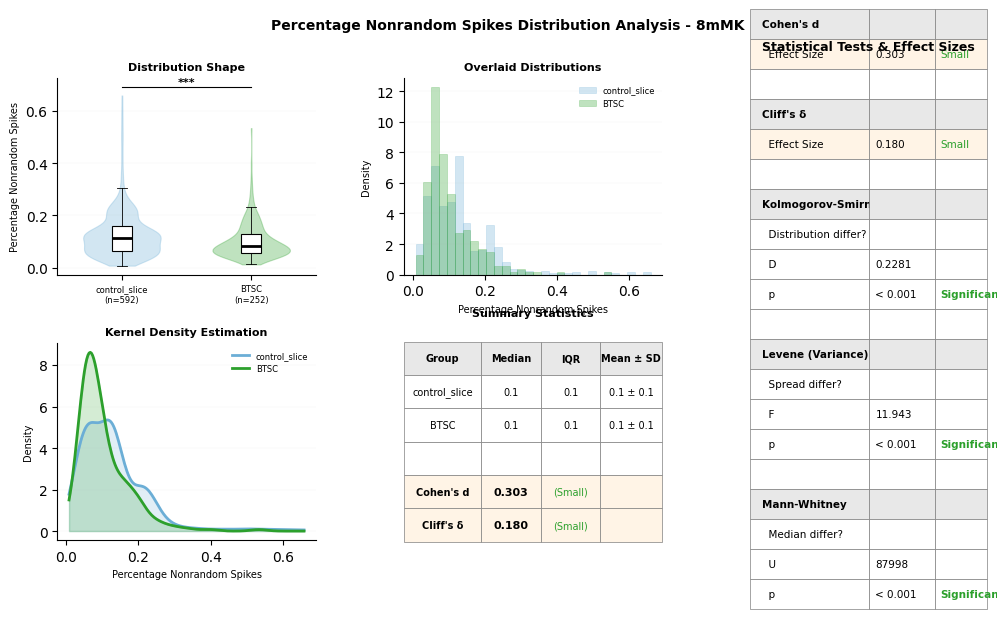

  [hash] 40_panel_percentage_nonrandom_spikes_8mMK_experiment ce4c0991dd5ac239

percentage_nonrandom_spikes | 5uMgabazine | experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_experiment_statistics.txt


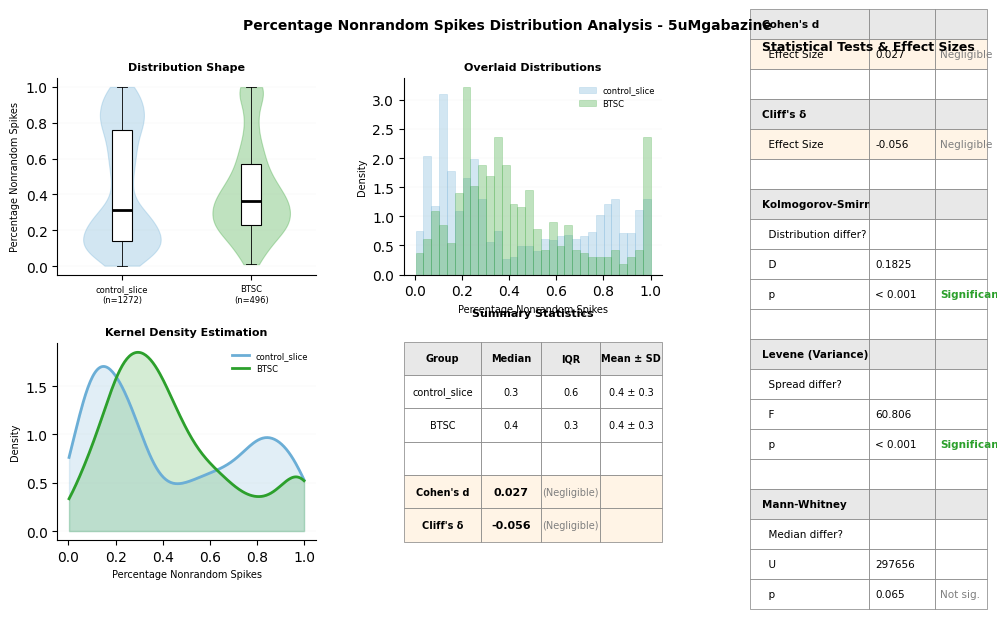

  [hash] 40_panel_percentage_nonrandom_spikes_5uMgabazine_experiment 2e97191ea13ed7ad

degree_centrality | 8mMK | experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_experiment_statistics.txt


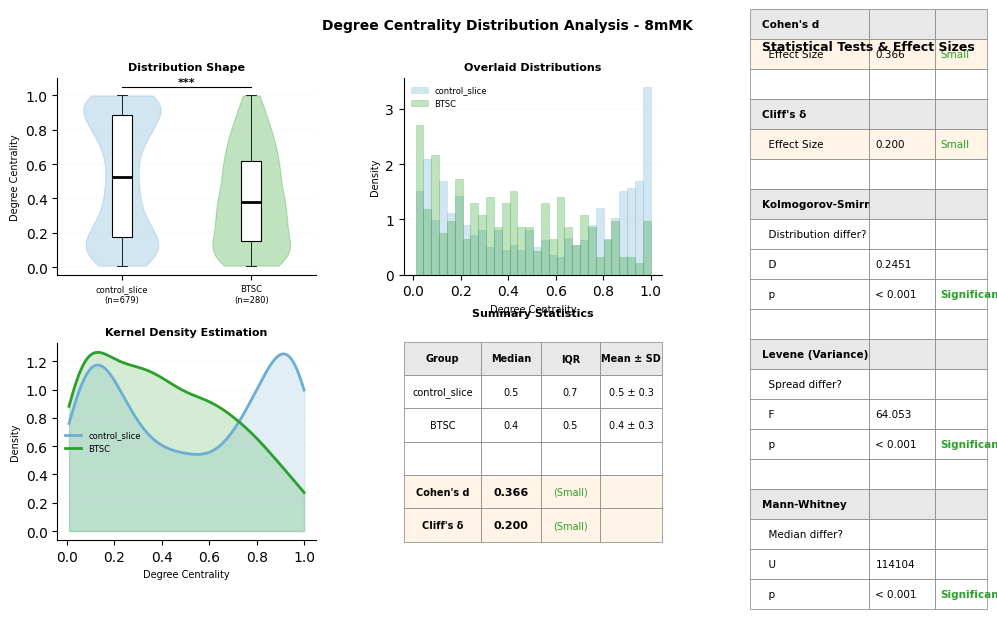

  [hash] 40_panel_degree_centrality_8mMK_experiment    4e3966a52e7a546f

degree_centrality | 5uMgabazine | experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_experiment_statistics.txt


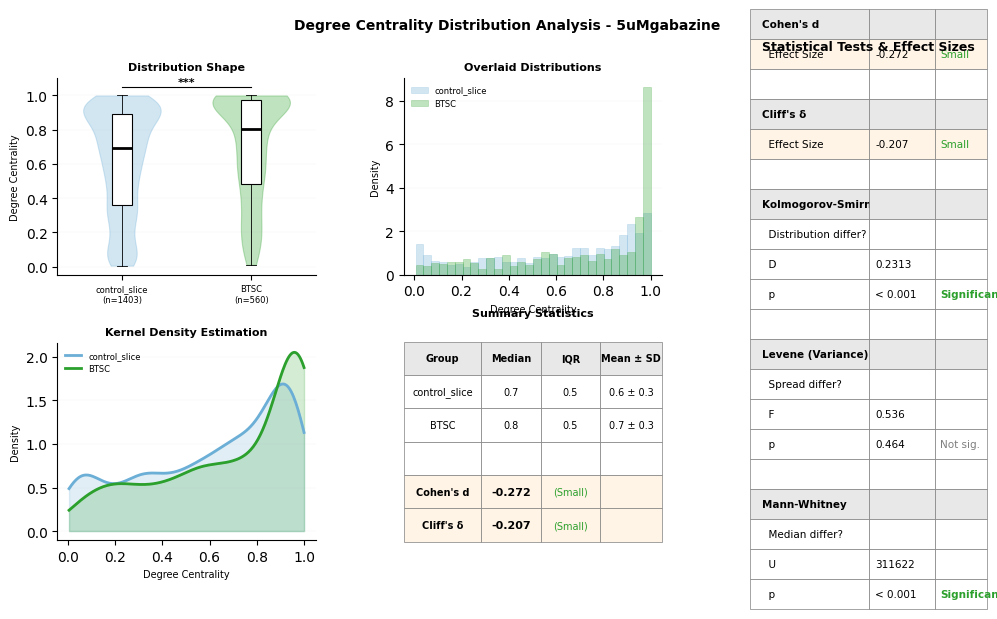

  [hash] 40_panel_degree_centrality_5uMgabazine_experiment 5b94a67d5089c71a

firing_rate | 8mMK | experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_experiment_statistics.txt


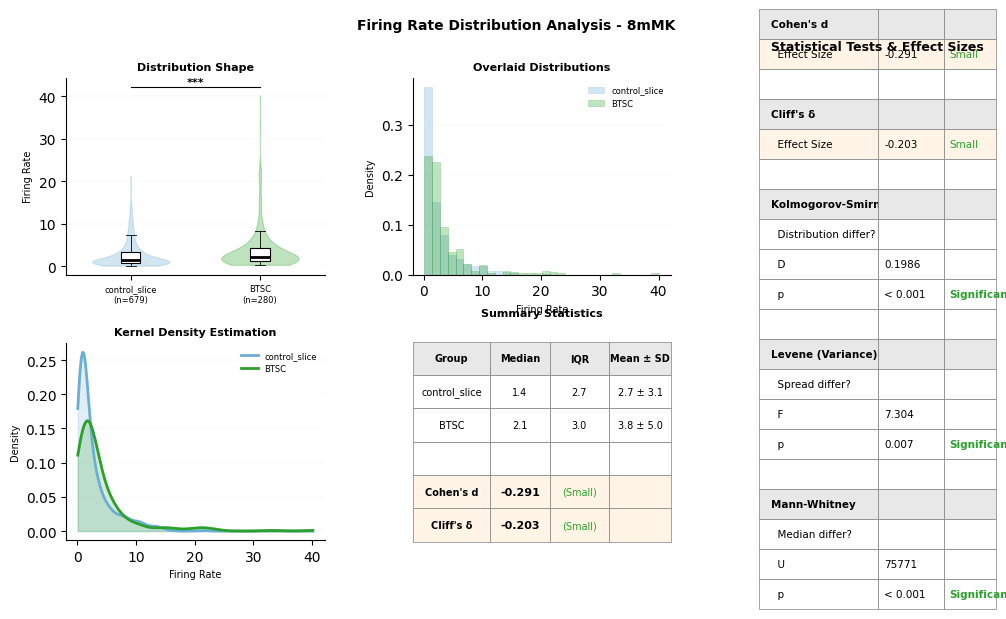

  [hash] 40_panel_firing_rate_8mMK_experiment          a03cc3285a3ca40e

firing_rate | 5uMgabazine | experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_experiment_statistics.txt


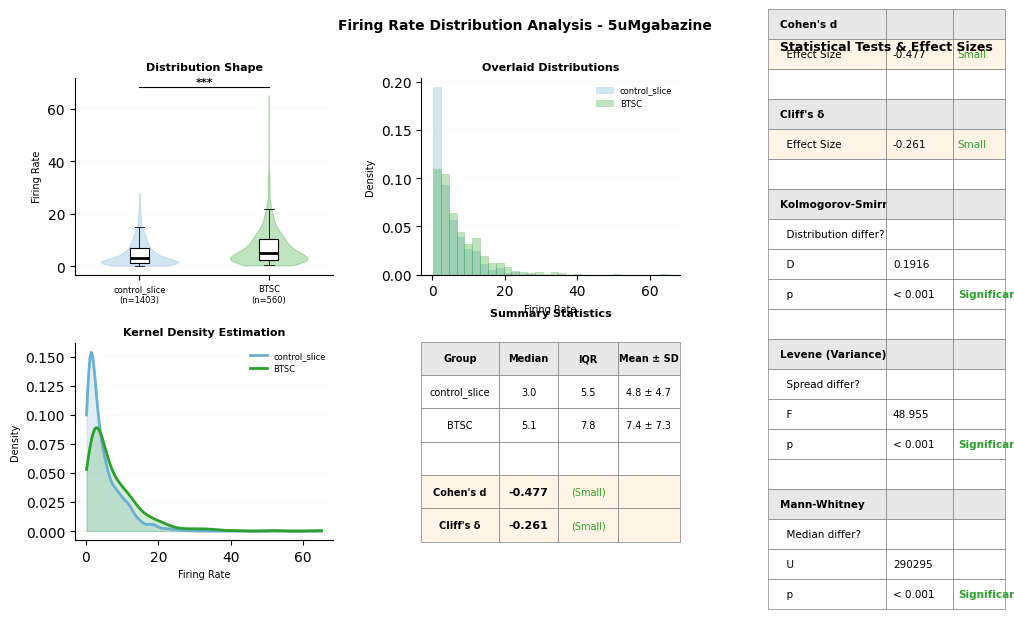

  [hash] 40_panel_firing_rate_5uMgabazine_experiment   95722435e11e4b6a

percentage_nonrandom_spikes | 8mMK | region_experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_region_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_region_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_region_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_8mMK_region_experiment_statistics.txt


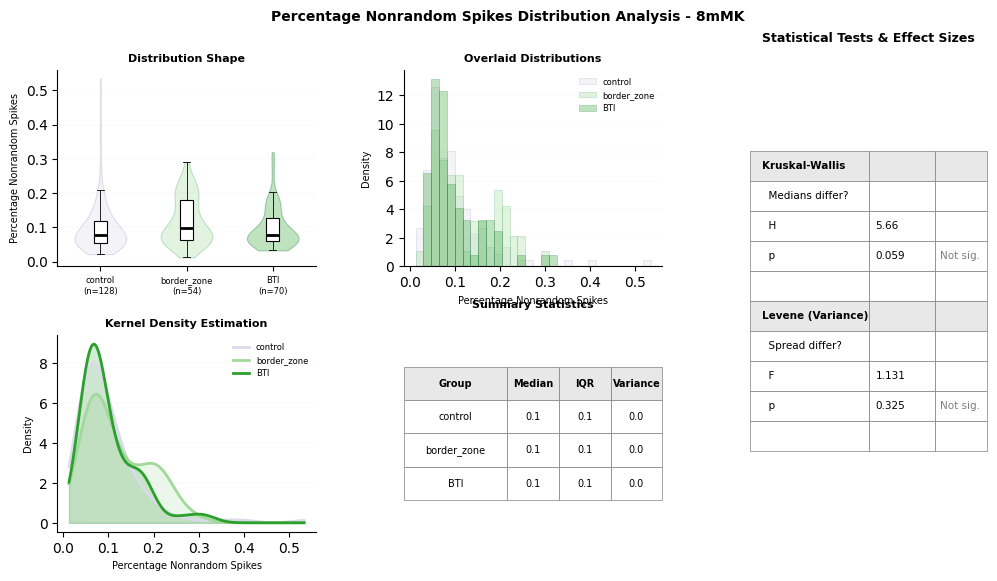

  [hash] 40_panel_percentage_nonrandom_spikes_8mMK_region_experiment 6ac245b6c0bb77b2

percentage_nonrandom_spikes | 5uMgabazine | region_experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_region_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_region_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_region_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_percentage_nonrandom_spikes_5uMgabazine_region_experiment_statistics.txt


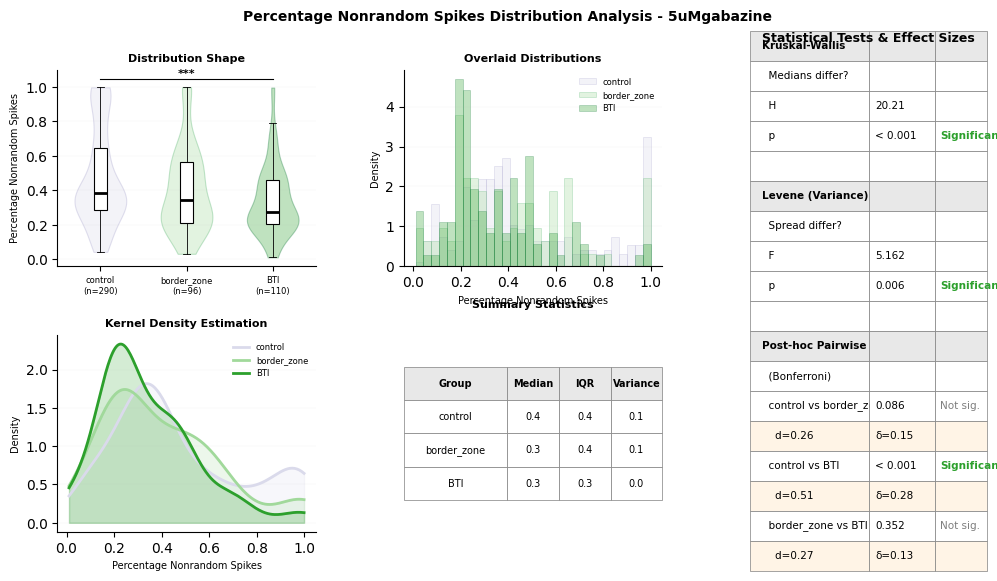

  [hash] 40_panel_percentage_nonrandom_spikes_5uMgabazine_region_experiment 615f468400f930b1

degree_centrality | 8mMK | region_experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_region_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_region_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_region_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_8mMK_region_experiment_statistics.txt


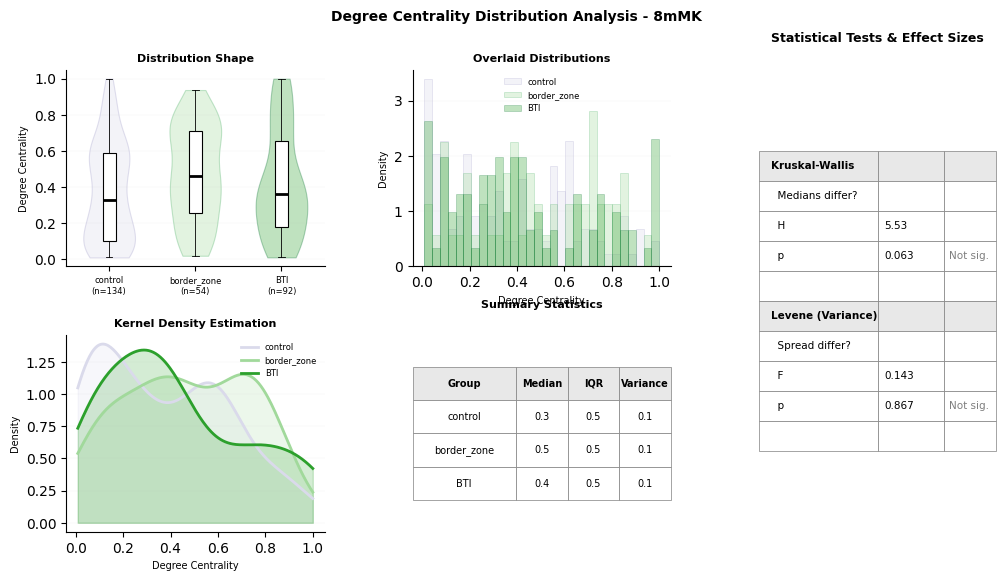

  [hash] 40_panel_degree_centrality_8mMK_region_experiment 7de45b9d0a1d934b

degree_centrality | 5uMgabazine | region_experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_region_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_region_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_region_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_degree_centrality_5uMgabazine_region_experiment_statistics.txt


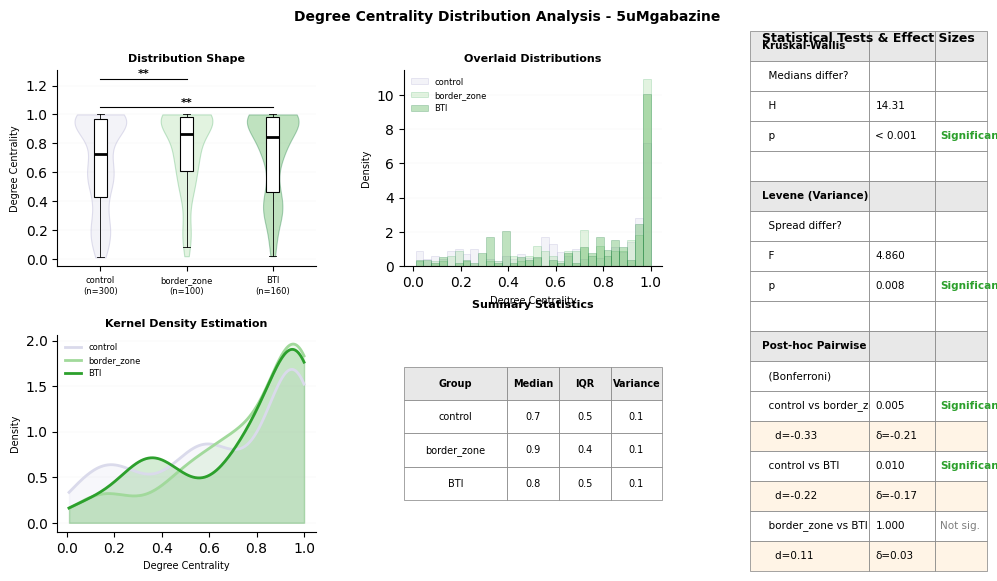

  [hash] 40_panel_degree_centrality_5uMgabazine_region_experiment 3c6fa7e13f01b7c1

firing_rate | 8mMK | region_experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_region_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_region_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_region_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_8mMK_region_experiment_statistics.txt


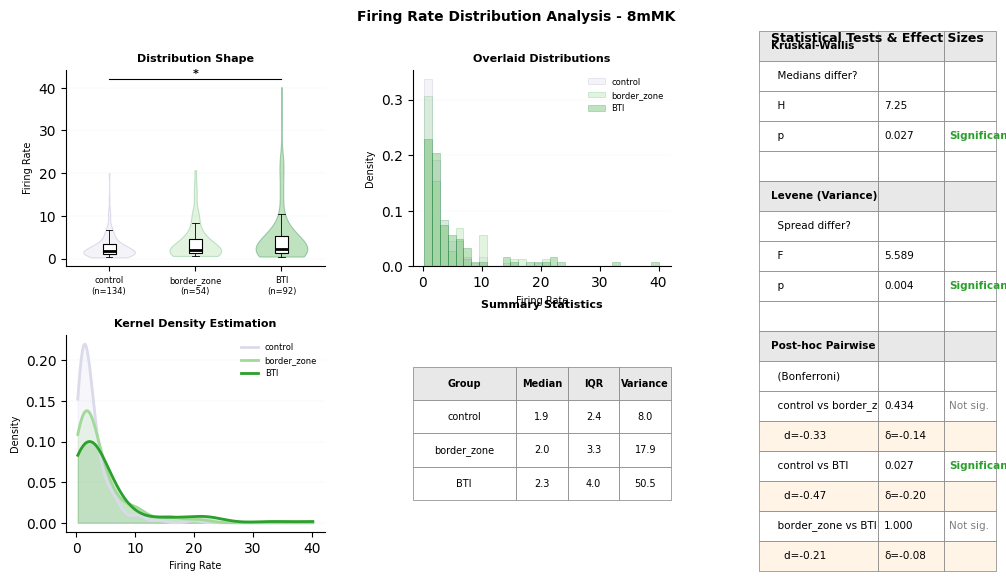

  [hash] 40_panel_firing_rate_8mMK_region_experiment   74c0c1345c35bf7b

firing_rate | 5uMgabazine | region_experiment


/tmp/ipykernel_4974/838991277.py:701: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


SVG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_region_experiment.svg


PNG saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_region_experiment.png


PDF saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_region_experiment.pdf
Statistics log saved to: /content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____final_hashcontrol_versions_24112026/panel_distribution_firing_rate_5uMgabazine_region_experiment_statistics.txt


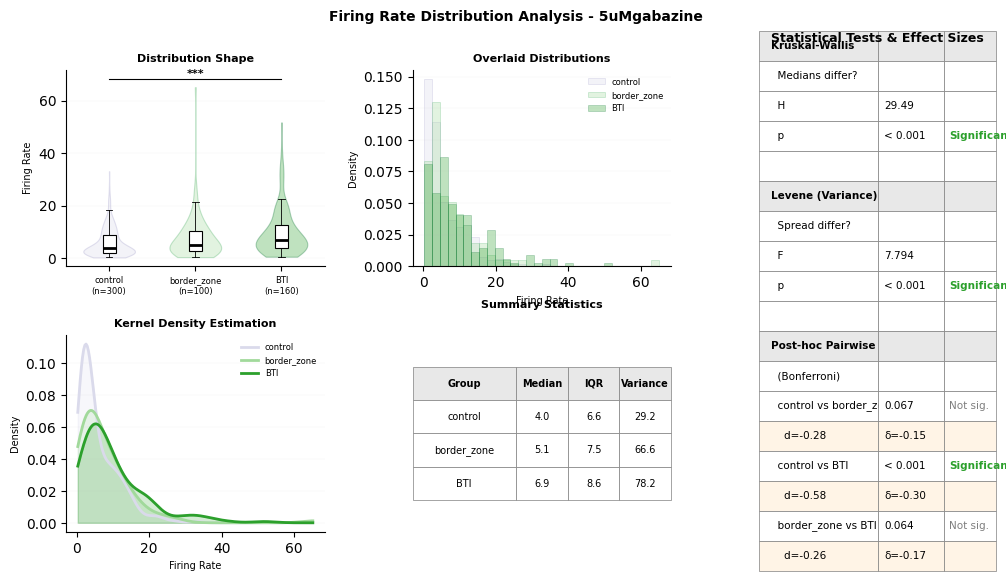

  [hash] 40_panel_firing_rate_5uMgabazine_region_experiment c1ae02109758952a

Produced 12 distribution panels


In [22]:
# =============================================================================
# DISTRIBUTION PANELS (Fig 4E/G, Suppl 2a–f)
# =============================================================================
# plot_metric_distributions is ported UNCHANGED from the original notebook
# (live version, line 5649). It contains a manual Bonferroni on the violin-panel
# significance bars (p * n_comparisons); this is preserved verbatim to reproduce
# the published panels exactly. The correction behaviour is discussed in the
# response letter, not altered here.
#
# >>> paste the full body of plot_metric_distributions(...) here, unchanged <
# (lines 5649–~6300 of 03112025_statistics_and_plots.py)


# --- exact parameter combinations used in the paper -------------------------
# (metric, comparison_type) x (drug). comparison_type 'experiment' = control
# slice vs tumour slice; 'region_experiment'/'region' = no-tumor/LTD/HTD in BTSC.

PANEL_SPECS = [
    # metric,                        comparison_type
    ('percentage_nonrandom_spikes',  'experiment'),        # Fig 4E / Suppl 2b
    ('degree_centrality',            'experiment'),        # Fig 4G / Suppl 2c
    ('firing_rate',                  'experiment'),        # Suppl 2a
    ('percentage_nonrandom_spikes',  'region_experiment'), # Suppl 2e
    ('degree_centrality',            'region_experiment'), # Suppl 2f
    ('firing_rate',                  'region_experiment'), # Suppl 2d
]
PANEL_DRUGS = ['8mMK', '5uMgabazine']

panel_summaries = {}
for metric, comparison_type in PANEL_SPECS:
    for drug in PANEL_DRUGS:
        print("\n" + "=" * 70)
        print(f"{metric} | {drug} | {comparison_type}")
        print("=" * 70)

        summary = plot_metric_distributions(
            nodes_thresh,
            metric=metric,
            filter_drug=drug,
            comparison_type=comparison_type,
            log_x=False,
            log_y=False,
            save_path=(f'{OUT_DIR}/panel_distribution_'
                       f'{metric}_{drug}_{comparison_type}.svg')
        )

        key = f"{metric}_{drug}_{comparison_type}"
        panel_summaries[key] = summary
        # summary is the filtered DataFrame the function returns; hash a stable
        # numeric digest of it rather than the frame (which may carry object cols)
        if isinstance(summary, pd.DataFrame) and metric in summary.columns:
            digest = (summary.groupby(
                        'region_experiment' if 'region' in comparison_type
                        else 'experiment')[metric]
                      .agg(['count', 'median', 'mean', 'std']))
            record(f"40_panel_{key}", digest)

print(f"\nProduced {len(panel_summaries)} distribution panels")

# spring layout graphs

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib import rcParams
from matplotlib.font_manager import fontManager
import networkx as nx
import os


def set_publication_fonts():
    """
    Set publication-ready fonts with fallback for different environments.
    Prioritizes: Helvetica > Arial > Liberation Sans > DejaVu Sans
    """
    # Get available font families
    available_fonts = set(f.name for f in fontManager.ttflist)

    # Priority list of sans-serif fonts
    preferred_fonts = ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans']

    selected_font = None
    for font in preferred_fonts:
        if font in available_fonts:
            selected_font = font
            break

    if selected_font is None:
        selected_font = 'sans-serif'  # Fallback to default

    rcParams["font.family"] = selected_font
    rcParams["pdf.fonttype"] = 42  # TrueType fonts for editability

    return selected_font


def plot_mea_spring_layout(G,
                          # Core layout parameters
                          layout_algorithm='spring',
                          k=None, iterations=50, seed=42,

                          # Node customization - simplified
                          node_color_by='firing_rate',  # 'firing_rate' or 'percentage_nonrandom_spikes'
                          node_alpha=0.8,
                          vmin=None,  # Minimum value for colorbar
                          vmax=None,  # Maximum value for colorbar

                          # Edge customization
                          edge_weight_threshold=0.0,  # Threshold for normalized weights
                          edge_alpha=0.6,

                          # Color schemes
                          colormap='viridis',

                          # Visual options
                          show_labels=False,
                          label_size=8,

                          # Layout and saving
                          figsize=(12, 10),
                          title=None,
                          save_path=None,
                          dpi=300,
                          show_axes=False):
    """
    MEA network visualization with degree-based node sizes and firing rate coloring.
    Saves PNG, SVG, and PDF formats.

    Parameters
    ----------
    G : networkx.Graph
        Input graph with node attributes
    k : float, optional
        Optimal distance between nodes for spring layout (None = auto)
    node_color_by : str
        'firing_rate' or 'percentage_nonrandom_spikes'
    vmin : float, optional
        Minimum value for colorbar scale
    vmax : float, optional
        Maximum value for colorbar scale
    edge_weight_threshold : float
        Minimum normalized edge weight to display (0-1)
    colormap : str
        Colormap for node coloring
    save_path : str, optional
        Path to save figure (saves PNG, SVG, and PDF)
    """
    # Set up PDF-compatible font settings with fallback
    selected_font = set_publication_fonts()

    # Create figure
    fig, ax = plt.subplots(figsize=figsize)

    # Generate layout
    if layout_algorithm == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G, max_iter=iterations, scale=1.0)
    else:
        pos = nx.spring_layout(G, k=k, iterations=iterations, seed=seed)

    # Filter edges by threshold
    G_display = G.copy()
    edges_to_remove = [(u, v) for u, v, d in G_display.edges(data=True)
                      if d.get('weight', 0) < edge_weight_threshold]
    G_display.remove_edges_from(edges_to_remove)

    # Calculate node sizes based on degree bins
    node_sizes = {}
    for node in G.nodes():
        degree = G.degree(node)
        if degree <= 10:
            node_sizes[node] = 100
        elif degree <= 50:
            node_sizes[node] = 250
        elif degree <= 100:
            node_sizes[node] = 400
        else:
            node_sizes[node] = 600

    # Calculate node colors based on metric
    node_color_values = []
    color_data = []
    for node in G.nodes():
        if node_color_by == 'percentage_nonrandom_spikes':
            val = G.nodes[node].get('percentage_nonrandom_spikes', 0)
        else:  # firing_rate
            val = G.nodes[node].get('firing_rate', 0)
        color_data.append(val)

    # Create colormap with custom vmin/vmax
    if len(set(color_data)) > 1:
        # Use provided vmin/vmax or calculate from data
        color_min = vmin if vmin is not None else min(color_data)
        color_max = vmax if vmax is not None else max(color_data)

        norm = Normalize(vmin=color_min, vmax=color_max)
        cmap = cm.get_cmap(colormap)
        node_color_values = [cmap(norm(val)) for val in color_data]
    else:
        node_color_values = ['#1f78b4'] * len(G.nodes())
        norm = None

    # Draw edges
    edge_weights = [d.get('weight', 1) for u, v, d in G_display.edges(data=True)]
    if len(set(edge_weights)) > 1:
        min_w, max_w = min(edge_weights), max(edge_weights)
        edge_widths = [0.5 + (w - min_w) / (max_w - min_w) * 4.5 for w in edge_weights]
    else:
        edge_widths = [1.0] * len(G_display.edges())

    nx.draw_networkx_edges(G_display, pos,
                          width=edge_widths,
                          edge_color='gray',
                          alpha=edge_alpha,
                          ax=ax)

    # Draw nodes
    node_list = list(G.nodes())
    sizes_list = [node_sizes[node] for node in node_list]

    nx.draw_networkx_nodes(G, pos,
                         nodelist=node_list,
                         node_size=sizes_list,
                         node_color=node_color_values,
                         alpha=node_alpha,
                         ax=ax)

    # Add labels if requested
    if show_labels:
        nx.draw_networkx_labels(G, pos, font_size=label_size, ax=ax)

    # Remove axes
    if not show_axes:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    if title:
        ax.set_title(title, fontsize=14, fontweight='bold', pad=20)

    # Add colorbar - ALWAYS shown
    if len(set(color_data)) > 1 and norm is not None:
        sm = cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, shrink=0.6, aspect=20, pad=0.02)

        if node_color_by == 'percentage_nonrandom_spikes':
            cbar.set_label('% Non-random Spikes', fontsize=11)
        else:
            cbar.set_label('Firing Rate (Hz)', fontsize=11)

    # Add degree size legend
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w',
                  markerfacecolor='gray', markersize=6,
                  label='1-10', markeredgecolor='black', markeredgewidth=0.5),
        plt.Line2D([0], [0], marker='o', color='w',
                  markerfacecolor='gray', markersize=9.5,
                  label='11-50', markeredgecolor='black', markeredgewidth=0.5),
        plt.Line2D([0], [0], marker='o', color='w',
                  markerfacecolor='gray', markersize=12,
                  label='51-100', markeredgecolor='black', markeredgewidth=0.5),
        plt.Line2D([0], [0], marker='o', color='w',
                  markerfacecolor='gray', markersize=15,
                  label='>100', markeredgecolor='black', markeredgewidth=0.5)
    ]

    ax.legend(handles=legend_elements, loc='upper left',
             title='Node Degree', framealpha=0.9, fontsize=9)

    plt.tight_layout()

    # Save if requested - PNG, SVG, and PDF
    if save_path:
        base_path = os.path.splitext(save_path)[0]

        # Save SVG
        svg_path = base_path + '.svg'
        plt.savefig(svg_path, format='svg', bbox_inches='tight')
        print(f"SVG saved to: {svg_path}")

        # Save PNG
        png_path = base_path + '.png'
        plt.savefig(png_path, dpi=dpi, bbox_inches='tight')
        print(f"PNG saved to: {png_path}")

        # Save PDF with proper font settings for editability
        pdf_path = base_path + '.pdf'
        plt.savefig(pdf_path, format='pdf', dpi=dpi, bbox_inches='tight')
        print(f"PDF saved to: {pdf_path}")

    return fig, ax, pos


def batch_plot_mea_networks(graph_dict,
                           output_dir,
                           node_color_by='firing_rate',
                           edge_weight_threshold=0.3,
                           colormap='viridis',
                           k=None,  # Spring layout parameter
                           vmin=None,  # Min colorbar value
                           vmax=None,  # Max colorbar value
                           dpi=300,
                           figsize=(12, 10),
                           **kwargs):
    """
    Batch process multiple MEA graphs and save as high-resolution SVG, PNG, and PDF.

    Parameters
    ----------
    graph_dict : dict
        Dictionary with {filename: Graph} pairs
    output_dir : str
        Directory to save files (SVG, PNG, PDF for each graph)
    node_color_by : str
        'firing_rate' or 'percentage_nonrandom_spikes'
    edge_weight_threshold : float
        Minimum normalized edge weight threshold
    k : float, optional
        Optimal distance between nodes for spring layout
    vmin : float, optional
        Minimum value for colorbar scale
    vmax : float, optional
        Maximum value for colorbar scale
    """
    # Set up fonts once at the start
    selected_font = set_publication_fonts()
    print(f"Using font: {selected_font}")

    # Create output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)

    # Determine metric prefix for filename
    if node_color_by == 'percentage_nonrandom_spikes':
        metric_prefix = 'pct_nonrandom'
    else:
        metric_prefix = 'firing_rate'

    print(f"Processing {len(graph_dict)} graphs...")
    print(f"Output directory: {output_dir}")
    print(f"Coloring by: {node_color_by}")
    print(f"Edge threshold: {edge_weight_threshold}")
    print(f"Spring k: {k if k is not None else 'auto'}")
    print(f"Colorbar range: [{vmin if vmin is not None else 'auto'}, {vmax if vmax is not None else 'auto'}]\n")

    for i, (filename, G) in enumerate(graph_dict.items(), 1):
        try:
            # Remove file extension if present
            base_name = os.path.splitext(filename)[0]

            # Create output filename (without extension - plot_mea_spring_layout adds them)
            output_filename = f"{metric_prefix}_{base_name}"
            save_path = os.path.join(output_dir, output_filename)

            # Create title from filename
            title = base_name.replace('_', ' ').title()

            # Generate plot
            fig, ax, pos = plot_mea_spring_layout(
                G,
                node_color_by=node_color_by,
                edge_weight_threshold=edge_weight_threshold,
                colormap=colormap,
                k=k,
                vmin=vmin,
                vmax=vmax,
                figsize=figsize,
                title=title,
                save_path=save_path,
                dpi=dpi,
                **kwargs
            )

            plt.close(fig)  # Close to free memory

            print(f"[{i}/{len(graph_dict)}] Completed: {output_filename}\n")

        except Exception as e:
            print(f"[{i}/{len(graph_dict)}] ERROR processing {filename}: {str(e)}")
            continue

    print(f"\nBatch processing complete! Files saved to: {output_dir}")


def batch_plot_both_metrics(graph_dict,
                            output_dir,
                            edge_weight_threshold=0.3,
                            colormap='viridis',
                            k=None,
                            firing_rate_vmin=None,
                            firing_rate_vmax=None,
                            percentage_vmin=None,
                            percentage_vmax=None,
                            **kwargs):
    """
    Process all graphs with BOTH metrics (firing_rate and percentage_nonrandom_spikes).
    Saves PNG, SVG, and PDF for each graph.

    Parameters
    ----------
    graph_dict : dict
        Dictionary with {filename: Graph} pairs
    output_dir : str
        Directory to save files (SVG, PNG, PDF for each graph)
    k : float, optional
        Optimal distance between nodes for spring layout
    firing_rate_vmin/vmax : float, optional
        Colorbar range for firing rate
    percentage_vmin/vmax : float, optional
        Colorbar range for percentage non-random spikes
    """
    # Set up fonts once at the start
    selected_font = set_publication_fonts()
    print(f"Using font: {selected_font}\n")

    print("=" * 60)
    print("BATCH PROCESSING: FIRING RATE")
    print("=" * 60)
    batch_plot_mea_networks(
        graph_dict,
        output_dir,
        node_color_by='firing_rate',
        edge_weight_threshold=edge_weight_threshold,
        colormap=colormap,
        k=k,
        vmin=firing_rate_vmin,
        vmax=firing_rate_vmax,
        **kwargs
    )

    print("\n" + "=" * 60)
    print("BATCH PROCESSING: PERCENTAGE NON-RANDOM SPIKES")
    print("=" * 60)
    batch_plot_mea_networks(
        graph_dict,
        output_dir,
        node_color_by='percentage_nonrandom_spikes',
        edge_weight_threshold=edge_weight_threshold,
        colormap=colormap,
        k=k,
        vmin=percentage_vmin,
        vmax=percentage_vmax,
        **kwargs
    )

In [24]:
# Example 3: Both metrics with different ranges
'''
batch_plot_both_metrics(
    graph_dict=graphs,
    output_dir='/content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____hashcontrol_versions_aftercleaning_20082026',
    k=2,
    firing_rate_vmin=0,
    firing_rate_vmax=5,
    percentage_vmin=0,
    percentage_vmax=0.3,
    edge_weight_threshold=0.1,
    colormap = 'viridis'

)
'''

"\nbatch_plot_both_metrics(\n    graph_dict=graphs,\n    output_dir='/content/drive/Shareddrives/_data/MEA_datasets_NEW/Tumor engraftment/pkl_collection_14042025/____hashcontrol_versions_aftercleaning_20082026',\n    k=2,\n    firing_rate_vmin=0,\n    firing_rate_vmax=5,\n    percentage_vmin=0,\n    percentage_vmax=0.3,\n    edge_weight_threshold=0.1,\n    colormap = 'viridis'\n\n)\n"

# exploration Hub Definition


In [25]:
# =============================================================================
# EXPLORATORY: hub quadrant classification (degree x network participation)
# =============================================================================
# Cross-classify electrodes by degree AND network-spike participation, then test
# regional distribution of the four quadrants — with a firing-rate-stratified
# null, since degree is rate-linked.
#
# Quadrants:
#   integrated_hub : high degree + high participation  (real hub)
#   false_hub      : high degree + low  participation  (connected-looking but
#                    not joining population events -> "hyperactive, decoupled")
#   coordinated    : low  degree + high participation
#   peripheral     : low  degree + low  participation

DEG_PCT  = 25    # top 25% degree = "high degree"
PART_PCT = 50    # top 50% network participation = "high participation"


def classify_hub_quadrants(nodes_df, drug_condition,
                           deg_col='degree_centrality',
                           part_col='percentage_nonrandom_spikes',
                           rate_col='firing_rate',
                           deg_pct=DEG_PCT, part_pct=PART_PCT):
    """Per-recording thresholds (as in the enrichment tests), then quadrant label."""
    d = nodes_df[(nodes_df['experiment'] == 'BTSC') &
                 (nodes_df['drug'].str.contains(drug_condition, na=False, case=False))].copy()
    d = d[d[deg_col].notna() & d[part_col].notna()].reset_index(drop=True)

    high_deg  = np.zeros(len(d), dtype=bool)
    high_part = np.zeros(len(d), dtype=bool)
    for fn in d['filename'].unique():
        m = (d['filename'] == fn).values
        # NOTE: participation threshold computed on all nodes in the recording,
        # including zero-participation electrodes (no >0 filter here, so the
        # quadrants cover every electrode). State this choice explicitly.
        deg_thr  = np.percentile(d.loc[m, deg_col],  100 - deg_pct)
        part_thr = np.percentile(d.loc[m, part_col], 100 - part_pct)
        high_deg  |= m & (d[deg_col].values  >= deg_thr)
        high_part |= m & (d[part_col].values >= part_thr)

    quad = np.where(high_deg & high_part,  'integrated_hub',
           np.where(high_deg & ~high_part, 'false_hub',
           np.where(~high_deg & high_part, 'coordinated', 'peripheral')))
    d['quadrant']  = quad
    d['high_deg']  = high_deg
    d['high_part'] = high_part
    return d


def quadrant_region_table(d, region_col='region_experiment'):
    """Counts and within-region proportions of each quadrant."""
    ct = pd.crosstab(d[region_col], d['quadrant'])
    prop = ct.div(ct.sum(axis=1), axis=0)
    return ct, prop


# --- run for both conditions ------------------------------------------------
REGION_ORDER = ['control', 'border_zone', 'BTI']
QUAD_ORDER   = ['integrated_hub', 'false_hub', 'coordinated', 'peripheral']

quad_results = {}
for drug in ['8mMK', '5uMgabazine']:
    d = classify_hub_quadrants(nodes_thresh, drug)
    ct, prop = quadrant_region_table(d)
    ct   = ct.reindex(index=REGION_ORDER, columns=QUAD_ORDER)
    prop = prop.reindex(index=REGION_ORDER, columns=QUAD_ORDER)
    quad_results[drug] = {'data': d, 'counts': ct, 'proportions': prop}

    print("\n" + "=" * 60)
    print(f"{drug}  — quadrant counts by region")
    print("=" * 60)
    print(ct.to_string())
    print("\nwithin-region proportions:")
    print(prop.round(3).to_string())

    record(f"50_quadrant_counts_{drug}", ct.fillna(0).astype(int))
    record(f"50_quadrant_props_{drug}", prop.fillna(0))


8mMK  — quadrant counts by region
quadrant           integrated_hub  false_hub  coordinated  peripheral
region_experiment                                                    
control                        13         18           46          51
border_zone                    11          8           24          11
BTI                             7         12           26          25

within-region proportions:
quadrant           integrated_hub  false_hub  coordinated  peripheral
region_experiment                                                    
control                    0.1020     0.1410       0.3590      0.3980
border_zone                0.2040     0.1480       0.4440      0.2040
BTI                        0.1000     0.1710       0.3710      0.3570
  [hash] 50_quadrant_counts_8mMK                       247df40e1e6567d0
  [hash] 50_quadrant_props_8mMK                        b002a415fd3093b7

5uMgabazine  — quadrant counts by region
quadrant           integrated_hub  false_hub  coord

In [26]:
# =============================================================================
# EXPLORATORY: false-hub quadrant enrichment, rate-stratified
# =============================================================================
# Is the "false hub" quadrant (high degree, low participation) enriched in HTD
# beyond firing rate? Permute the binary false_hub label globally and within
# firing-rate deciles; compare observed HTD/LTD/control enrichment to both nulls.

def permute_quadrant_enrichment(d, quadrant='false_hub',
                                region_col='region_experiment',
                                rate_col='firing_rate',
                                n_perm=10000, n_rate_bins=10, seed=0):
    """d = output of classify_hub_quadrants (one drug). Returns tidy DataFrame."""
    d = d.reset_index(drop=True)
    is_q = (d['quadrant'] == quadrant).values
    regions = [r for r in ['control', 'border_zone', 'BTI']
               if r in d[region_col].unique()]
    rmask = {r: (d[region_col] == r).values for r in regions}

    def enrich(flag, m):
        nq = flag.sum()
        return np.nan if nq == 0 else (m & flag).sum()/nq / (m.sum()/len(flag))

    obs = {r: enrich(is_q, rmask[r]) for r in regions}

    rng = np.random.default_rng(seed)
    deciles = pd.qcut(d[rate_col], q=n_rate_bins, labels=False,
                      duplicates='drop').values
    strata = {'global': [np.arange(len(d))],
              'rate':   [np.where(deciles == b)[0] for b in np.unique(deciles)]}

    rows = []
    for name, idx_sets in strata.items():
        null = {r: np.empty(n_perm) for r in regions}
        for i in range(n_perm):
            sh = is_q.copy()
            for idx in idx_sets:
                sh[idx] = rng.permutation(is_q[idx])
            nq = sh.sum()
            for r in regions:
                null[r][i] = (rmask[r] & sh).sum()/nq / (rmask[r].sum()/len(d))
        for r in regions:
            dev = abs(obs[r] - 1.0)
            rows.append({'quadrant': quadrant, 'strata': name, 'region': r,
                         'observed': obs[r],
                         'p': float((np.abs(null[r]-1.0) >= dev).mean()),
                         'n_quadrant': int(is_q.sum()),
                         'n_region': int(rmask[r].sum())})
    return pd.DataFrame(rows)


quad_enrich = []
for drug in ['8mMK', '5uMgabazine']:
    for quad in ['false_hub', 'integrated_hub']:
        t = permute_quadrant_enrichment(quad_results[drug]['data'], quadrant=quad)
        t.insert(0, 'drug', drug)
        quad_enrich.append(t)

quad_enrich = pd.concat(quad_enrich, ignore_index=True)
record("51_quadrant_enrichment", quad_enrich)
print(quad_enrich.pivot_table(index=['drug','quadrant','region'],
                              columns='strata', values=['observed','p']).round(4).to_string())

  [hash] 51_quadrant_enrichment                        6c88a97750c096eb
                                       observed             p       
strata                                   global   rate global   rate
drug        quadrant       region                                   
5uMgabazine false_hub      BTI           1.6684 1.6684 0.0000 0.0002
                           border_zone   1.1883 1.1883 0.3203 0.5296
                           control       0.6841 0.6841 0.0000 0.0010
            integrated_hub BTI           1.0122 1.0122 1.0000 1.0000
                           border_zone   0.8435 0.8435 0.7007 0.7225
                           control       1.0471 1.0471 0.7579 0.8526
8mMK        false_hub      BTI           1.1368 1.1368 0.6937 0.6890
                           border_zone   0.9825 0.9825 1.0000 1.0000
                           control       0.9326 0.9326 0.7258 0.8671
            integrated_hub BTI           0.8129 0.8129 0.5257 0.5247
                           bord

In [27]:
# =============================================================================
# HUB QUADRANT FIGURE — exploratory (degree x network participation)
# =============================================================================
# Row = drug. Col 1: electrode scatter with quadrant thresholds. Col 2: quadrant
# composition per region. Col 3: false-hub enrichment vs global + rate nulls.

import matplotlib.font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

_AVAIL = {f.name for f in fm.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']
             if f in _AVAIL), 'sans-serif')

REGION_ORDER  = ['control', 'border_zone', 'BTI']
REGION_LABELS = {'control': 'no tumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
QUAD_ORDER    = ['integrated_hub', 'false_hub', 'coordinated', 'peripheral']
QUAD_LABELS   = {'integrated_hub': 'integrated hub\n(hi deg, hi part)',
                 'false_hub': 'false hub\n(hi deg, lo part)',
                 'coordinated': 'coordinated\n(lo deg, hi part)',
                 'peripheral': 'peripheral\n(lo deg, lo part)'}
QUAD_COLORS   = {'integrated_hub': '#2166AC', 'false_hub': '#B2182B',
                 'coordinated': '#92C5DE', 'peripheral': '#E0E0E0'}
DRUG_LABELS   = {'8mMK': 'Baseline', '5uMgabazine': 'Gabazine'}


def _median_thresholds(d, deg_col, part_col, deg_pct, part_pct):
    """Pooled threshold lines for display only (per-recording thresholds define
    the actual labels; these lines are a visual guide at the pooled median cut)."""
    return (np.percentile(d[deg_col], 100 - deg_pct),
            np.percentile(d[part_col], 100 - part_pct))


def plot_quadrant_figure(quad_results, quad_enrich, nulls_source,
                         deg_col='degree_centrality',
                         part_col='percentage_nonrandom_spikes',
                         deg_pct=25, part_pct=50, save_path=None):
    drugs = ['8mMK', '5uMgabazine']
    with plt.rc_context({'font.family': FONT, 'pdf.fonttype': 42,
                         'svg.fonttype': 'none', 'font.size': 8}):
        fig = plt.figure(figsize=(13, 7.6))
        gs = fig.add_gridspec(2, 3, width_ratios=[1.25, 1.0, 1.2],
                              hspace=0.45, wspace=0.34,
                              left=0.06, right=0.99, top=0.93, bottom=0.10)

        for r, drug in enumerate(drugs):
            d = quad_results[drug]['data']
            prop = quad_results[drug]['proportions']

            # ---- col 1: electrode scatter -------------------------------
            ax = fig.add_subplot(gs[r, 0])
            dthr, pthr = _median_thresholds(d, deg_col, part_col, deg_pct, part_pct)
            ax.axvline(dthr, color='0.6', lw=0.6, ls='--', zorder=1)
            ax.axhline(pthr, color='0.6', lw=0.6, ls='--', zorder=1)
            for region in REGION_ORDER:
                sub = d[d['region_experiment'] == region]
                ax.scatter(sub[deg_col], sub[part_col], s=14,
                           color=COLORS_REGION[region], edgecolor='none',
                           alpha=0.55, label=REGION_LABELS[region], zorder=2)
            # annotate the false-hub corner
            ax.text(0.98, 0.02, 'false hub', transform=ax.transAxes,
                    ha='right', va='bottom', fontsize=7, color='#B2182B',
                    fontweight='bold')
            ax.set_xlabel('degree centrality', fontsize=8)
            ax.set_ylabel('% network spikes', fontsize=8)
            ax.set_title(f'{DRUG_LABELS[drug]}  —  electrode classification',
                         fontsize=9, fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)
            if r == 0:
                ax.legend(fontsize=6.5, frameon=False, loc='upper left',
                          markerscale=1.4)

            # ---- col 2: quadrant composition per region -----------------
            ax = fig.add_subplot(gs[r, 1])
            bottom = np.zeros(len(REGION_ORDER))
            x = np.arange(len(REGION_ORDER))
            for quad in QUAD_ORDER:
                vals = prop.reindex(REGION_ORDER)[quad].fillna(0).values
                ax.bar(x, vals, bottom=bottom, width=0.7,
                       color=QUAD_COLORS[quad], edgecolor='white', linewidth=0.5,
                       label=QUAD_LABELS[quad] if r == 0 else None)
                bottom += vals
            ax.set_xticks(x)
            ax.set_xticklabels([REGION_LABELS[rg] for rg in REGION_ORDER], fontsize=7.5)
            ax.set_ylabel('fraction of electrodes', fontsize=8)
            ax.set_ylim(0, 1)
            ax.set_title(f'{DRUG_LABELS[drug]}  —  quadrant composition',
                         fontsize=9, fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)

            # ---- col 3: false-hub enrichment vs nulls -------------------
            ax = fig.add_subplot(gs[r, 2])
            ax.axhline(1.0, color='0.35', lw=0.7, ls=(0, (4, 2)), zorder=1)
            sub = quad_enrich[(quad_enrich['drug'] == drug) &
                              (quad_enrich['quadrant'] == 'false_hub')]
            for k, region in enumerate(REGION_ORDER):
                # violins from the stored null arrays if available
                for strata, width, fc, alpha, z in [
                        ('global', 0.85, '0.82', 1.0, 0),
                        ('rate',   0.5,  COLORS_REGION[region], 0.30, 2)]:
                    nk = (drug, 'false_hub', strata, region)
                    if nk in nulls_source:
                        vp = ax.violinplot(nulls_source[nk], positions=[k],
                                           widths=width, showextrema=False)
                        for b in vp['bodies']:
                            b.set_facecolor(fc); b.set_edgecolor('none')
                            b.set_alpha(alpha); b.set_zorder(z)
                row = sub[sub['region'] == region]
                if not row.empty:
                    e = row['observed'].iloc[0]
                    p_rate = row[row['strata'] == 'rate']['p'].iloc[0] \
                        if 'strata' in row else np.nan
                    ax.scatter([k], [e], s=70, color=COLORS_REGION[region],
                               edgecolor='black', lw=0.7, zorder=4)
            ax.set_xticks(range(len(REGION_ORDER)))
            ax.set_xticklabels([REGION_LABELS[rg] for rg in REGION_ORDER], fontsize=7.5)
            ax.set_ylabel('false-hub enrichment\n(obs / exp)', fontsize=8)
            ax.set_title(f'{DRUG_LABELS[drug]}  —  false-hub enrichment',
                         fontsize=9, fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)

        # shared quadrant legend under col 2
        handles = [Patch(facecolor=QUAD_COLORS[q], label=QUAD_LABELS[q].replace('\n', ' '))
                   for q in QUAD_ORDER]
        fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False,
                   fontsize=7, bbox_to_anchor=(0.5, 0.0))

        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'), dpi=300,
                            bbox_inches='tight')
        plt.show()
    return fig

In [28]:
# =============================================================================
# HUB QUADRANT FIGURE — exploratory (degree x network participation)
# =============================================================================
# Row = drug. Col 1: electrode scatter with quadrant thresholds. Col 2: quadrant
# composition per region. Col 3: false-hub enrichment vs global + rate nulls,
# with observed ratio + rate-stratified p labelled on each point.

import matplotlib.font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

_AVAIL = {f.name for f in fm.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']
             if f in _AVAIL), 'sans-serif')

REGION_ORDER  = ['control', 'border_zone', 'BTI']
REGION_LABELS = {'control': 'no tumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
QUAD_ORDER    = ['integrated_hub', 'false_hub', 'coordinated', 'peripheral']
QUAD_LABELS   = {'integrated_hub': 'integrated hub\n(hi deg, hi part)',
                 'false_hub': 'false hub\n(hi deg, lo part)',
                 'coordinated': 'coordinated\n(lo deg, hi part)',
                 'peripheral': 'peripheral\n(lo deg, lo part)'}
QUAD_COLORS   = {'integrated_hub': '#2166AC', 'false_hub': '#B2182B',
                 'coordinated': '#92C5DE', 'peripheral': '#E0E0E0'}
DRUG_LABELS   = {'8mMK': 'Baseline', '5uMgabazine': 'Gabazine'}


def _median_thresholds(d, deg_col, part_col, deg_pct, part_pct):
    return (np.percentile(d[deg_col], 100 - deg_pct),
            np.percentile(d[part_col], 100 - part_pct))


def plot_quadrant_figure(quad_results, quad_enrich, nulls_source,
                         deg_col='degree_centrality',
                         part_col='percentage_nonrandom_spikes',
                         deg_pct=25, part_pct=50, save_path=None):
    drugs = ['8mMK', '5uMgabazine']
    with plt.rc_context({'font.family': FONT, 'pdf.fonttype': 42,
                         'svg.fonttype': 'none', 'font.size': 8}):
        fig = plt.figure(figsize=(13, 7.6))
        gs = fig.add_gridspec(2, 3, width_ratios=[1.25, 1.0, 1.2],
                              hspace=0.45, wspace=0.34,
                              left=0.06, right=0.99, top=0.93, bottom=0.10)

        for r, drug in enumerate(drugs):
            d = quad_results[drug]['data']
            prop = quad_results[drug]['proportions']

            # ---- col 1: electrode scatter -------------------------------
            ax = fig.add_subplot(gs[r, 0])
            dthr, pthr = _median_thresholds(d, deg_col, part_col, deg_pct, part_pct)
            ax.axvline(dthr, color='0.6', lw=0.6, ls='--', zorder=1)
            ax.axhline(pthr, color='0.6', lw=0.6, ls='--', zorder=1)
            for region in REGION_ORDER:
                sub = d[d['region_experiment'] == region]
                ax.scatter(sub[deg_col], sub[part_col], s=14,
                           color=COLORS_REGION[region], edgecolor='none',
                           alpha=0.55, label=REGION_LABELS[region], zorder=2)
            ax.text(0.98, 0.02, 'false hub', transform=ax.transAxes,
                    ha='right', va='bottom', fontsize=7, color='#B2182B',
                    fontweight='bold')
            ax.set_xlabel('degree centrality', fontsize=8)
            ax.set_ylabel('% network spikes', fontsize=8)
            ax.set_title(f'{DRUG_LABELS[drug]}  —  electrode classification',
                         fontsize=9, fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)
            if r == 0:
                ax.legend(fontsize=6.5, frameon=False, loc='upper left',
                          markerscale=1.4)

            # ---- col 2: quadrant composition per region -----------------
            ax = fig.add_subplot(gs[r, 1])
            bottom = np.zeros(len(REGION_ORDER))
            x = np.arange(len(REGION_ORDER))
            for quad in QUAD_ORDER:
                vals = prop.reindex(REGION_ORDER)[quad].fillna(0).values
                ax.bar(x, vals, bottom=bottom, width=0.7,
                       color=QUAD_COLORS[quad], edgecolor='white', linewidth=0.5,
                       label=QUAD_LABELS[quad] if r == 0 else None)
                bottom += vals
            ax.set_xticks(x)
            ax.set_xticklabels([REGION_LABELS[rg] for rg in REGION_ORDER], fontsize=7.5)
            ax.set_ylabel('fraction of electrodes', fontsize=8)
            ax.set_ylim(0, 1)
            ax.set_title(f'{DRUG_LABELS[drug]}  —  quadrant composition',
                         fontsize=9, fontweight='bold')
            ax.spines[['top', 'right']].set_visible(False)

            # ---- col 3: false-hub enrichment vs nulls -------------------
            ax = fig.add_subplot(gs[r, 2])
            ax.axhline(1.0, color='0.35', lw=0.7, ls=(0, (4, 2)), zorder=1)
            sub = quad_enrich[(quad_enrich['drug'] == drug) &
                              (quad_enrich['quadrant'] == 'false_hub')]
            for k, region in enumerate(REGION_ORDER):
                for strata, width, fc, alpha, z in [
                        ('global', 0.85, '0.82', 1.0, 0),
                        ('rate',   0.5,  COLORS_REGION[region], 0.30, 2)]:
                    nk = (drug, 'false_hub', strata, region)
                    if nk in nulls_source:
                        vp = ax.violinplot(nulls_source[nk], positions=[k],
                                           widths=width, showextrema=False)
                        for b in vp['bodies']:
                            b.set_facecolor(fc); b.set_edgecolor('none')
                            b.set_alpha(alpha); b.set_zorder(z)
                row = sub[sub['region'] == region]
                if not row.empty:
                    e = row['observed'].iloc[0]
                    ax.scatter([k], [e], s=70, color=COLORS_REGION[region],
                               edgecolor='black', lw=0.7, zorder=4)
                    # observed ratio + rate-stratified p above the point
                    p_rate = row.loc[row['strata'] == 'rate', 'p']
                    p_txt = f"\np={p_rate.iloc[0]:.3f}" if len(p_rate) else ""
                    ax.annotate(f"{e:.2f}{p_txt}", (k, e),
                                textcoords='offset points', xytext=(0, 10),
                                ha='center', va='bottom', fontsize=6.5,
                                fontweight='bold')
            ax.set_xticks(range(len(REGION_ORDER)))
            ax.set_xticklabels([REGION_LABELS[rg] for rg in REGION_ORDER], fontsize=7.5)
            ax.set_ylabel('false-hub enrichment\n(obs / exp)', fontsize=8)
            ax.set_title(f'{DRUG_LABELS[drug]}  —  false-hub enrichment',
                         fontsize=9, fontweight='bold')
            ax.set_ylim(top=ax.get_ylim()[1] * 1.15)   # headroom for labels
            ax.spines[['top', 'right']].set_visible(False)

        handles = [Patch(facecolor=QUAD_COLORS[q], label=QUAD_LABELS[q].replace('\n', ' '))
                   for q in QUAD_ORDER]
        fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False,
                   fontsize=7, bbox_to_anchor=(0.5, 0.0))

        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'), dpi=300,
                            bbox_inches='tight')
        plt.show()
    return fig

  [overwrite] 51_quadrant_enrichment changed within this run
  [hash] 51_quadrant_enrichment                        64529571b94b7baa


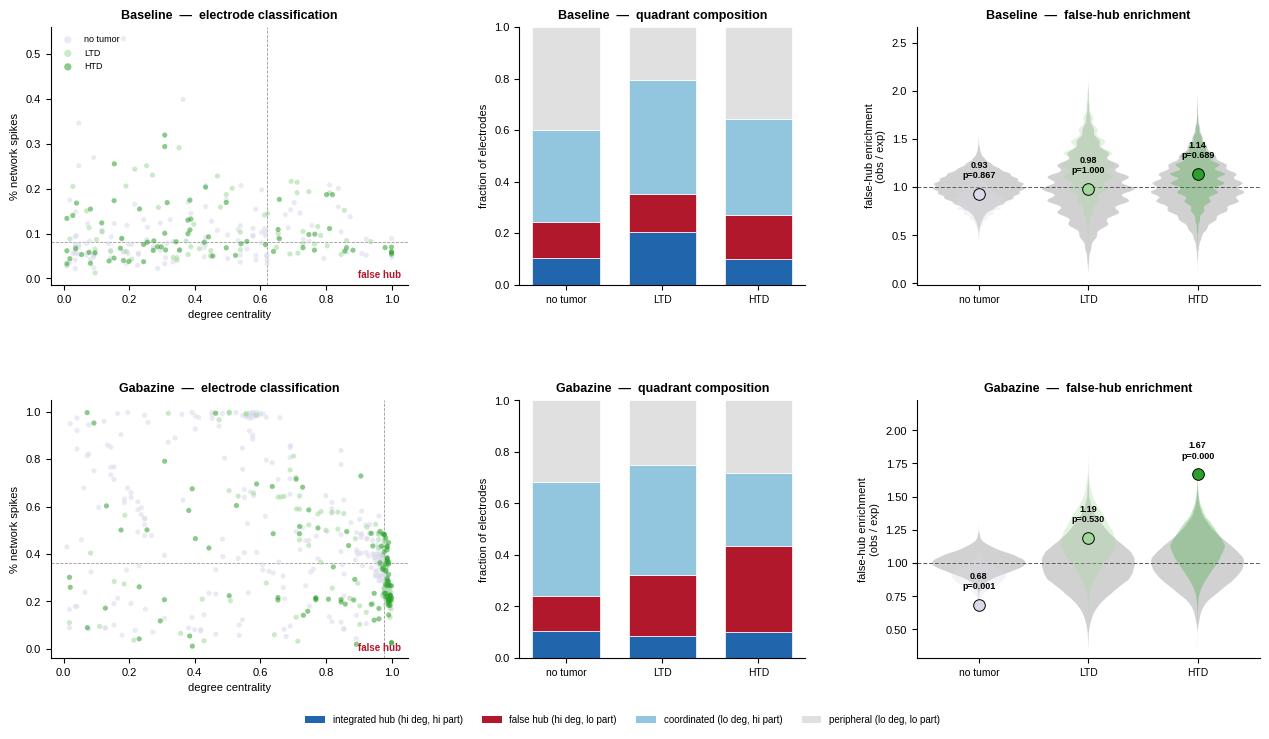

  [hash] 52_quadrant_figure                            96820ee615fb53b3


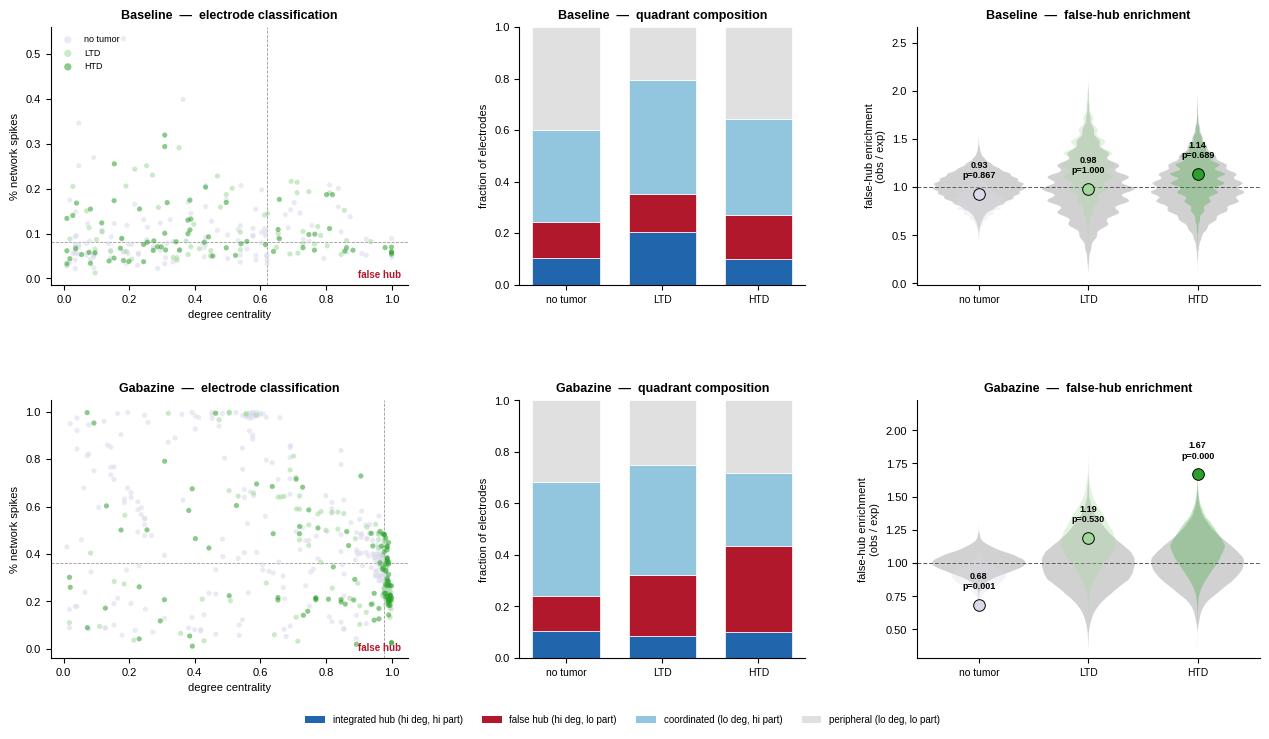

In [29]:
# --- rerun quadrant enrichment, KEEPING the null arrays for plotting --------
def permute_quadrant_enrichment_keep(d, quadrant, region_col='region_experiment',
                                     rate_col='firing_rate',
                                     n_perm=10000, n_rate_bins=10, seed=0):
    d = d.reset_index(drop=True)
    is_q = (d['quadrant'] == quadrant).values
    regions = [r for r in ['control', 'border_zone', 'BTI']
               if r in d[region_col].unique()]
    rmask = {r: (d[region_col] == r).values for r in regions}
    def enrich(flag, m):
        nq = flag.sum()
        return np.nan if nq == 0 else (m & flag).sum()/nq / (m.sum()/len(flag))
    obs = {r: enrich(is_q, rmask[r]) for r in regions}
    rng = np.random.default_rng(seed)
    deciles = pd.qcut(d[rate_col], q=n_rate_bins, labels=False, duplicates='drop').values
    strata = {'global': [np.arange(len(d))],
              'rate':   [np.where(deciles == b)[0] for b in np.unique(deciles)]}
    rows, null_store = [], {}
    for name, idx_sets in strata.items():
        null = {r: np.empty(n_perm) for r in regions}
        for i in range(n_perm):
            sh = is_q.copy()
            for idx in idx_sets:
                sh[idx] = rng.permutation(is_q[idx])
            nq = sh.sum()
            for r in regions:
                null[r][i] = (rmask[r] & sh).sum()/nq / (rmask[r].sum()/len(d))
        for r in regions:
            null_store[(name, r)] = null[r]
            dev = abs(obs[r] - 1.0)
            rows.append({'quadrant': quadrant, 'strata': name, 'region': r,
                         'observed': obs[r],
                         'p': float((np.abs(null[r]-1.0) >= dev).mean())})
    return pd.DataFrame(rows), null_store


quad_enrich_rows, quad_nulls = [], {}
for drug in ['8mMK', '5uMgabazine']:
    for quad in ['false_hub', 'integrated_hub']:
        t, ns = permute_quadrant_enrichment_keep(quad_results[drug]['data'], quad)
        t.insert(0, 'drug', drug)
        quad_enrich_rows.append(t)
        for (strata, region), arr in ns.items():
            quad_nulls[(drug, quad, strata, region)] = arr

quad_enrich = pd.concat(quad_enrich_rows, ignore_index=True)
record("51_quadrant_enrichment", quad_enrich)

fig_quad = plot_quadrant_figure(quad_results, quad_enrich, quad_nulls,
                                save_path=f"{OUT_DIR}/hub_quadrant_figure.svg")
record("52_quadrant_figure", fig_quad)


8mMK — quadrant counts by slice type
quadrant       integrated_hub  false_hub  coordinated  peripheral
experiment                                                       
control_slice              54        111          245         182
BTSC                       31         38           96          87

within-slice-type proportions:
quadrant       integrated_hub  false_hub  coordinated  peripheral
experiment                                                       
control_slice          0.0910     0.1880       0.4140      0.3070
BTSC                   0.1230     0.1510       0.3810      0.3450
  [hash] 54_quadrant_sliceLevel_counts_8mMK            d0423e390142a215
  [hash] 54_quadrant_sliceLevel_props_8mMK             60c72588de83f603

5uMgabazine — quadrant counts by slice type
quadrant       integrated_hub  false_hub  coordinated  peripheral
experiment                                                       
control_slice             113        225          527         407
BTSC           

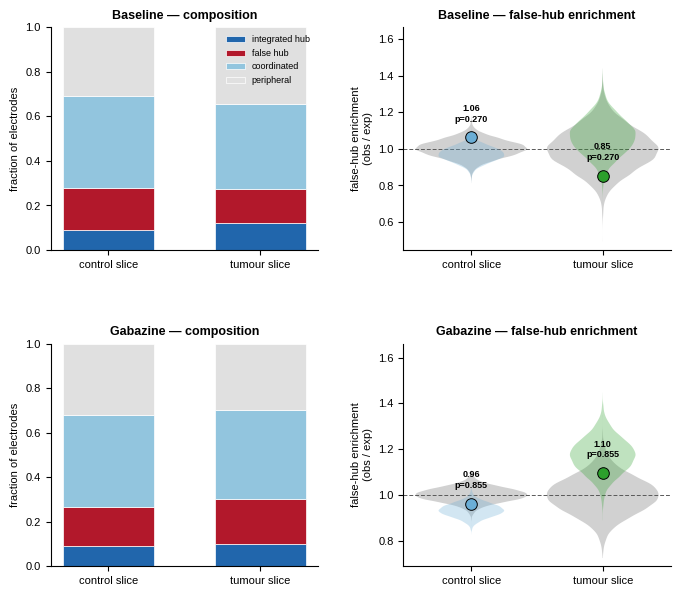

  [hash] 56_quadrant_sliceLevel_figure                 0eba5c4a9c141e09


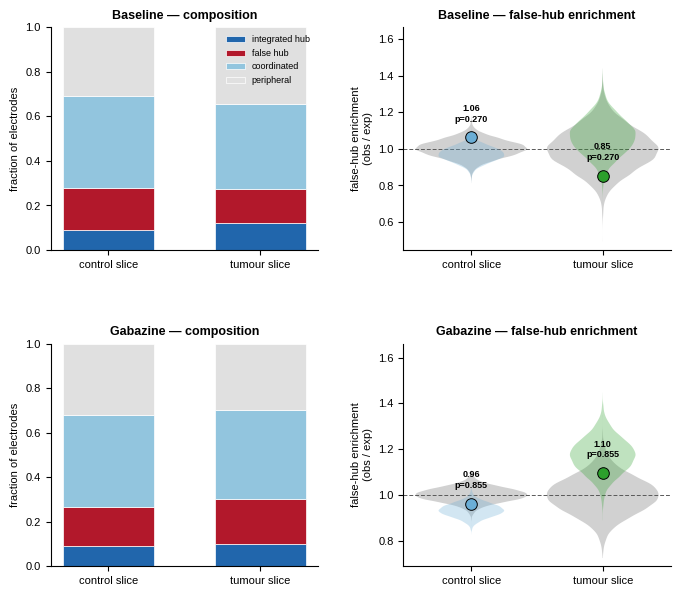

In [30]:
# =============================================================================
# EXPLORATORY: hub quadrants at SLICE level (tumour vs control slice)
# =============================================================================
# Same quadrant logic as the regional analysis, but classified across ALL slices
# and compared by slice type (control_slice vs BTSC) instead of region.
# Curiosity check: is the false-hub excess a slice-wide property or regional?

QUAD_ORDER  = ['integrated_hub', 'false_hub', 'coordinated', 'peripheral']
QUAD_COLORS = {'integrated_hub': '#2166AC', 'false_hub': '#B2182B',
               'coordinated': '#92C5DE', 'peripheral': '#E0E0E0'}


def classify_hub_quadrants_all(nodes_df, drug_condition,
                               deg_col='degree_centrality',
                               part_col='percentage_nonrandom_spikes',
                               deg_pct=25, part_pct=50):
    """Quadrant classification across ALL slices (control_slice + BTSC).
    Per-recording thresholds, as in the regional analysis."""
    d = nodes_df[nodes_df['drug'].str.contains(drug_condition, na=False, case=False)].copy()
    d = d[d[deg_col].notna() & d[part_col].notna()].reset_index(drop=True)

    high_deg  = np.zeros(len(d), dtype=bool)
    high_part = np.zeros(len(d), dtype=bool)
    for fn in d['filename'].unique():
        m = (d['filename'] == fn).values
        high_deg  |= m & (d[deg_col].values  >= np.percentile(d.loc[m, deg_col],  100 - deg_pct))
        high_part |= m & (d[part_col].values >= np.percentile(d.loc[m, part_col], 100 - part_pct))

    d['quadrant'] = np.where(high_deg & high_part,  'integrated_hub',
                    np.where(high_deg & ~high_part, 'false_hub',
                    np.where(~high_deg & high_part, 'coordinated', 'peripheral')))
    d['high_deg'], d['high_part'] = high_deg, high_part
    return d


def permute_quadrant_enrichment_grouped(d, quadrant, group_col,
                                        rate_col='firing_rate',
                                        n_perm=10000, n_rate_bins=10, seed=0):
    """Enrichment of `quadrant` across the levels of `group_col`, with a global
    and a firing-rate-stratified null. Works for any grouping (region or slice
    type). Returns (tidy DataFrame, null-array dict)."""
    d = d.reset_index(drop=True)
    is_q = (d['quadrant'] == quadrant).values
    groups = [g for g in d[group_col].dropna().unique()]
    gmask = {g: (d[group_col] == g).values for g in groups}

    def enrich(flag, m):
        nq = flag.sum()
        return np.nan if nq == 0 else (m & flag).sum()/nq / (m.sum()/len(flag))

    obs = {g: enrich(is_q, gmask[g]) for g in groups}

    rng = np.random.default_rng(seed)
    deciles = pd.qcut(d[rate_col], q=n_rate_bins, labels=False, duplicates='drop').values
    strata = {'global': [np.arange(len(d))],
              'rate':   [np.where(deciles == b)[0] for b in np.unique(deciles)]}

    rows, null_store = [], {}
    for name, idx_sets in strata.items():
        null = {g: np.empty(n_perm) for g in groups}
        for i in range(n_perm):
            sh = is_q.copy()
            for idx in idx_sets:
                sh[idx] = rng.permutation(is_q[idx])
            nq = sh.sum()
            for g in groups:
                null[g][i] = (gmask[g] & sh).sum()/nq / (gmask[g].sum()/len(d))
        for g in groups:
            null_store[(name, g)] = null[g]
            dev = abs(obs[g] - 1.0)
            rows.append({'quadrant': quadrant, 'strata': name, 'group': g,
                         'observed': obs[g],
                         'p': float((np.abs(null[g] - 1.0) >= dev).mean()),
                         'n_quadrant': int(is_q.sum()),
                         'n_group': int(gmask[g].sum())})
    return pd.DataFrame(rows), null_store


# --- run: composition + enrichment by slice type ----------------------------
SLICE_ORDER  = ['control_slice', 'BTSC']
SLICE_LABELS = {'control_slice': 'control slice', 'BTSC': 'tumour slice'}

slice_quad_results, slice_quad_rows, slice_quad_nulls = {}, [], {}
for drug in ['8mMK', '5uMgabazine']:
    d = classify_hub_quadrants_all(nodes_thresh, drug)
    slice_quad_results[drug] = d

    prop = (pd.crosstab(d['experiment'], d['quadrant'], normalize='index')
              .reindex(index=SLICE_ORDER, columns=QUAD_ORDER))
    counts = (pd.crosstab(d['experiment'], d['quadrant'])
                .reindex(index=SLICE_ORDER, columns=QUAD_ORDER))

    print("\n" + "=" * 60)
    print(f"{drug} — quadrant counts by slice type")
    print("=" * 60)
    print(counts.fillna(0).astype(int).to_string())
    print("\nwithin-slice-type proportions:")
    print(prop.round(3).to_string())

    record(f"54_quadrant_sliceLevel_counts_{drug}", counts.fillna(0).astype(int))
    record(f"54_quadrant_sliceLevel_props_{drug}", prop.fillna(0))

    for quad in ['false_hub', 'integrated_hub']:
        t, ns = permute_quadrant_enrichment_grouped(d, quad, group_col='experiment')
        t.insert(0, 'drug', drug)
        slice_quad_rows.append(t)
        for (strata, grp), arr in ns.items():
            slice_quad_nulls[(drug, quad, strata, grp)] = arr

slice_quad_enrich = pd.concat(slice_quad_rows, ignore_index=True)
record("55_quadrant_sliceLevel_enrichment", slice_quad_enrich)

print("\n" + "=" * 60)
print("False-hub enrichment by slice type (global + rate-stratified)")
print("=" * 60)
print(slice_quad_enrich[slice_quad_enrich['quadrant'] == 'false_hub']
      .pivot_table(index=['drug', 'group'], columns='strata',
                   values=['observed', 'p']).round(4).to_string())


# --- figure: composition + false-hub enrichment, per drug -------------------
with plt.rc_context({'font.family': FONT, 'pdf.fonttype': 42,
                     'svg.fonttype': 'none', 'font.size': 8}):
    fig, axes = plt.subplots(2, 2, figsize=(8, 7),
                             gridspec_kw={'hspace': 0.42, 'wspace': 0.32})

    for r, drug in enumerate(['8mMK', '5uMgabazine']):
        d = slice_quad_results[drug]
        prop = (pd.crosstab(d['experiment'], d['quadrant'], normalize='index')
                  .reindex(index=SLICE_ORDER, columns=QUAD_ORDER))

        # left: stacked composition
        ax = axes[r, 0]
        bottom = np.zeros(len(SLICE_ORDER)); x = np.arange(len(SLICE_ORDER))
        for quad in QUAD_ORDER:
            vals = prop[quad].fillna(0).values
            ax.bar(x, vals, bottom=bottom, width=0.6, color=QUAD_COLORS[quad],
                   edgecolor='white', linewidth=0.5,
                   label=quad.replace('_', ' ') if r == 0 else None)
            bottom += vals
        ax.set_xticks(x); ax.set_xticklabels([SLICE_LABELS[s] for s in SLICE_ORDER],
                                             fontsize=8)
        ax.set_ylim(0, 1); ax.set_ylabel('fraction of electrodes', fontsize=8)
        ax.set_title(f'{DRUG_LABELS[drug]} — composition', fontsize=9, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        if r == 0:
            ax.legend(fontsize=6.5, frameon=False, loc='upper right')

        # right: false-hub enrichment vs both nulls
        ax = axes[r, 1]
        ax.axhline(1.0, color='0.35', lw=0.7, ls=(0, (4, 2)), zorder=1)
        sub = slice_quad_enrich[(slice_quad_enrich['drug'] == drug) &
                                (slice_quad_enrich['quadrant'] == 'false_hub')]
        colr = {'control_slice': '#6BAED6', 'BTSC': '#2CA02C'}
        for k, grp in enumerate(SLICE_ORDER):
            for strata, width, fc, alpha, z in [('global', 0.85, '0.82', 1.0, 0),
                                                ('rate', 0.5, colr[grp], 0.30, 2)]:
                nk = (drug, 'false_hub', strata, grp)
                if nk in slice_quad_nulls:
                    vp = ax.violinplot(slice_quad_nulls[nk], positions=[k],
                                       widths=width, showextrema=False)
                    for b in vp['bodies']:
                        b.set_facecolor(fc); b.set_edgecolor('none')
                        b.set_alpha(alpha); b.set_zorder(z)
            row = sub[sub['group'] == grp]
            if not row.empty:
                e = row['observed'].iloc[0]
                ax.scatter([k], [e], s=70, color=colr[grp],
                           edgecolor='black', lw=0.7, zorder=4)
                # enrichment value + rate-stratified p above the point
                p_rate = row.loc[row['strata'] == 'rate', 'p']
                p_txt = f"\np={p_rate.iloc[0]:.3f}" if len(p_rate) else ""
                ax.annotate(f"{e:.2f}{p_txt}", (k, e),
                            textcoords='offset points', xytext=(0, 10),
                            ha='center', va='bottom', fontsize=6.5,
                            fontweight='bold')
        ax.set_xticks(range(len(SLICE_ORDER)))
        ax.set_xticklabels([SLICE_LABELS[s] for s in SLICE_ORDER], fontsize=8)
        ax.set_ylabel('false-hub enrichment\n(obs / exp)', fontsize=8)
        ax.set_title(f'{DRUG_LABELS[drug]} — false-hub enrichment',
                     fontsize=9, fontweight='bold')
        ax.set_ylim(top=ax.get_ylim()[1] * 1.12)   # headroom for the labels
        ax.spines[['top', 'right']].set_visible(False)

    for ext in ('svg', 'png', 'pdf'):
        fig.savefig(f"{OUT_DIR}/quadrant_sliceLevel.{ext}", dpi=300,
                    bbox_inches='tight')
    plt.show()
record("56_quadrant_sliceLevel_figure", fig)

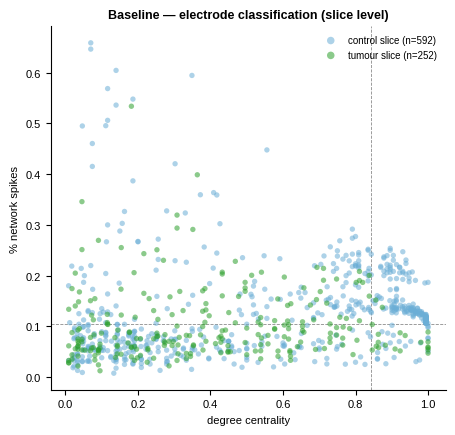

  [hash] 58_quadrant_scatter_slice_8mMK                69cf3281fc7b3db9


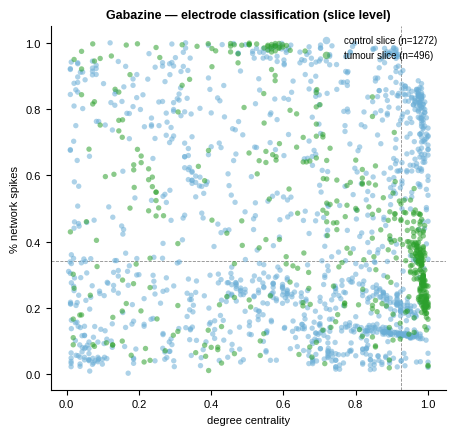

  [hash] 58_quadrant_scatter_slice_gabazine            8001c58c63d5a5ee


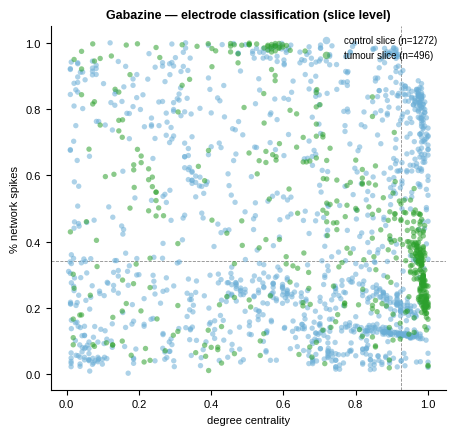

In [31]:
# =============================================================================
# QUADRANT SCATTER — slice level, raw axes (one plot per drug)
# =============================================================================
# One dot = one electrode, coloured by slice type (control_slice vs BTSC).
# Raw degree / participation axes. Dashed guide lines at the pooled top-25%
# degree and top-50% participation cut. Uses slice_quad_results (all slices).

SLICE_LABELS = {'control_slice': 'control slice', 'BTSC': 'tumour slice'}
SLICE_COLORS = {'control_slice': '#6BAED6', 'BTSC': '#2CA02C'}
DRUG_LABELS  = {'8mMK': 'Baseline', '5uMgabazine': 'Gabazine'}


def plot_quadrant_scatter_slice_raw(slice_quad_results, drug,
                                    deg_col='degree_centrality',
                                    part_col='percentage_nonrandom_spikes',
                                    deg_pct=25, part_pct=50, save_path=None):
    d = slice_quad_results[drug].copy()
    xthr = np.percentile(d[deg_col], 100 - deg_pct)
    ythr = np.percentile(d[part_col], 100 - part_pct)

    with plt.rc_context({'font.family': FONT, 'pdf.fonttype': 42,
                         'svg.fonttype': 'none', 'font.size': 8}):
        fig, ax = plt.subplots(figsize=(4.6, 4.4))

        ax.axvline(xthr, color='0.55', lw=0.6, ls='--', zorder=1)
        ax.axhline(ythr, color='0.55', lw=0.6, ls='--', zorder=1)

        for stype in ['control_slice', 'BTSC']:
            sub = d[d['experiment'] == stype]
            ax.scatter(sub[deg_col], sub[part_col], s=15,
                       color=SLICE_COLORS[stype], edgecolor='none', alpha=0.55,
                       zorder=2, label=f"{SLICE_LABELS[stype]} (n={len(sub)})")

        ax.set_xlabel('degree centrality', fontsize=8)
        ax.set_ylabel('% network spikes', fontsize=8)
        ax.set_title(f'{DRUG_LABELS[drug]} — electrode classification (slice level)',
                     fontsize=9, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(fontsize=7, frameon=False, loc='upper right', markerscale=1.4)
        fig.tight_layout()

        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'), dpi=300,
                            bbox_inches='tight')
        plt.show()
    return fig


fig_base = plot_quadrant_scatter_slice_raw(
    slice_quad_results, '8mMK',
    save_path=f"{OUT_DIR}/quadrant_scatter_slice_8mMK.svg")
record("58_quadrant_scatter_slice_8mMK", fig_base)

fig_gbz = plot_quadrant_scatter_slice_raw(
    slice_quad_results, '5uMgabazine',
    save_path=f"{OUT_DIR}/quadrant_scatter_slice_gabazine.svg")
record("58_quadrant_scatter_slice_gabazine", fig_gbz)

# additional ANALYSIS activity driven hubs


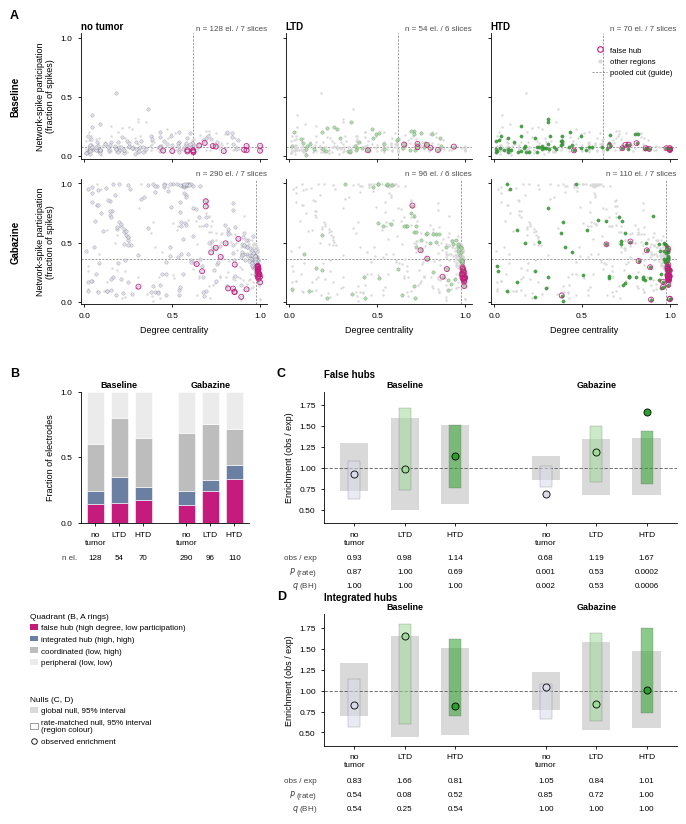

  [hash] 52b_quadrant_figure_pub                       911ce698d65b941b


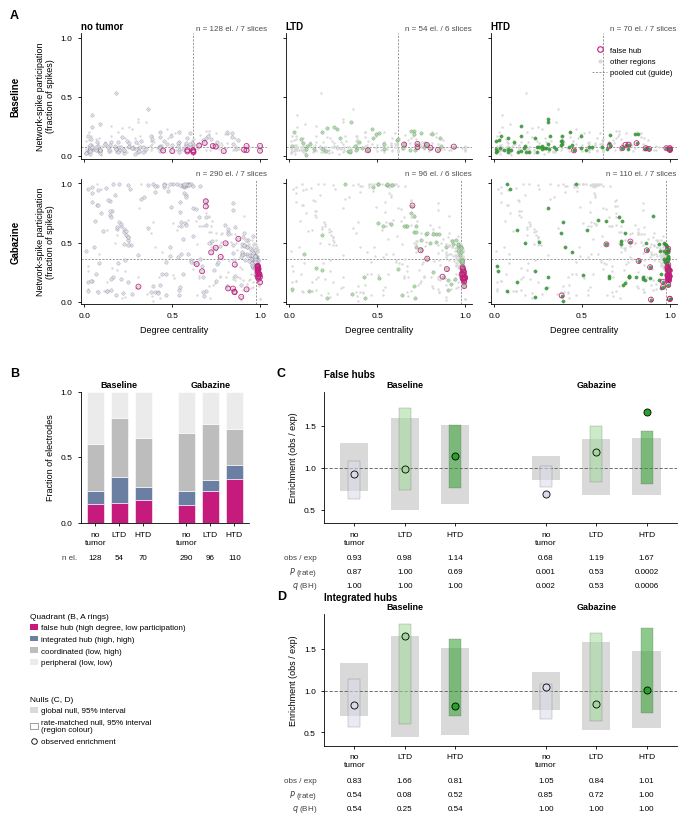

In [32]:
# =============================================================================
# HUB QUADRANT FIGURE — rebuilt to scientific-figure rules (Cell double column)
# =============================================================================
# Uses the SAME inputs as plot_quadrant_figure: quad_results, quad_enrich,
# quad_nulls. No analysis is changed. Display-only additions (flagged):
#   * BH q-values computed for the figure table (within drug x quadrant,
#     across the 3 regions, on the rate-stratified P) — not stored back.
#   * integrated-hub enrichment shown as its own panel (null result).

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from statsmodels.stats.multitest import multipletests

MM = 1 / 25.4

_AVAIL = {f.name for f in fm.fontManager.ttflist}
PUB_FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']
                 if f in _AVAIL), 'sans-serif')

PUB_STYLE = {
    'font.family': PUB_FONT, 'font.size': 6.5,
    'axes.titlesize': 7, 'axes.labelsize': 6.5,
    'xtick.labelsize': 6, 'ytick.labelsize': 6, 'legend.fontsize': 6,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
}

# --- palette table (region colours = the paper's standard scheme) -----------
PUB_REGION_ORDER  = ['control', 'border_zone', 'BTI']
PUB_REGION_LABELS = {'control': 'no tumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
PUB_REGION_TICKS  = {'control': 'no\ntumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
PUB_REGION_COLORS = {'control': '#DADAEB', 'border_zone': '#A1D99B', 'BTI': '#2CA02C'}
PUB_REGION_EDGE   = '#555555'          # lets the pale no-tumor colour read on white
PUB_CONTEXT       = '#D9D9D9'          # all other electrodes (context)
PUB_FALSE_HUB     = '#C51B7D'          # protagonist; magenta = colour-blind safe vs green
PUB_QUAD_ORDER    = ['false_hub', 'integrated_hub', 'coordinated', 'peripheral']  # stack bottom->top
PUB_QUAD_COLORS   = {'false_hub': PUB_FALSE_HUB, 'integrated_hub': '#6B7FA3',
                     'coordinated': '#BDBDBD', 'peripheral': '#EBEBEB'}
PUB_QUAD_LABELS   = {'false_hub': 'false hub (high degree, low participation)',
                     'integrated_hub': 'integrated hub (high, high)',
                     'coordinated': 'coordinated (low, high)',
                     'peripheral': 'peripheral (low, low)'}
PUB_DRUGS         = ['8mMK', '5uMgabazine']
PUB_DRUG_LABELS   = {'8mMK': 'Baseline', '5uMgabazine': 'Gabazine'}


def _fmt_p(p, n_perm=10000):
    if p < 1.0 / n_perm:
        return f"<{1.0 / n_perm:.4f}"
    if p < 0.001:
        return f"{p:.4f}"
    if p < 0.01:
        return f"{p:.3f}"
    return f"{p:.2f}"


def _panel_letter(fig, ax, letter, dx_mm=-9, dy_mm=3):
    tr = ax.transAxes + mpl.transforms.ScaledTranslation(dx_mm * MM, dy_mm * MM,
                                                         fig.dpi_scale_trans)
    ax.text(0, 1, letter, transform=tr, fontsize=9, fontweight='bold',
            va='bottom', ha='left')


def _x_positions(gap=0.8):
    xpos, cursor = {}, 0.0
    for drug in PUB_DRUGS:
        for region in PUB_REGION_ORDER:
            xpos[(drug, region)] = cursor
            cursor += 1.0
        cursor += gap
    return xpos


def _setup_group_axis(ax, xpos):
    ticks = [xpos[(d, r)] for d in PUB_DRUGS for r in PUB_REGION_ORDER]
    ax.set_xticks(ticks)
    ax.set_xticklabels([PUB_REGION_TICKS[r] for d in PUB_DRUGS for r in PUB_REGION_ORDER])
    ax.set_xlim(min(ticks) - 0.6, max(ticks) + 0.6)
    for drug in PUB_DRUGS:
        xs = [xpos[(drug, r)] for r in PUB_REGION_ORDER]
        ax.text(np.mean(xs), 1.02, PUB_DRUG_LABELS[drug],
                transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=6.5, fontweight='bold')


def _value_table(ax, xpos, rows, y0=-0.27, dy=-0.105):
    """rows: list of (row_label, {(drug, region): text}). Drawn under the x axis,
    aligned to the ticks (like an at-risk table)."""
    tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for i, (label, vals) in enumerate(rows):
        y = y0 + i * dy
        ax.text(-0.02, y, label, transform=ax.transAxes, ha='right', va='center',
                fontsize=5.8, color='0.25')
        for key, txt in vals.items():
            ax.text(xpos[key], y, txt, transform=tr, ha='center', va='center',
                    fontsize=5.8)


def _bh_rate_q(quad_enrich, n_perm=10000):
    """BH within drug x quadrant (3 regions) on the rate-stratified P. Display only."""
    t = quad_enrich[quad_enrich['strata'] == 'rate'].copy()
    t['q_bh'] = np.nan
    for _, idx in t.groupby(['drug', 'quadrant']).groups.items():
        p = t.loc[idx, 'p'].clip(lower=1.0 / n_perm).values
        t.loc[idx, 'q_bh'] = multipletests(p, method='fdr_bh')[1]
    return t[['drug', 'quadrant', 'region', 'q_bh']]


def _enrichment_panel(ax, quadrant, quad_enrich, nulls, xpos, qtab, ylim):
    ax.axhline(1.0, color='0.35', lw=0.6, ls=(0, (4, 2)), zorder=1)
    obs_row, p_row, q_row = {}, {}, {}
    for drug in PUB_DRUGS:
        for region in PUB_REGION_ORDER:
            x = xpos[(drug, region)]
            for strata, width, color, z in [('global', 0.56, PUB_CONTEXT, 0),
                                            ('rate',   0.24, PUB_REGION_COLORS[region], 1)]:
                arr = nulls.get((drug, quadrant, strata, region))
                if arr is None:
                    continue
                lo, hi = np.percentile(arr, [2.5, 97.5])
                ax.bar(x, hi - lo, bottom=lo, width=width, color=color,
                       alpha=1.0 if strata == 'global' else 0.55,
                       edgecolor=PUB_REGION_EDGE if strata == 'rate' else 'none',
                       linewidth=0.3, zorder=z)
            sel = quad_enrich[(quad_enrich['drug'] == drug) &
                              (quad_enrich['quadrant'] == quadrant) &
                              (quad_enrich['region'] == region)]
            if sel.empty:
                continue
            e = sel['observed'].iloc[0]
            p = sel.loc[sel['strata'] == 'rate', 'p'].iloc[0]
            q = qtab[(qtab['drug'] == drug) & (qtab['quadrant'] == quadrant) &
                     (qtab['region'] == region)]['q_bh'].iloc[0]
            ax.scatter([x], [e], s=26, color=PUB_REGION_COLORS[region],
                       edgecolor='black', linewidth=0.6, zorder=3)
            obs_row[(drug, region)] = f"{e:.2f}"
            p_row[(drug, region)]   = _fmt_p(p)
            q_row[(drug, region)]   = _fmt_p(q)
    ax.set_ylim(*ylim)
    _setup_group_axis(ax, xpos)
    ax.set_ylabel('Enrichment (obs / exp)')
    _value_table(ax, xpos, [('obs / exp', obs_row),
                            (r'$P$ (rate)', p_row),
                            (r'$q$ (BH)', q_row)])


def plot_quadrant_figure_pub(quad_results, quad_enrich, quad_nulls,
                             deg_col='degree_centrality',
                             part_col='percentage_nonrandom_spikes',
                             deg_pct=25, part_pct=50, save_path=None):
    xpos = _x_positions()
    qtab = _bh_rate_q(quad_enrich)

    # shared enrichment y-range for C and D (identical scales)
    vals = list(quad_enrich['observed'].dropna())
    for arr in quad_nulls.values():
        vals += list(np.percentile(arr, [2.5, 97.5]))
    ylo, yhi = min(vals), max(vals)
    pad = 0.08 * (yhi - ylo)
    ylim_enrich = (max(0, ylo - pad), yhi + pad)

    with plt.rc_context(PUB_STYLE):
        fig = plt.figure(figsize=(174 * MM, 222 * MM))

        # ---- A: scatter small multiples (rows = drug, cols = region) --------
        gsA = fig.add_gridspec(2, 3, left=0.115, right=0.985, top=0.955, bottom=0.645,
                               wspace=0.10, hspace=0.16)
        axA = np.empty((2, 3), dtype=object)
        for r, drug in enumerate(PUB_DRUGS):
            d = quad_results[drug]['data']
            xthr = np.percentile(d[deg_col], 100 - deg_pct)
            ythr = np.percentile(d[part_col], 100 - part_pct)
            for c, region in enumerate(PUB_REGION_ORDER):
                ax = fig.add_subplot(gsA[r, c])
                axA[r, c] = ax
                other = d[d['region_experiment'] != region]
                sub   = d[d['region_experiment'] == region]
                fh    = sub[sub['quadrant'] == 'false_hub']
                ax.scatter(other[deg_col], other[part_col], s=3, color=PUB_CONTEXT,
                           linewidth=0, rasterized=True, zorder=1)
                ax.scatter(sub[deg_col], sub[part_col], s=6,
                           color=PUB_REGION_COLORS[region], edgecolor=PUB_REGION_EDGE,
                           linewidth=0.15, alpha=0.9, rasterized=True, zorder=2)
                ax.scatter(fh[deg_col], fh[part_col], s=13, facecolor='none',
                           edgecolor=PUB_FALSE_HUB, linewidth=0.55,
                           rasterized=True, zorder=3)
                ax.axvline(xthr, color='0.45', lw=0.5, ls=(0, (3, 2)), zorder=0)
                ax.axhline(ythr, color='0.45', lw=0.5, ls=(0, (3, 2)), zorder=0)
                ax.set_xlim(-0.02, 1.04); ax.set_ylim(-0.02, 1.04)
                ax.set_xticks([0, 0.5, 1.0]); ax.set_yticks([0, 0.5, 1.0])
                n_el, n_sl = len(sub), sub['filename'].nunique()
                ax.text(1.0, 1.01, f"n = {n_el} el. / {n_sl} slices",
                        transform=ax.transAxes, ha='right', va='bottom', fontsize=5.8,
                        color='0.3')
                if r == 0:
                    ax.set_title(PUB_REGION_LABELS[region], fontweight='bold',
                                 loc='left', pad=3)
                if r == 1:
                    ax.set_xlabel('Degree centrality')
                else:
                    ax.tick_params(labelbottom=False)
                if c == 0:
                    ax.set_ylabel('Network-spike participation\n(fraction of spikes)')
                    pos = ax.get_position()
                    fig.text(0.012, (pos.y0 + pos.y1) / 2, PUB_DRUG_LABELS[drug],
                             rotation=90, ha='left', va='center',
                             fontsize=7, fontweight='bold')
                else:
                    ax.tick_params(labelleft=False)
        _panel_letter(fig, axA[0, 0], 'A', dx_mm=-18)
        axA[0, 2].legend(
            handles=[Line2D([0], [0], marker='o', ls='', mfc='none',
                            mec=PUB_FALSE_HUB, mew=0.8, ms=4, label='false hub'),
                     Line2D([0], [0], marker='o', ls='', mfc=PUB_CONTEXT,
                            mec='none', ms=3, label='other regions'),
                     Line2D([0], [0], color='0.45', lw=0.5, ls=(0, (3, 2)),
                            label='pooled cut (guide)')],
            loc='upper right', bbox_to_anchor=(1.0, 0.93), handletextpad=0.3,
            borderaxespad=0.2, fontsize=5.6, frameon=False)

        # ---- B: quadrant composition ---------------------------------------
        axB = fig.add_axes([0.115, 0.395, 0.245, 0.15])
        n_row = {}
        for drug in PUB_DRUGS:
            prop = quad_results[drug]['proportions'].reindex(PUB_REGION_ORDER)
            d = quad_results[drug]['data']
            for region in PUB_REGION_ORDER:
                x, bottom = xpos[(drug, region)], 0.0
                for quad in PUB_QUAD_ORDER:
                    v = float(prop.loc[region, quad]) if quad in prop.columns else 0.0
                    v = 0.0 if np.isnan(v) else v
                    axB.bar(x, v, bottom=bottom, width=0.7,
                            color=PUB_QUAD_COLORS[quad], edgecolor='white', linewidth=0.4)
                    bottom += v
                n_row[(drug, region)] = str((d['region_experiment'] == region).sum())
        axB.set_ylim(0, 1); axB.set_yticks([0, 0.5, 1.0])
        axB.set_ylabel('Fraction of electrodes')
        _setup_group_axis(axB, xpos)
        _value_table(axB, xpos, [('n el.', n_row)])
        _panel_letter(fig, axB, 'B', dx_mm=-18)
        fig.legend(handles=[Patch(facecolor=PUB_QUAD_COLORS[q], label=PUB_QUAD_LABELS[q])
                            for q in PUB_QUAD_ORDER],
                   title='Quadrant (B, A rings)', title_fontsize=6, loc='upper left',
                   bbox_to_anchor=(0.03, 0.30), handlelength=1.0, handletextpad=0.4,
                   fontsize=5.8, alignment='left', frameon=False)
        fig.legend(handles=[Patch(facecolor=PUB_CONTEXT, label='global null, 95% interval'),
                            Patch(facecolor='white', edgecolor=PUB_REGION_EDGE, lw=0.4,
                                  label='rate-matched null, 95% interval\n(region colour)'),
                            Line2D([0], [0], marker='o', ls='', mfc='white', mec='black',
                                   mew=0.6, ms=4, label='observed enrichment')],
                   title='Nulls (C, D)', title_fontsize=6, loc='upper left',
                   bbox_to_anchor=(0.03, 0.205), handlelength=1.0, handletextpad=0.4,
                   fontsize=5.8, alignment='left', frameon=False)

        # ---- C: false-hub enrichment ---------------------------------------
        axC = fig.add_axes([0.47, 0.395, 0.515, 0.15])
        _enrichment_panel(axC, 'false_hub', quad_enrich, quad_nulls, xpos, qtab, ylim_enrich)
        axC.set_title('False hubs', fontweight='bold', loc='left', pad=10)
        _panel_letter(fig, axC, 'C', dx_mm=-12)

        # ---- D: integrated-hub enrichment (null result, same care) ----------
        axD = fig.add_axes([0.47, 0.14, 0.515, 0.15])
        _enrichment_panel(axD, 'integrated_hub', quad_enrich, quad_nulls, xpos, qtab,
                          ylim_enrich)
        axD.set_title('Integrated hubs', fontweight='bold', loc='left', pad=10)
        _panel_letter(fig, axD, 'D', dx_mm=-12)

        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'), dpi=600)
        plt.show()
    return fig


fig_quad_pub = plot_quadrant_figure_pub(quad_results, quad_enrich, quad_nulls,
                                        save_path=f"{OUT_DIR}/hub_quadrant_figure_pub.svg")
record("52b_quadrant_figure_pub", fig_quad_pub)

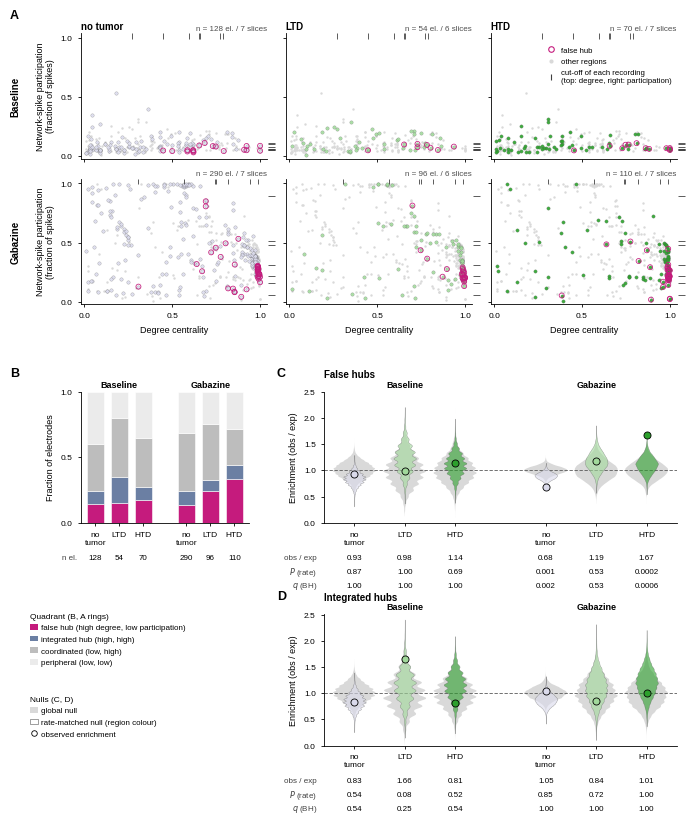

  [overwrite] 52b_quadrant_figure_pub changed within this run
  [hash] 52b_quadrant_figure_pub                       8c6872c17e7a5a9d


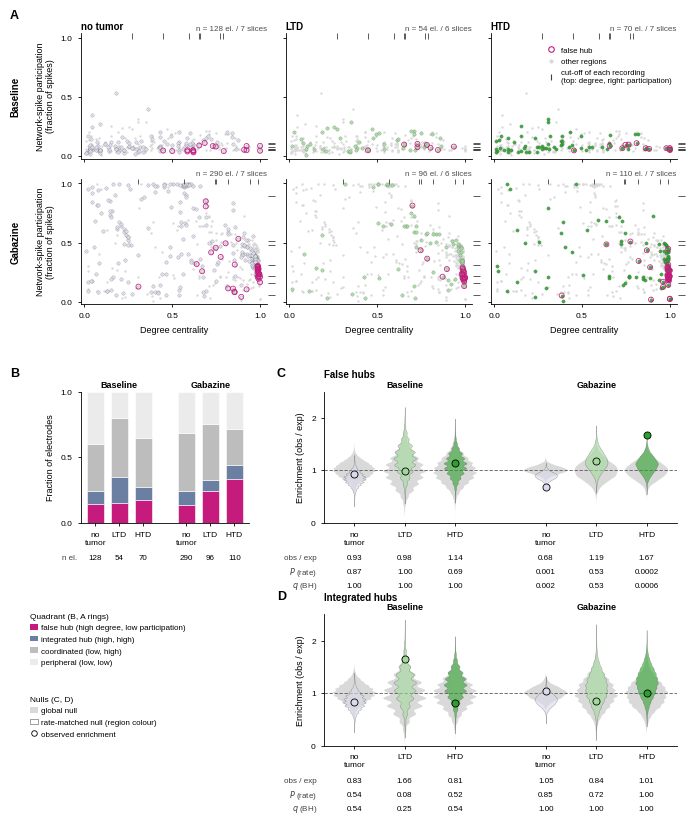

In [33]:
# =============================================================================
# HUB QUADRANT FIGURE — rebuilt to scientific-figure rules (Cell double column)
# =============================================================================
# Uses the SAME inputs as plot_quadrant_figure: quad_results, quad_enrich,
# quad_nulls. No analysis is changed. Display-only additions (flagged):
#   * BH q-values computed for the figure table (within drug x quadrant,
#     across the 3 regions, on the rate-stratified P) — not stored back.
#   * integrated-hub enrichment shown as its own panel (null result).
# Panel A marks each recording's own cut-offs as short ticks on the top edge
# (degree) and right edge (participation) instead of one pooled guide line.

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from statsmodels.stats.multitest import multipletests

MM = 1 / 25.4

_AVAIL = {f.name for f in fm.fontManager.ttflist}
PUB_FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans']
                 if f in _AVAIL), 'sans-serif')

PUB_STYLE = {
    'font.family': PUB_FONT, 'font.size': 6.5,
    'axes.titlesize': 7, 'axes.labelsize': 6.5,
    'xtick.labelsize': 6, 'ytick.labelsize': 6, 'legend.fontsize': 6,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
}

# --- palette table (region colours = the paper's standard scheme) -----------
PUB_REGION_ORDER  = ['control', 'border_zone', 'BTI']
PUB_REGION_LABELS = {'control': 'no tumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
PUB_REGION_TICKS  = {'control': 'no\ntumor', 'border_zone': 'LTD', 'BTI': 'HTD'}
PUB_REGION_COLORS = {'control': '#DADAEB', 'border_zone': '#A1D99B', 'BTI': '#2CA02C'}
PUB_REGION_EDGE   = '#555555'          # lets the pale no-tumor colour read on white
PUB_CONTEXT       = '#D9D9D9'          # all other electrodes (context)
PUB_FALSE_HUB     = '#C51B7D'          # protagonist; magenta = colour-blind safe vs green
PUB_QUAD_ORDER    = ['false_hub', 'integrated_hub', 'coordinated', 'peripheral']  # stack bottom->top
PUB_QUAD_COLORS   = {'false_hub': PUB_FALSE_HUB, 'integrated_hub': '#6B7FA3',
                     'coordinated': '#BDBDBD', 'peripheral': '#EBEBEB'}
PUB_QUAD_LABELS   = {'false_hub': 'false hub (high degree, low participation)',
                     'integrated_hub': 'integrated hub (high, high)',
                     'coordinated': 'coordinated (low, high)',
                     'peripheral': 'peripheral (low, low)'}
PUB_DRUGS         = ['8mMK', '5uMgabazine']
PUB_DRUG_LABELS   = {'8mMK': 'Baseline', '5uMgabazine': 'Gabazine'}


def _fmt_p(p, n_perm=10000):
    if p < 1.0 / n_perm:
        return f"<{1.0 / n_perm:.4f}"
    if p < 0.001:
        return f"{p:.4f}"
    if p < 0.01:
        return f"{p:.3f}"
    return f"{p:.2f}"


def _panel_letter(fig, ax, letter, dx_mm=-9, dy_mm=3):
    tr = ax.transAxes + mpl.transforms.ScaledTranslation(dx_mm * MM, dy_mm * MM,
                                                         fig.dpi_scale_trans)
    ax.text(0, 1, letter, transform=tr, fontsize=9, fontweight='bold',
            va='bottom', ha='left')


def _x_positions(gap=0.8):
    xpos, cursor = {}, 0.0
    for drug in PUB_DRUGS:
        for region in PUB_REGION_ORDER:
            xpos[(drug, region)] = cursor
            cursor += 1.0
        cursor += gap
    return xpos


def _setup_group_axis(ax, xpos):
    ticks = [xpos[(d, r)] for d in PUB_DRUGS for r in PUB_REGION_ORDER]
    ax.set_xticks(ticks)
    ax.set_xticklabels([PUB_REGION_TICKS[r] for d in PUB_DRUGS for r in PUB_REGION_ORDER])
    ax.set_xlim(min(ticks) - 0.6, max(ticks) + 0.6)
    for drug in PUB_DRUGS:
        xs = [xpos[(drug, r)] for r in PUB_REGION_ORDER]
        ax.text(np.mean(xs), 1.02, PUB_DRUG_LABELS[drug],
                transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=6.5, fontweight='bold')


def _value_table(ax, xpos, rows, y0=-0.27, dy=-0.105):
    """rows: list of (row_label, {(drug, region): text}). Drawn under the x axis,
    aligned to the ticks (like an at-risk table)."""
    tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for i, (label, vals) in enumerate(rows):
        y = y0 + i * dy
        ax.text(-0.02, y, label, transform=ax.transAxes, ha='right', va='center',
                fontsize=5.8, color='0.25')
        for key, txt in vals.items():
            ax.text(xpos[key], y, txt, transform=tr, ha='center', va='center',
                    fontsize=5.8)


def _bh_rate_q(quad_enrich, n_perm=10000):
    """BH within drug x quadrant (3 regions) on the rate-stratified P. Display only."""
    t = quad_enrich[quad_enrich['strata'] == 'rate'].copy()
    t['q_bh'] = np.nan
    for _, idx in t.groupby(['drug', 'quadrant']).groups.items():
        p = t.loc[idx, 'p'].clip(lower=1.0 / n_perm).values
        t.loc[idx, 'q_bh'] = multipletests(p, method='fdr_bh')[1]
    return t[['drug', 'quadrant', 'region', 'q_bh']]


def _enrichment_panel(ax, quadrant, quad_enrich, nulls, xpos, qtab, ylim):
    ax.axhline(1.0, color='0.35', lw=0.6, ls=(0, (4, 2)), zorder=1)
    obs_row, p_row, q_row = {}, {}, {}
    for drug in PUB_DRUGS:
        for region in PUB_REGION_ORDER:
            x = xpos[(drug, region)]
            for strata, width, color, alpha, ec, z in [
                    ('global', 0.85, PUB_CONTEXT, 1.0, 'none', 0),
                    ('rate',   0.45, PUB_REGION_COLORS[region], 0.6, PUB_REGION_EDGE, 1)]:
                arr = nulls.get((drug, quadrant, strata, region))
                if arr is None:
                    continue
                vp = ax.violinplot(np.asarray(arr), positions=[x], widths=width,
                                   showextrema=False)
                for b in vp['bodies']:
                    b.set_facecolor(color); b.set_edgecolor(ec)
                    b.set_linewidth(0.3); b.set_alpha(alpha); b.set_zorder(z)
            sel = quad_enrich[(quad_enrich['drug'] == drug) &
                              (quad_enrich['quadrant'] == quadrant) &
                              (quad_enrich['region'] == region)]
            if sel.empty:
                continue
            e = sel['observed'].iloc[0]
            p = sel.loc[sel['strata'] == 'rate', 'p'].iloc[0]
            q = qtab[(qtab['drug'] == drug) & (qtab['quadrant'] == quadrant) &
                     (qtab['region'] == region)]['q_bh'].iloc[0]
            ax.scatter([x], [e], s=26, color=PUB_REGION_COLORS[region],
                       edgecolor='black', linewidth=0.6, zorder=3)
            obs_row[(drug, region)] = f"{e:.2f}"
            p_row[(drug, region)]   = _fmt_p(p)
            q_row[(drug, region)]   = _fmt_p(q)
    ax.set_ylim(*ylim)
    _setup_group_axis(ax, xpos)
    ax.set_ylabel('Enrichment (obs / exp)')
    _value_table(ax, xpos, [('obs / exp', obs_row),
                            (r'$P$ (rate)', p_row),
                            (r'$q$ (BH)', q_row)])


def plot_quadrant_figure_pub(quad_results, quad_enrich, quad_nulls,
                             deg_col='degree_centrality',
                             part_col='percentage_nonrandom_spikes',
                             deg_pct=25, part_pct=50, save_path=None):
    xpos = _x_positions()
    qtab = _bh_rate_q(quad_enrich)

    # shared enrichment y-range for C and D (identical scales)
    vals = list(quad_enrich['observed'].dropna())
    for arr in quad_nulls.values():
        vals += [float(np.min(arr)), float(np.max(arr))]
    ylo, yhi = min(vals), max(vals)
    pad = 0.04 * (yhi - ylo)
    ylim_enrich = (max(0, ylo - pad), yhi + pad)

    with plt.rc_context(PUB_STYLE):
        fig = plt.figure(figsize=(174 * MM, 222 * MM))

        # ---- A: scatter small multiples (rows = drug, cols = region) --------
        gsA = fig.add_gridspec(2, 3, left=0.115, right=0.985, top=0.955, bottom=0.645,
                               wspace=0.10, hspace=0.16)
        axA = np.empty((2, 3), dtype=object)
        for r, drug in enumerate(PUB_DRUGS):
            d = quad_results[drug]['data']
            # the cut-offs actually used: one pair per recording
            cuts = d.groupby('filename').agg(
                deg=(deg_col,  lambda v: np.percentile(v, 100 - deg_pct)),
                part=(part_col, lambda v: np.percentile(v, 100 - part_pct)))
            for c, region in enumerate(PUB_REGION_ORDER):
                ax = fig.add_subplot(gsA[r, c])
                axA[r, c] = ax
                other = d[d['region_experiment'] != region]
                sub   = d[d['region_experiment'] == region]
                fh    = sub[sub['quadrant'] == 'false_hub']
                ax.scatter(other[deg_col], other[part_col], s=3, color=PUB_CONTEXT,
                           linewidth=0, rasterized=True, zorder=1)
                ax.scatter(sub[deg_col], sub[part_col], s=6,
                           color=PUB_REGION_COLORS[region], edgecolor=PUB_REGION_EDGE,
                           linewidth=0.15, alpha=0.9, rasterized=True, zorder=2)
                ax.scatter(fh[deg_col], fh[part_col], s=13, facecolor='none',
                           edgecolor=PUB_FALSE_HUB, linewidth=0.55,
                           rasterized=True, zorder=3)
                tr_x = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
                tr_y = mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData)
                for xc in cuts['deg']:
                    ax.plot([xc, xc], [0.955, 1.0], transform=tr_x, color='0.25',
                            lw=0.6, solid_capstyle='butt', zorder=4)
                for yc in cuts['part']:
                    ax.plot([1.005, 1.045], [yc, yc], transform=tr_y, color='0.25',
                            lw=0.6, solid_capstyle='butt', clip_on=False, zorder=4)
                ax.set_xlim(-0.02, 1.04); ax.set_ylim(-0.02, 1.04)
                ax.set_xticks([0, 0.5, 1.0]); ax.set_yticks([0, 0.5, 1.0])
                n_el, n_sl = len(sub), sub['filename'].nunique()
                ax.text(1.0, 1.01, f"n = {n_el} el. / {n_sl} slices",
                        transform=ax.transAxes, ha='right', va='bottom', fontsize=5.8,
                        color='0.3')
                if r == 0:
                    ax.set_title(PUB_REGION_LABELS[region], fontweight='bold',
                                 loc='left', pad=3)
                if r == 1:
                    ax.set_xlabel('Degree centrality')
                else:
                    ax.tick_params(labelbottom=False)
                if c == 0:
                    ax.set_ylabel('Network-spike participation\n(fraction of spikes)')
                    pos = ax.get_position()
                    fig.text(0.012, (pos.y0 + pos.y1) / 2, PUB_DRUG_LABELS[drug],
                             rotation=90, ha='left', va='center',
                             fontsize=7, fontweight='bold')
                else:
                    ax.tick_params(labelleft=False)
        _panel_letter(fig, axA[0, 0], 'A', dx_mm=-18)
        axA[0, 2].legend(
            handles=[Line2D([0], [0], marker='o', ls='', mfc='none',
                            mec=PUB_FALSE_HUB, mew=0.8, ms=4, label='false hub'),
                     Line2D([0], [0], marker='o', ls='', mfc=PUB_CONTEXT,
                            mec='none', ms=3, label='other regions'),
                     Line2D([0], [0], marker='|', ls='', color='0.25', mew=0.8, ms=5,
                            label='cut-off of each recording\n(top: degree, right: participation)')],
            loc='upper right', bbox_to_anchor=(1.0, 0.93), handletextpad=0.3,
            borderaxespad=0.2, fontsize=5.6, frameon=False)

        # ---- B: quadrant composition ---------------------------------------
        axB = fig.add_axes([0.115, 0.395, 0.245, 0.15])
        n_row = {}
        for drug in PUB_DRUGS:
            prop = quad_results[drug]['proportions'].reindex(PUB_REGION_ORDER)
            d = quad_results[drug]['data']
            for region in PUB_REGION_ORDER:
                x, bottom = xpos[(drug, region)], 0.0
                for quad in PUB_QUAD_ORDER:
                    v = float(prop.loc[region, quad]) if quad in prop.columns else 0.0
                    v = 0.0 if np.isnan(v) else v
                    axB.bar(x, v, bottom=bottom, width=0.7,
                            color=PUB_QUAD_COLORS[quad], edgecolor='white', linewidth=0.4)
                    bottom += v
                n_row[(drug, region)] = str((d['region_experiment'] == region).sum())
        axB.set_ylim(0, 1); axB.set_yticks([0, 0.5, 1.0])
        axB.set_ylabel('Fraction of electrodes')
        _setup_group_axis(axB, xpos)
        _value_table(axB, xpos, [('n el.', n_row)])
        _panel_letter(fig, axB, 'B', dx_mm=-18)
        fig.legend(handles=[Patch(facecolor=PUB_QUAD_COLORS[q], label=PUB_QUAD_LABELS[q])
                            for q in PUB_QUAD_ORDER],
                   title='Quadrant (B, A rings)', title_fontsize=6, loc='upper left',
                   bbox_to_anchor=(0.03, 0.30), handlelength=1.0, handletextpad=0.4,
                   fontsize=5.8, alignment='left', frameon=False)
        fig.legend(handles=[Patch(facecolor=PUB_CONTEXT, label='global null'),
                            Patch(facecolor='white', edgecolor=PUB_REGION_EDGE, lw=0.4,
                                  label='rate-matched null (region colour)'),
                            Line2D([0], [0], marker='o', ls='', mfc='white', mec='black',
                                   mew=0.6, ms=4, label='observed enrichment')],
                   title='Nulls (C, D)', title_fontsize=6, loc='upper left',
                   bbox_to_anchor=(0.03, 0.205), handlelength=1.0, handletextpad=0.4,
                   fontsize=5.8, alignment='left', frameon=False)

        # ---- C: false-hub enrichment ---------------------------------------
        axC = fig.add_axes([0.47, 0.395, 0.515, 0.15])
        _enrichment_panel(axC, 'false_hub', quad_enrich, quad_nulls, xpos, qtab, ylim_enrich)
        axC.set_title('False hubs', fontweight='bold', loc='left', pad=10)
        _panel_letter(fig, axC, 'C', dx_mm=-12)

        # ---- D: integrated-hub enrichment (null result, same care) ----------
        axD = fig.add_axes([0.47, 0.14, 0.515, 0.15])
        _enrichment_panel(axD, 'integrated_hub', quad_enrich, quad_nulls, xpos, qtab,
                          ylim_enrich)
        axD.set_title('Integrated hubs', fontweight='bold', loc='left', pad=10)
        _panel_letter(fig, axD, 'D', dx_mm=-12)

        if save_path:
            for ext in ('svg', 'png', 'pdf'):
                fig.savefig(save_path.replace('.svg', f'.{ext}'), dpi=600)
        plt.show()
    return fig


fig_quad_pub = plot_quadrant_figure_pub(quad_results, quad_enrich, quad_nulls,
                                        save_path=f"{OUT_DIR}/hub_quadrant_figure_pub.svg")
record("52b_quadrant_figure_pub", fig_quad_pub)